In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [58]:
df_countries_hpi = pd.read_parquet('../data/clean_hpi.parquet')
df_countries_hpi.head()

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,...,Slovenia,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom
0,2010,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,99.9975,100.0025,100.0000,...,99.9975,100.0000,99.9975,100.0025,100.0025,100.0000,100.0000,100.0000,100.00,100.0000
1,2011,97.8450,104.2250,103.5825,119.0225,94.4900,105.7500,112.2300,104.1175,107.8900,...,102.7150,103.5900,105.2275,92.3550,102.5800,107.5100,104.2625,108.8000,97.24,98.5450
2,2012,97.5325,117.1325,106.0150,133.0600,92.6900,110.6150,124.0250,103.4225,118.7925,...,95.6325,108.4075,108.2500,78.7075,103.8650,113.7225,107.6325,120.6750,101.82,98.9200
3,2013,103.9925,122.5900,107.5900,145.3175,90.6500,112.7600,136.5175,109.5550,130.0650,...,90.6200,115.4075,107.8000,71.5250,109.2225,118.3000,115.9925,134.4625,111.83,101.4550
4,2014,113.4075,126.7900,107.2250,155.3575,91.9475,118.8625,154.7200,112.3775,140.7525,...,84.6400,123.9875,109.4325,71.7450,119.5200,121.4650,127.0725,151.2500,118.88,109.6025


In [18]:
df_clusters = pd.read_parquet('../data/clusters/clusters_kmean_random.parquet')
df_clusters.head()

,Country,iso_a3,cluster
0,Australia,AUS,1
1,Austria,AUT,0
2,Belgium,BEL,0
3,Brazil,BRA,1
4,Bulgaria,BGR,0


In [4]:
df_clusters.shape

(53, 3)

In [7]:
import geopandas as gpd

In [8]:
world = gpd.read_file("../data/geo_data/ne_110m_admin_0_countries.shp")
world.head()

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,None,None,None,None,None,None,None,None,None,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,None,None,Unrecognized,None,None,None,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


In [9]:
print(list(world.columns))

['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3', 'ADM0_DIF', 'LEVEL', 'TYPE', 'TLC', 'ADMIN', 'ADM0_A3', 'GEOU_DIF', 'GEOUNIT', 'GU_A3', 'SU_DIF', 'SUBUNIT', 'SU_A3', 'BRK_DIFF', 'NAME', 'NAME_LONG', 'BRK_A3', 'BRK_NAME', 'BRK_GROUP', 'ABBREV', 'POSTAL', 'FORMAL_EN', 'FORMAL_FR', 'NAME_CIAWF', 'NOTE_ADM0', 'NOTE_BRK', 'NAME_SORT', 'NAME_ALT', 'MAPCOLOR7', 'MAPCOLOR8', 'MAPCOLOR9', 'MAPCOLOR13', 'POP_EST', 'POP_RANK', 'POP_YEAR', 'GDP_MD', 'GDP_YEAR', 'ECONOMY', 'INCOME_GRP', 'FIPS_10', 'ISO_A2', 'ISO_A2_EH', 'ISO_A3', 'ISO_A3_EH', 'ISO_N3', 'ISO_N3_EH', 'UN_A3', 'WB_A2', 'WB_A3', 'WOE_ID', 'WOE_ID_EH', 'WOE_NOTE', 'ADM0_ISO', 'ADM0_DIFF', 'ADM0_TLC', 'ADM0_A3_US', 'ADM0_A3_FR', 'ADM0_A3_RU', 'ADM0_A3_ES', 'ADM0_A3_CN', 'ADM0_A3_TW', 'ADM0_A3_IN', 'ADM0_A3_NP', 'ADM0_A3_PK', 'ADM0_A3_DE', 'ADM0_A3_GB', 'ADM0_A3_BR', 'ADM0_A3_IL', 'ADM0_A3_PS', 'ADM0_A3_SA', 'ADM0_A3_EG', 'ADM0_A3_MA', 'ADM0_A3_PT', 'ADM0_A3_AR', 'ADM0_A3_JP', 'ADM0_A3_KO', 'ADM0_A3_VN', 'ADM0_A3_TR', 'AD

In [20]:
df_clusters = df_clusters.merge(
    world[['ISO_A3', 'CONTINENT']],
    left_on='iso_a3',
    right_on='ISO_A3',
    how='left')
df_clusters.head()

,Country,iso_a3,cluster,ISO_A3,CONTINENT
0,Australia,AUS,1,AUS,Oceania
1,Austria,AUT,0,AUT,Europe
2,Belgium,BEL,0,BEL,Europe
3,Brazil,BRA,1,BRA,South America
4,Bulgaria,BGR,0,BGR,Europe


In [21]:
df_clusters.drop(columns=['ISO_A3'], inplace=True)

In [22]:
df_clusters.tail()

,Country,iso_a3,cluster,CONTINENT
48,Switzerland,CHE,1,Europe
49,Thailand,THA,1,Asia
50,Turkey,TUR,1,Asia
51,United Kingdom,GBR,1,Europe
52,USA,USA,1,North America


In [24]:
df_clusters

,Country,iso_a3,cluster,CONTINENT
0,Australia,AUS,1,Oceania
1,Austria,AUT,0,Europe
2,Belgium,BEL,0,Europe
3,Brazil,BRA,1,South America
4,Bulgaria,BGR,0,Europe
5,Canada,CAN,1,North America
6,Chile,CHL,2,South America
7,Colombia,COL,2,South America
8,Croatia,HRV,0,Europe
9,Cyprus,CYP,0,Asia


In [28]:
world[world['ISO_A3'] == 'SGP']['CONTINENT']

Series([], Name: CONTINENT, dtype: object)

In [29]:
world[world['ISO_A3'] == 'USA']['CONTINENT']

4    North America
Name: CONTINENT, dtype: object

In [31]:
world[world['ISO_A3'] == 'FRA']

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry


In [32]:
world[world['ISO_A3'] == 'USA']

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


In [33]:
df_clusters.loc[df_clusters['iso_a3'] == 'FRA', 'CONTINENT'] = 'Europe'
df_clusters.loc[df_clusters['iso_a3'] == 'MLT', 'CONTINENT'] = 'Europe'
df_clusters.loc[df_clusters['iso_a3'] == 'NOR', 'CONTINENT'] = 'Europe'
df_clusters.loc[df_clusters['iso_a3'] == 'SGP', 'CONTINENT'] = 'Asia'

In [34]:
df_clusters.isna()

,Country,iso_a3,cluster,CONTINENT
0,False,False,False,False
1,False,False,False,False
2,False,False,False,False
3,False,False,False,False
4,False,False,False,False
5,False,False,False,False
6,False,False,False,False
7,False,False,False,False
8,False,False,False,False
9,False,False,False,False


In [36]:
world[world['NAME_EN'] == 'France']['ISO_A3']

43    -99
Name: ISO_A3, dtype: object

In [38]:
world[world['NAME_EN'] == 'Singapore']

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry


In [39]:
df_clusters.to_parquet('../data/clusters/clusters_kmean_random.parquet')

In [40]:
def find_countries_missing_from_clusters(df_hpi, df_clusters, country_column='Country'):
    """
    Identifies which countries are present in the HPI DataFrame but missing from the cluster DataFrame.

    Parameters:
    - df_hpi: DataFrame where columns are country names and rows are years (House Price Index data)
    - df_clusters: DataFrame with country names and cluster assignments
    - country_column: Name of the column in df_clusters that contains country names (default: 'Country')

    Returns:
    - List of country names that are in df_hpi but not in df_clusters
    """

    # Extract country names from HPI DataFrame (column headers)
    hpi_countries = set(df_hpi.columns)

    # Extract country names from cluster DataFrame
    cluster_countries = set(df_clusters[country_column].unique())

    # Find countries present in HPI but missing from clusters
    missing_countries = hpi_countries - cluster_countries

    # Print results
    if missing_countries:
        print("Countries in HPI that are missing from the cluster DataFrame:")
        for country in sorted(missing_countries):
            print(f" - {country}")
    else:
        print("All countries in the HPI DataFrame are present in the cluster DataFrame.")

    return list(missing_countries)

In [41]:
find_countries_missing_from_clusters(df_countries_hpi, df_clusters)

Countries in HPI that are missing from the cluster DataFrame:
 - China
 - Czech-Republic
 - Hong-Kong
 - Indonesia
 - Macedonia
 - Morocco
 - New-Zealand
 - South-Africa
 - South-Korea
 - United-Kingdom
 - Year


['Morocco',
 'Czech-Republic',
 'Year',
 'China',
 'South-Korea',
 'South-Africa',
 'Hong-Kong',
 'United-Kingdom',
 'Indonesia',
 'Macedonia',
 'New-Zealand']

In [42]:
def find_countries_missing_from_clusters(df_hpi, df_clusters, country_column='Country'):
    """
    Identifies which countries are present in the HPI DataFrame but missing from the cluster DataFrame.
    Handles country name formatting differences (e.g., '-' vs ' ') and ignores the year column.

    Parameters:
    - df_hpi: DataFrame where columns are country names and rows are years (House Price Index data)
    - df_clusters: DataFrame with country names and cluster assignments
    - country_column: Name of the column in df_clusters that contains country names (default: 'Country')

    Returns:
    - List of country names that are in df_hpi but not in df_clusters
    """

    # Step 1: Remove the year column (assumed to be the first column)
    hpi_country_columns = df_hpi.columns[1:]

    # Step 2: Normalize country names by replacing '-' with ' '
    hpi_countries = set(col.replace('-', ' ').strip() for col in hpi_country_columns)

    # Step 3: Normalize cluster country names
    cluster_countries = set(df_clusters[country_column].str.strip())

    # Step 4: Find missing countries
    missing_countries = hpi_countries - cluster_countries

    # Step 5: Print results
    if missing_countries:
        print("Countries in HPI that are missing from the cluster DataFrame:")
        for country in sorted(missing_countries):
            print(f" - {country}")
    else:
        print("All countries in the HPI DataFrame are present in the cluster DataFrame.")

    return list(missing_countries)

In [44]:
countries_delete = find_countries_missing_from_clusters(df_countries_hpi, df_clusters)

Countries in HPI that are missing from the cluster DataFrame:
 - China
 - Czech Republic
 - Hong Kong
 - Indonesia
 - Macedonia
 - Morocco


In [45]:
# Supongamos que ya tenés la lista de países faltantes con espacios
# Ejemplo: missing_countries = ['United States', 'South Korea']

# Convertir los nombres con espacios a formato con guiones
columns_to_drop = [country.replace(' ', '-') for country in countries_delete]

# Eliminar esas columnas del DataFrame HPI
df_countries_hpi = df_countries_hpi.drop(columns=columns_to_drop)

In [49]:
df_countries_hpi.shape

(15, 52)

In [50]:
df_clusters.shape

(53, 4)

- dos de mas ya que en df_countries_hpi tenemos columna 'Year' y en df_cluster tenemos valor de 'Paraguay'

In [53]:
print(list(df_countries_hpi.columns))

['Year', 'Australia', 'Austria', 'Belgium', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'Colombia', 'Croatia', 'Cyprus', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'India', 'Ireland', 'Israel', 'Italy', 'Japan', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Mexico', 'Netherlands', 'New-Zealand', 'Norway', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Romania', 'Russia', 'Serbia', 'Singapore', 'Slovakia', 'Slovenia', 'South-Africa', 'South-Korea', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'USA', 'United-Kingdom']


In [55]:
print(list(df_clusters.Country))

['Australia', 'Austria', 'Belgium', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'Colombia', 'Croatia', 'Cyprus', 'Czech', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'India', 'Ireland', 'Israel', 'Italy', 'Japan', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Malta', 'Mexico', 'Netherlands', 'New Zealand', 'Norway', 'Paraguay', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Romania', 'Russia', 'Serbia', 'Singapore', 'Slovakia', 'Slovenia', 'South Africa', 'South Korea', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'United Kingdom', 'USA']


In [56]:
# Reemplazar 'Czech' por 'Czech Republic' en la columna 'Country'
df_clusters['Country'] = df_clusters['Country'].replace({'Czech': 'Czech Republic'})

In [57]:
df_clusters

,Country,iso_a3,cluster,CONTINENT
0,Australia,AUS,1,Oceania
1,Austria,AUT,0,Europe
2,Belgium,BEL,0,Europe
3,Brazil,BRA,1,South America
4,Bulgaria,BGR,0,Europe
5,Canada,CAN,1,North America
6,Chile,CHL,2,South America
7,Colombia,COL,2,South America
8,Croatia,HRV,0,Europe
9,Cyprus,CYP,0,Asia


In [59]:
countries_delete = find_countries_missing_from_clusters(df_countries_hpi, df_clusters)

Countries in HPI that are missing from the cluster DataFrame:
 - China
 - Hong Kong
 - Indonesia
 - Macedonia
 - Morocco


In [60]:
# Supongamos que ya tenés la lista de países faltantes con espacios
# Ejemplo: missing_countries = ['United States', 'South Korea']

# Convertir los nombres con espacios a formato con guiones
columns_to_drop = [country.replace(' ', '-') for country in countries_delete]

# Eliminar esas columnas del DataFrame HPI
df_countries_hpi = df_countries_hpi.drop(columns=columns_to_drop)

In [61]:
countries_delete = find_countries_missing_from_clusters(df_countries_hpi, df_clusters)

All countries in the HPI DataFrame are present in the cluster DataFrame.


In [62]:
df_countries_hpi.shape

(15, 53)

In [63]:
df_clusters.shape

(53, 4)

In [64]:
df_clusters.to_parquet('../data/clusters/clusters_kmean_random.parquet')
df_countries_hpi.to_parquet('../data/clusters/countries_hpi_for_clusters.parquet')

In [65]:
def standardize_country_names(df, column='Country'):
    """
    Replaces spaces with hyphens in country names within the specified column.

    Parameters:
    - df: DataFrame containing country names
    - column: Name of the column to standardize (default: 'Country')

    Returns:
    - DataFrame with standardized country names
    """
    df[column] = df[column].str.replace(' ', '-', regex=False).str.strip()
    return df

In [66]:
df_clusters = standardize_country_names(df_clusters)
df_clusters

,Country,iso_a3,cluster,CONTINENT
0,Australia,AUS,1,Oceania
1,Austria,AUT,0,Europe
2,Belgium,BEL,0,Europe
3,Brazil,BRA,1,South America
4,Bulgaria,BGR,0,Europe
5,Canada,CAN,1,North America
6,Chile,CHL,2,South America
7,Colombia,COL,2,South America
8,Croatia,HRV,0,Europe
9,Cyprus,CYP,0,Asia


In [67]:
df_clusters.to_parquet('../data/clusters/clusters_kmean_random.parquet')

In [68]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'CONTINENT'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['CONTINENT']
            print(f" - {country} ({continent})")

In [69]:
print_cluster_groups(df_clusters)


🌍 Cluster 0 (17 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malta (Europe)
 - New-Zealand (Oceania)
 - Portugal (Europe)
 - Slovakia (Europe)
 - Slovenia (Europe)

🌍 Cluster 1 (29 countries):
 - Australia (Oceania)
 - Brazil (South America)
 - Canada (North America)
 - Czech-Republic (Europe)
 - Denmark (Europe)
 - France (Europe)
 - Germany (Europe)
 - Hungary (Europe)
 - Iceland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Malaysia (Asia)
 - Mexico (North America)
 - Netherlands (Europe)
 - Norway (Europe)
 - Peru (South America)
 - Philippines (Asia)
 - Poland (Europe)
 - Romania (Europe)
 - Serbia (Europe)
 - Singapore (Asia)
 - South-Africa (Africa)
 - Spain (Europe)
 - Sweden (Europe)
 - Switzerland (Europe)
 - Thailand (Asia)
 - Turkey (Asia)
 - United-Kingdom (Europe

In [70]:
import random

In [73]:
def estimate_hpi_by_cluster_sampling(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Estimates synthetic HPI values for a randomly excluded country from a selected cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to use for sampling
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    - sample_size: Size of each sample (default: 30)
    - n_samples: Number of samples to generate (default: 1000)
    - plot: Whether to show histograms for each year (default: True)
    - seed: Optional random seed for reproducibility

    Returns:
    - synthetic_hpi: dict with estimated HPI values per year
    - excluded_country: name of the country left out
    - actual_values: dict with real HPI values of the excluded country
    """

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # Step 1: Get countries in the selected cluster
    cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()

    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries to perform exclusion and sampling.")

    # Step 2: Randomly exclude one country
    excluded_country = random.choice(cluster_countries)
    sampling_countries = [c for c in cluster_countries if c != excluded_country]

    print(f"🔍 Cluster {cluster_id} selected. Excluding country: {excluded_country}")
    print(f"📊 Sampling from countries: {sampling_countries}")

    # Step 3: Prepare output containers
    synthetic_hpi = {}
    actual_values = {}

    # Step 4: Iterate over each year
    for _, row in df_hpi.iterrows():
        year = row[year_column]

        # Get HPI values for sampling countries
        values = row[sampling_countries].dropna().values

        # Get actual value of excluded country
        actual_value = row.get(excluded_country, np.nan)
        actual_values[year] = actual_value

        if len(values) == 0:
            print(f"⚠️ No HPI data available for cluster peers in year {year}")
            synthetic_hpi[year] = np.nan
            continue

        # Generate sampling distribution
        sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                        for _ in range(n_samples)]

        # Plot distribution
        if plot:
            plt.figure(figsize=(8, 4))
            plt.hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
            plt.axvline(actual_value, color='red', linestyle='--', label=f"Actual: {excluded_country}")
            plt.title(f"HPI Sampling Distribution - Year {year}")
            plt.xlabel("Sample Mean HPI")
            plt.ylabel("Frequency")
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()

        # Store synthetic HPI value
        synthetic_hpi[year] = np.mean(sample_means)

    return synthetic_hpi, excluded_country, actual_values

🔍 Cluster 0 selected. Excluding country: Croatia
📊 Sampling from countries: ['Austria', 'Belgium', 'Bulgaria', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'New-Zealand', 'Portugal', 'Slovakia', 'Slovenia']


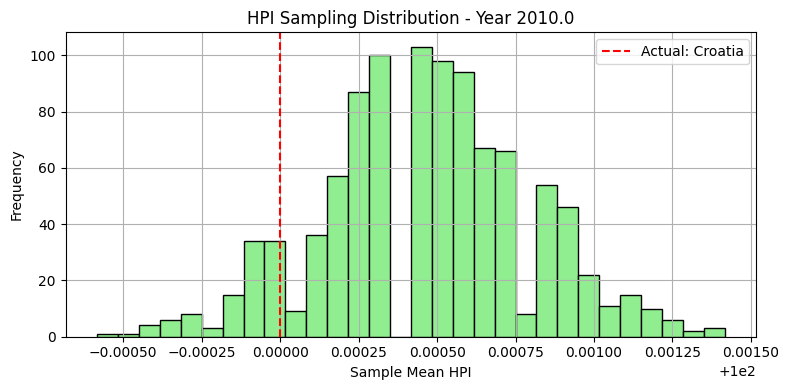

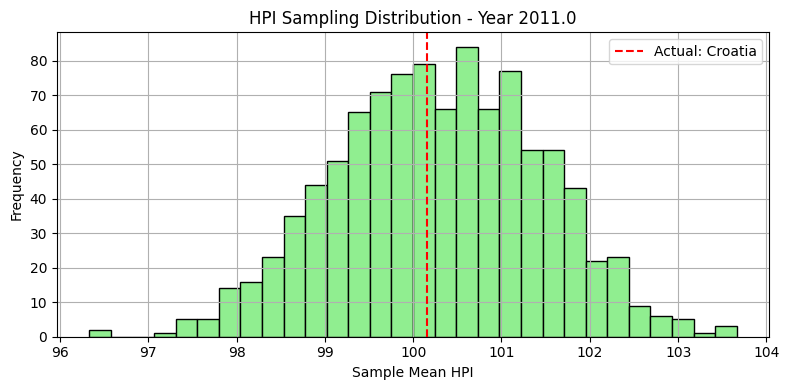

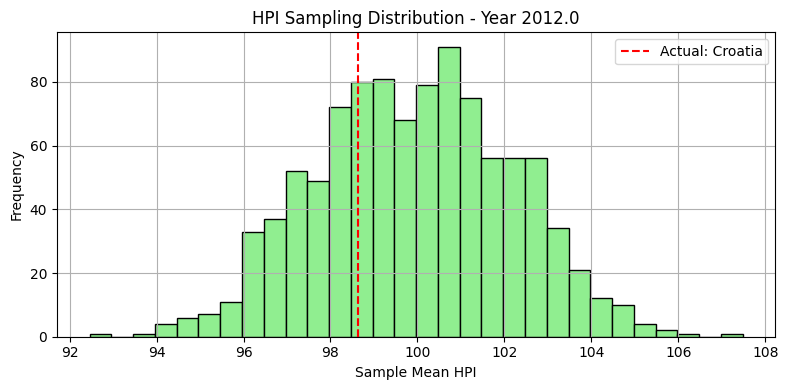

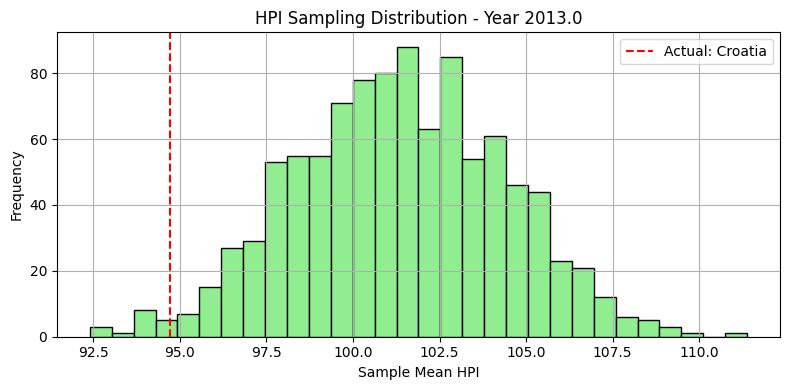

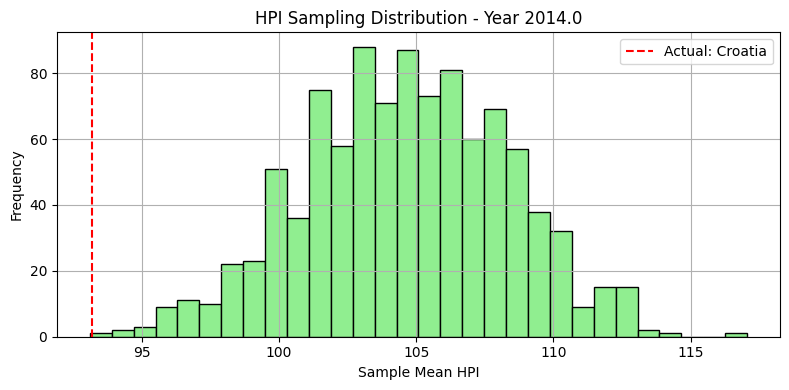

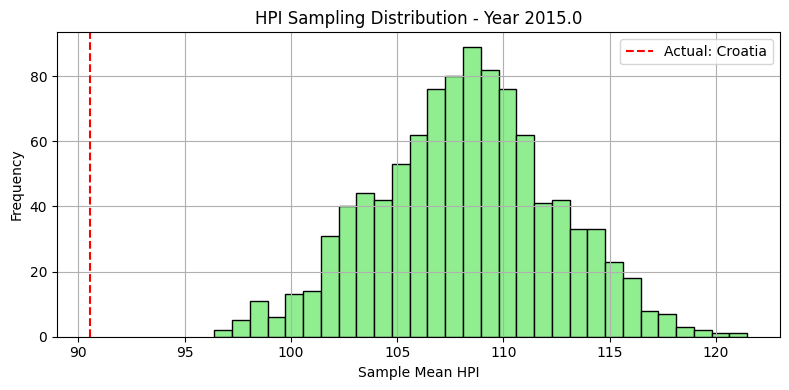

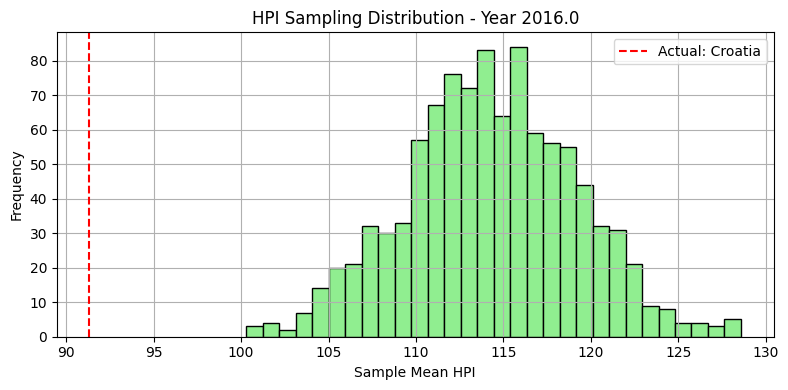

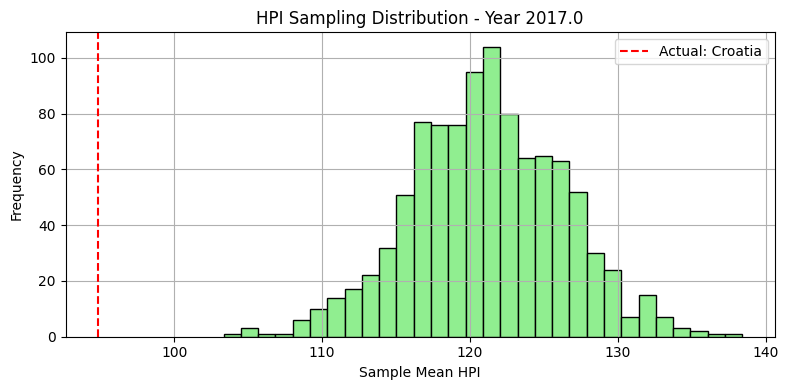

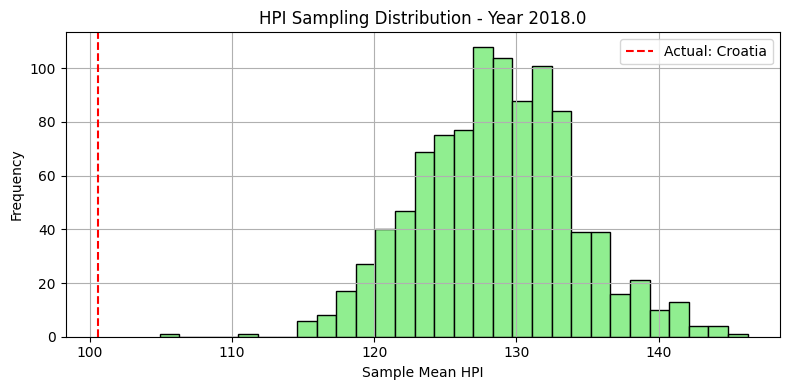

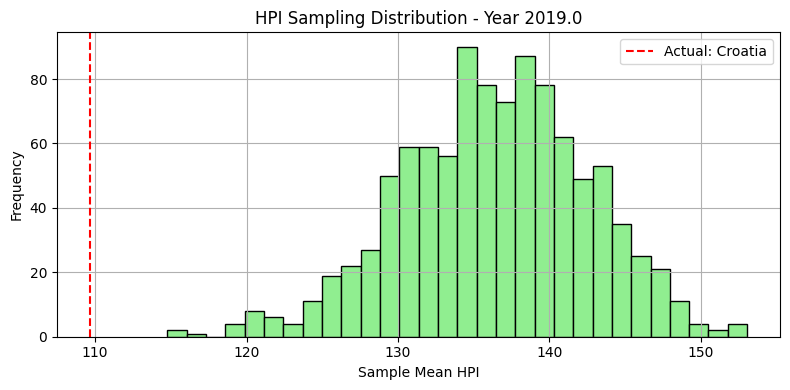

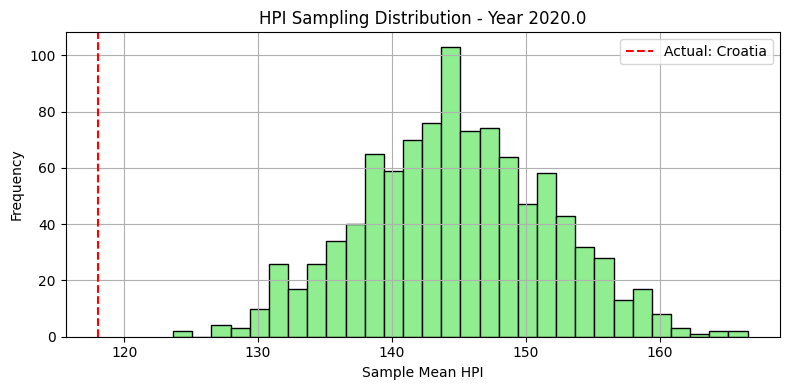

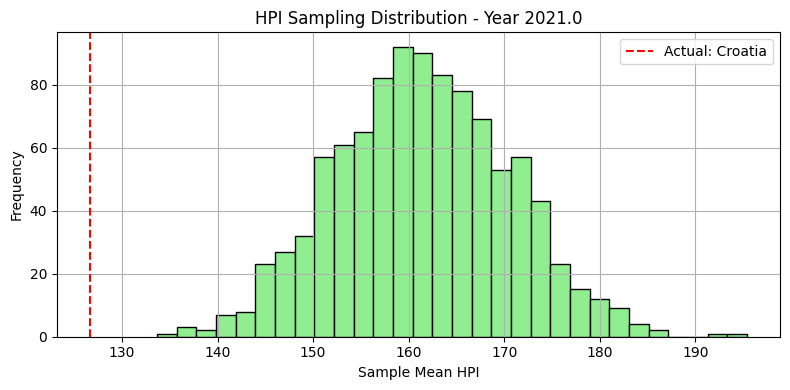

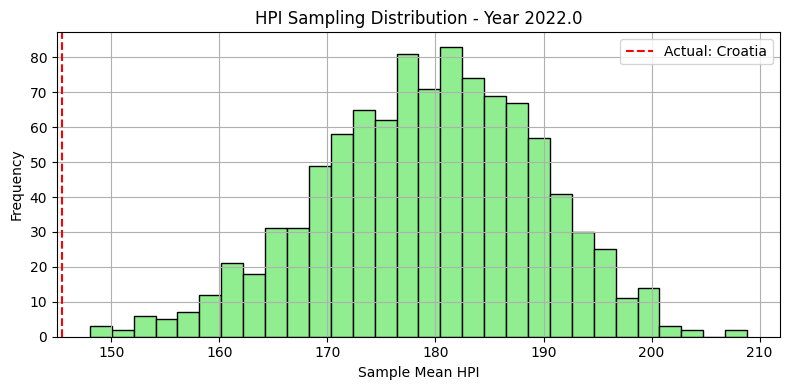

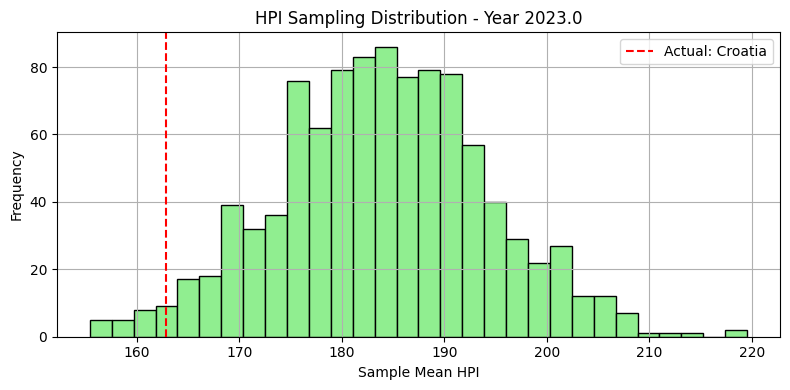

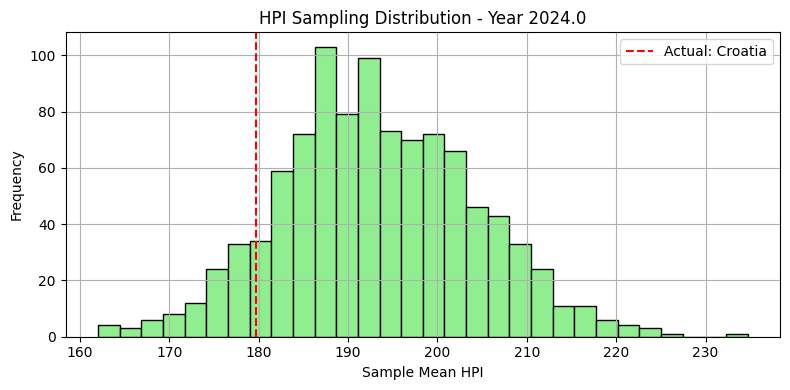

In [74]:
synthetic, excluded, actual = estimate_hpi_by_cluster_sampling(df_countries_hpi, df_clusters, cluster_id=0, seed=42)

In [75]:
df_countries_hpi

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,...,Slovenia,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom
0,2010,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,99.9975,100.0000,100.0000,...,99.9975,100.0000,99.9975,100.0025,100.0025,100.0000,100.0000,100.0000,100.0000,100.0000
1,2011,97.8450,104.2250,103.5825,119.0225,94.4900,105.7500,112.2300,107.8900,100.1575,...,102.7150,103.5900,105.2275,92.3550,102.5800,107.5100,104.2625,108.8000,97.2400,98.5450
2,2012,97.5325,117.1325,106.0150,133.0600,92.6900,110.6150,124.0250,118.7925,98.6225,...,95.6325,108.4075,108.2500,78.7075,103.8650,113.7225,107.6325,120.6750,101.8200,98.9200
3,2013,103.9925,122.5900,107.5900,145.3175,90.6500,112.7600,136.5175,130.0650,94.7050,...,90.6200,115.4075,107.8000,71.5250,109.2225,118.3000,115.9925,134.4625,111.8300,101.4550
4,2014,113.4075,126.7900,107.2250,155.3575,91.9475,118.8625,154.7200,140.7525,93.1875,...,84.6400,123.9875,109.4325,71.7450,119.5200,121.4650,127.0725,151.2500,118.8800,109.6025
5,2015,123.6450,132.0575,109.1675,156.1650,94.5100,128.4275,174.9375,152.9325,90.5400,...,85.3200,131.7975,113.0825,74.3200,135.2000,124.0775,135.9950,175.0850,125.1800,116.1250
6,2016,130.4450,141.7575,111.7175,151.9450,101.1475,148.6600,186.4325,167.4825,91.3325,...,88.0950,138.2250,116.0900,77.7550,146.3425,124.3200,142.4050,197.4625,131.8825,124.2700
7,2017,141.3350,147.0825,115.6650,149.0200,109.9125,172.2950,201.6525,178.5650,94.8375,...,95.3750,143.9375,117.5950,82.5700,156.0625,125.4250,146.4775,218.8125,139.6050,129.9250
8,2018,139.3050,157.2350,119.1575,149.8125,117.1525,178.2375,221.8375,188.2425,100.5900,...,103.7050,148.9600,120.2225,88.1275,154.5975,129.1550,153.9000,235.9525,147.3475,134.0400
9,2019,133.6400,163.4250,123.6175,155.0550,124.2050,179.4000,240.5325,198.3700,109.6425,...,110.6525,152.6875,121.9325,92.6875,158.4350,133.9900,155.0950,247.2950,153.1450,135.3700


In [76]:
df_countries_hpi.isna().any().any()

np.False_

🔍 Cluster 1 selected. Excluding country: Singapore
📊 Sampling from countries: ['Australia', 'Brazil', 'Canada', 'Czech-Republic', 'Denmark', 'France', 'Germany', 'Hungary', 'Iceland', 'Israel', 'Italy', 'Malaysia', 'Mexico', 'Netherlands', 'Norway', 'Peru', 'Philippines', 'Poland', 'Romania', 'Serbia', 'South-Africa', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'United-Kingdom', 'USA']


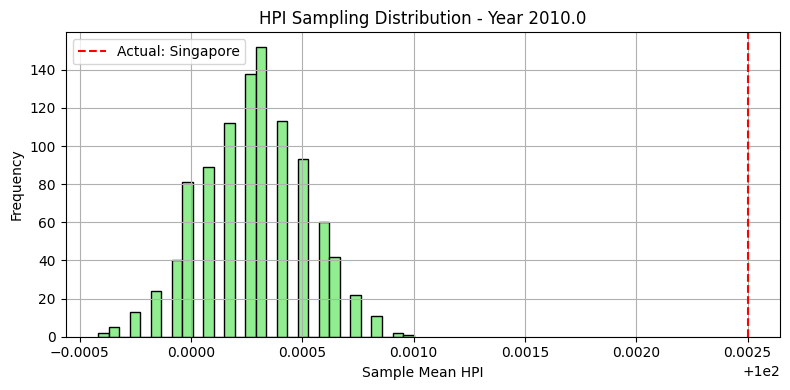

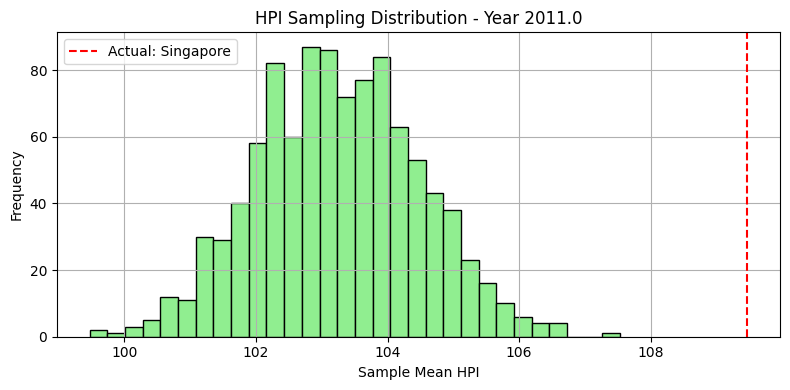

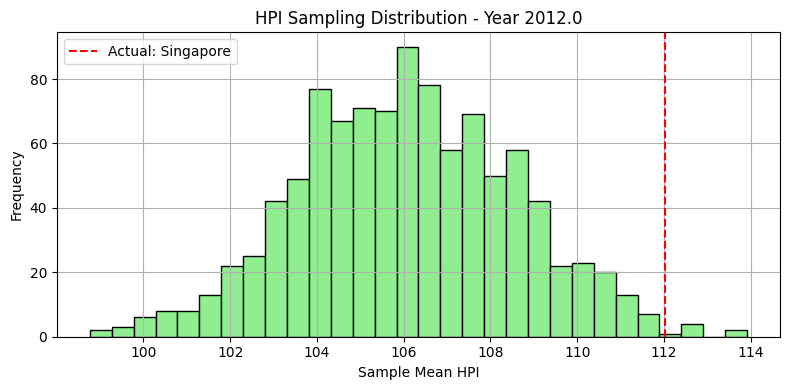

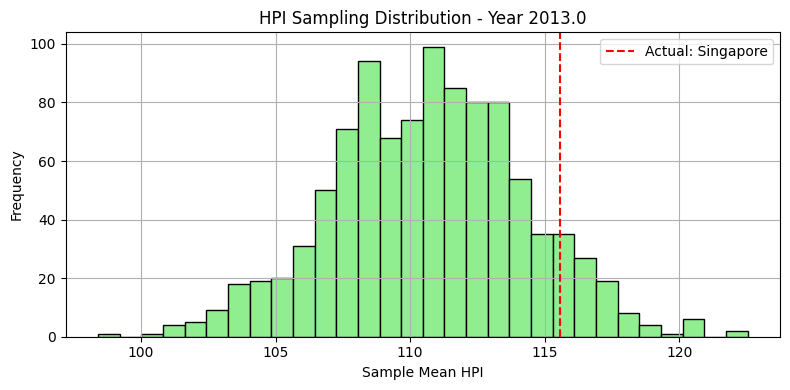

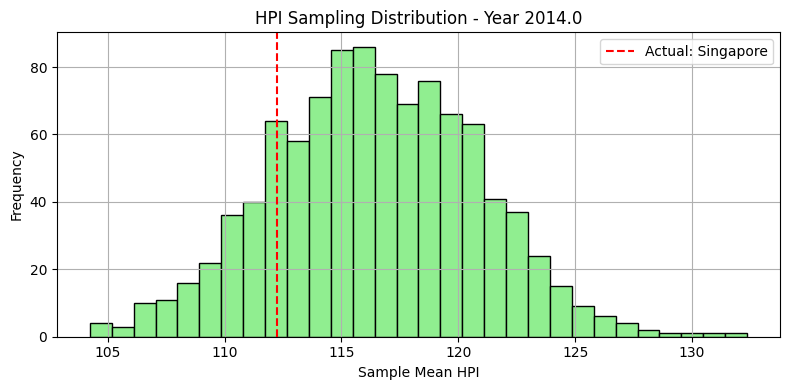

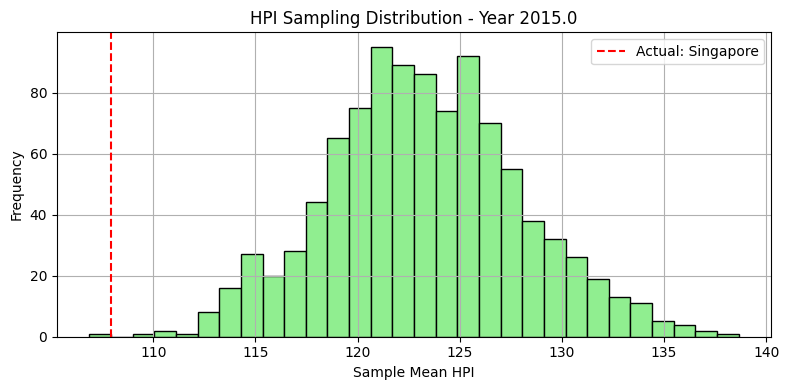

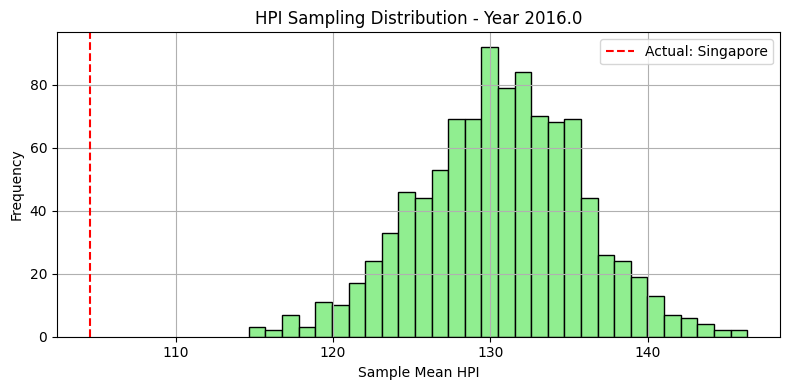

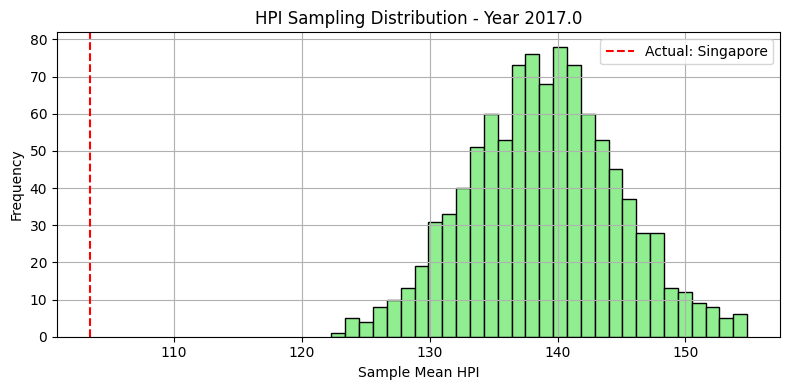

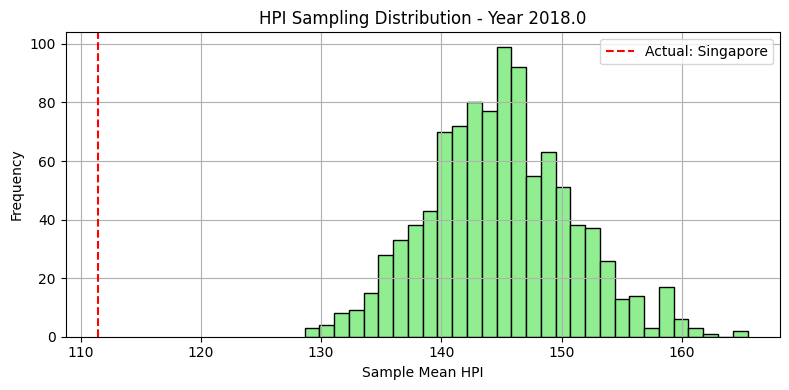

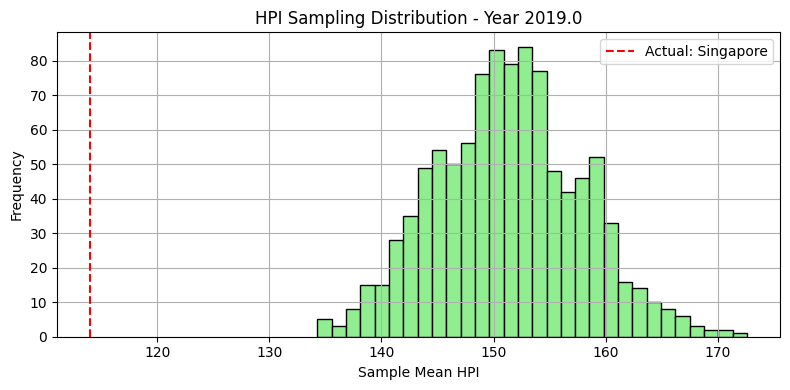

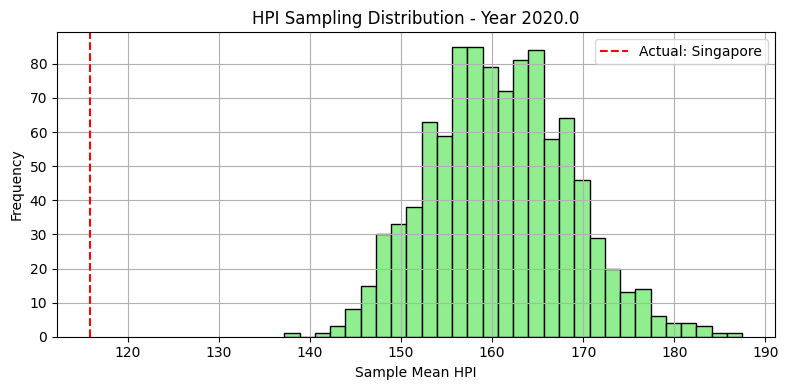

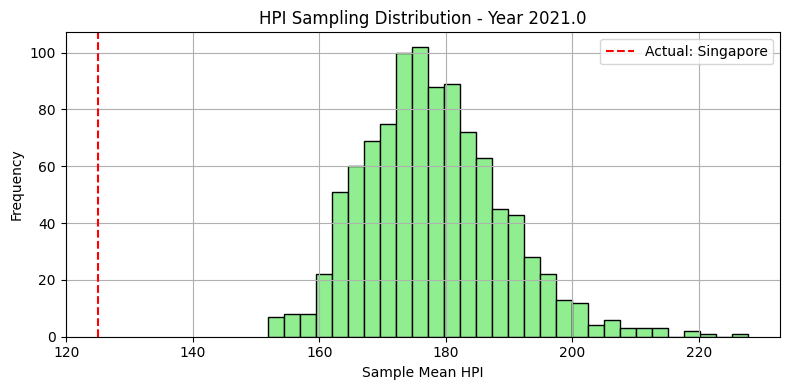

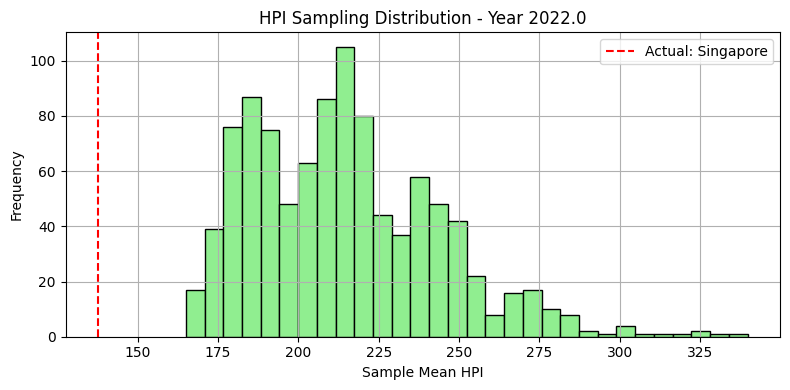

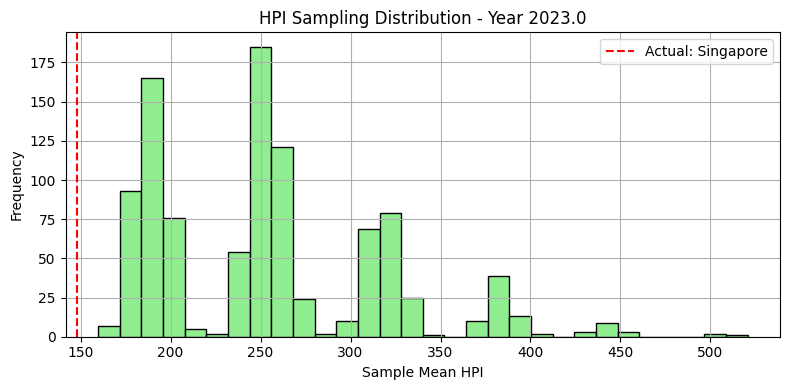

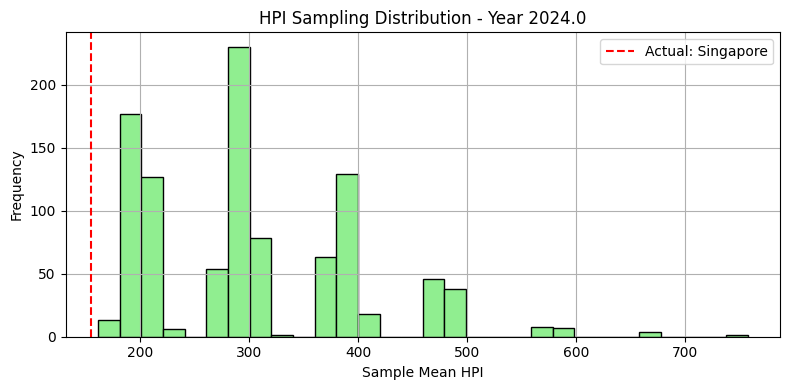

In [77]:
synthetic_01, excluded_01, actual_01 = estimate_hpi_by_cluster_sampling(df_countries_hpi, df_clusters, cluster_id=1, seed=42)

In [78]:
actual_01

{np.float64(2010.0): np.float64(100.0025),
 np.float64(2011.0): np.float64(109.4625),
 np.float64(2012.0): np.float64(112.02250000000001),
 np.float64(2013.0): np.float64(115.56),
 np.float64(2014.0): np.float64(112.2475),
 np.float64(2015.0): np.float64(107.92),
 np.float64(2016.0): np.float64(104.55),
 np.float64(2017.0): np.float64(103.405),
 np.float64(2018.0): np.float64(111.46000000000001),
 np.float64(2019.0): np.float64(113.97999999999999),
 np.float64(2020.0): np.float64(115.805),
 np.float64(2021.0): np.float64(125.0425),
 np.float64(2022.0): np.float64(137.7425),
 np.float64(2023.0): np.float64(148.015),
 np.float64(2024.0): np.float64(155.125)}

In [120]:
def estimate_hpi_by_cluster_sampling_2(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Estimates synthetic HPI values for a randomly excluded country from a selected cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to use for sampling
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    - sample_size: Size of each sample (default: 30)
    - n_samples: Number of samples to generate (default: 1000)
    - plot: Whether to show histograms for each year (default: True)
    - seed: Optional random seed for reproducibility

    Returns:
    - synthetic_hpi: dict with estimated HPI values per year
    - excluded_country: name of the country left out
    - actual_values: dict with real HPI values of the excluded country
    """

    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # Step 1: Get countries in the selected cluster that are present in the HPI DataFrame
    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]
    
    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data to perform exclusion and sampling.")
    
    # Step 2: Randomly exclude one country from those present in HPI
    excluded_country = random.choice(cluster_countries)
    sampling_countries = [c for c in cluster_countries if c != excluded_country]

    print(f"🔍 Cluster {cluster_id} selected. Excluding country: {excluded_country}")
    print(f"📊 Sampling from countries: {sampling_countries}")

    # Step 3: Prepare output containers
    synthetic_hpi = {}
    actual_values = {}

    # Step 4: Iterate over each year
    for _, row in df_hpi.iterrows():
        year = row[year_column]

        # Get HPI values for sampling countries
        values = row[sampling_countries].dropna().values

        # Get actual value of excluded country
        actual_value = row.get(excluded_country, np.nan)
        actual_values[year] = actual_value

        if len(values) == 0:
            print(f"⚠️ No HPI data available for cluster peers in year {year}")
            synthetic_hpi[year] = np.nan
            continue

        # Print available HPI values for sampling
        print(f"\n📅 Year {year} - Available HPI values for sampling:")
        print(values)

        # Generate sampling distribution
        sample_means = []
        cumulative_means = []
        for i in range(n_samples):
            sample = np.random.choice(values, size=sample_size, replace=True)
            mean = np.mean(sample)
            sample_means.append(mean)
            cumulative_means.append(np.mean(sample_means))  # track convergence

        # Compute 95% confidence interval
        lower_bound = np.percentile(sample_means, 2.5)
        upper_bound = np.percentile(sample_means, 97.5)

        # Plot side-by-side: histogram + convergence
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Histogram with confidence interval
        axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
        axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {excluded_country}")
        axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
        axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
        axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
        axes[0].set_xlabel("Sample Mean HPI")
        axes[0].set_ylabel("Frequency")
        axes[0].legend()
        axes[0].grid(True)

        # Convergence plot
        axes[1].plot(cumulative_means, color='purple')
        axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
        axes[1].set_title("Mean Convergence Over Iterations")
        axes[1].set_xlabel("Iteration")
        axes[1].set_ylabel("Cumulative Mean")
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()
        # Store synthetic HPI value
        synthetic_hpi[year] = np.mean(sample_means)

    return synthetic_hpi, excluded_country, actual_values

🔍 Cluster 1 selected. Excluding country: Singapore
📊 Sampling from countries: ['Australia', 'Brazil', 'Canada', 'Czech-Republic', 'Denmark', 'France', 'Germany', 'Hungary', 'Iceland', 'Israel', 'Italy', 'Malaysia', 'Mexico', 'Netherlands', 'Norway', 'Peru', 'Philippines', 'Poland', 'Romania', 'Serbia', 'South-Africa', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'United-Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100.     100.     100.      99.9975 100.0025 100.     100.      99.9975
 100.0025 100.     100.     100.     100.     100.     100.0025 100.0025
 100.     100.     100.      99.9975 100.     100.0025 100.0025 100.
 100.     100.     100.     100.    ]


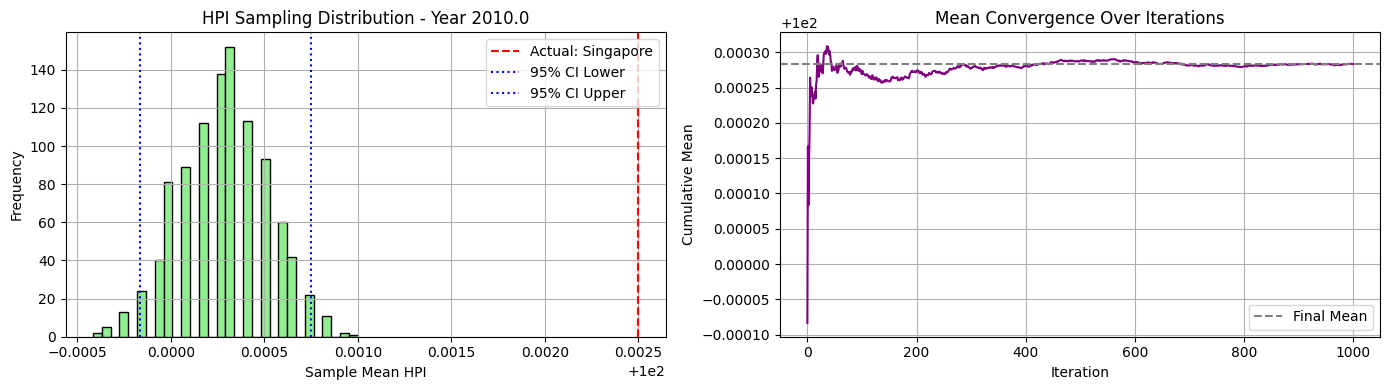


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.845  119.0225 105.75   100.025   98.29   105.6875 102.425   96.555
 105.505  110.52   101.355  109.83   105.795   98.0175 108.01   120.4325
 105.5725 100.0825  87.66    97.62   103.59    92.355  102.58   107.51
 104.2625 108.8     98.545   97.24  ]


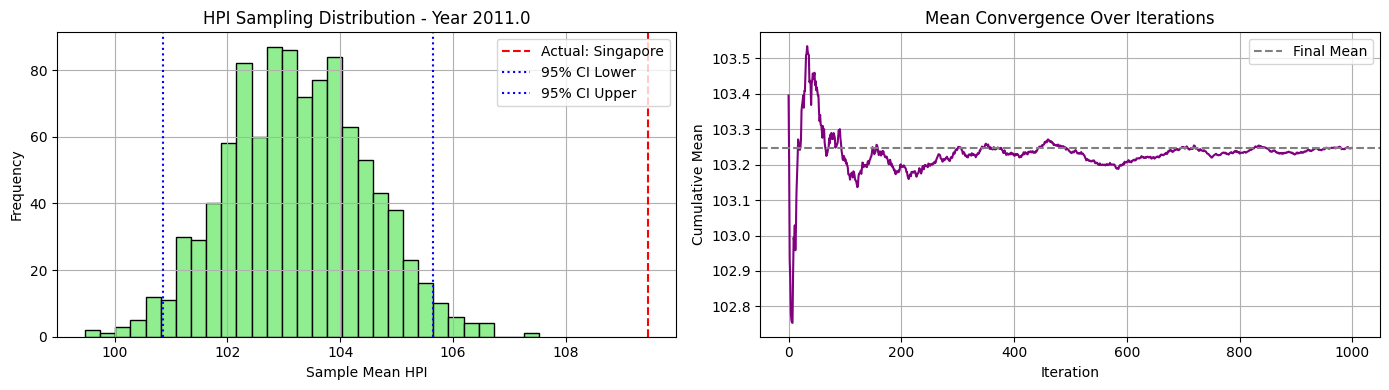


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.5325 133.06   110.615   98.555   95.6675 105.1125 105.475   92.98
 112.375  114.0975  98.7725 124.585  109.1675  91.44   115.335  143.1275
 114.9425  96.585   83.265   95.675  108.4075  78.7075 103.865  113.7225
 107.6325 120.675   98.92   101.82  ]


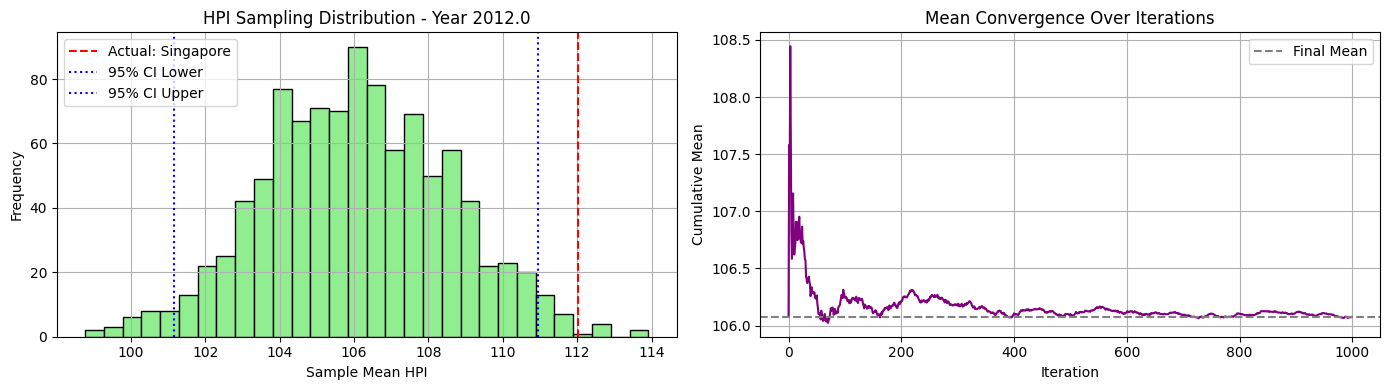


📅 Year 2013.0 - Available HPI values for sampling:
[103.9925 145.3175 112.76    98.58    99.3675 103.13   108.675   90.58
 119.185  124.4525  92.38   138.5975 114.7525  85.95   119.975  162.8475
 127.865   92.3525  83.055   90.62   115.4075  71.525  109.2225 118.3
 115.9925 134.4625 101.455  111.83  ]


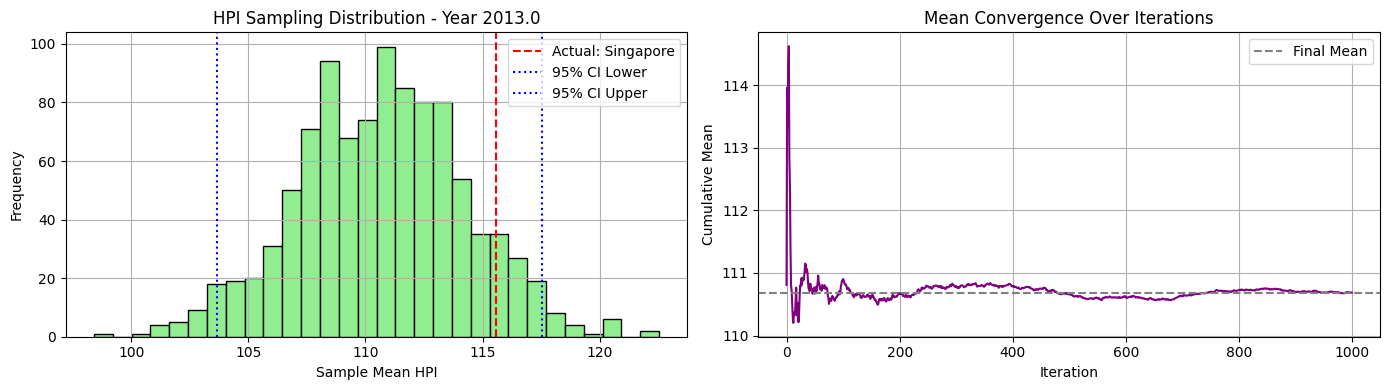


📅 Year 2014.0 - Available HPI values for sampling:
[113.4075 155.3575 118.8625 100.995  103.1175 101.58   111.85    94.37
 128.945  132.36    88.0175 151.67   119.64    86.655  123.245  172.3575
 142.76    93.27    81.38    95.7675 123.9875  71.745  119.52   121.465
 127.0725 151.25   109.6025 118.88  ]


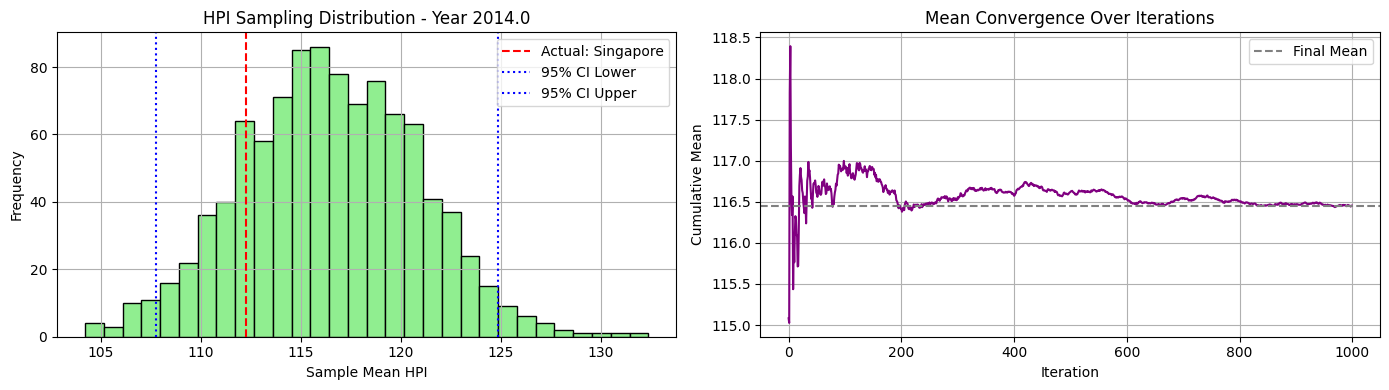


📅 Year 2015.0 - Available HPI values for sampling:
[123.645  156.165  128.4275 105.0125 110.29   100.225  117.125  106.75
 139.7425 140.115   84.6725 162.8875 129.39    89.69   130.76   167.4675
 157.035   94.6875  83.6825  99.5    131.7975  74.32   135.2    124.0775
 135.995  175.085  116.125  125.18  ]


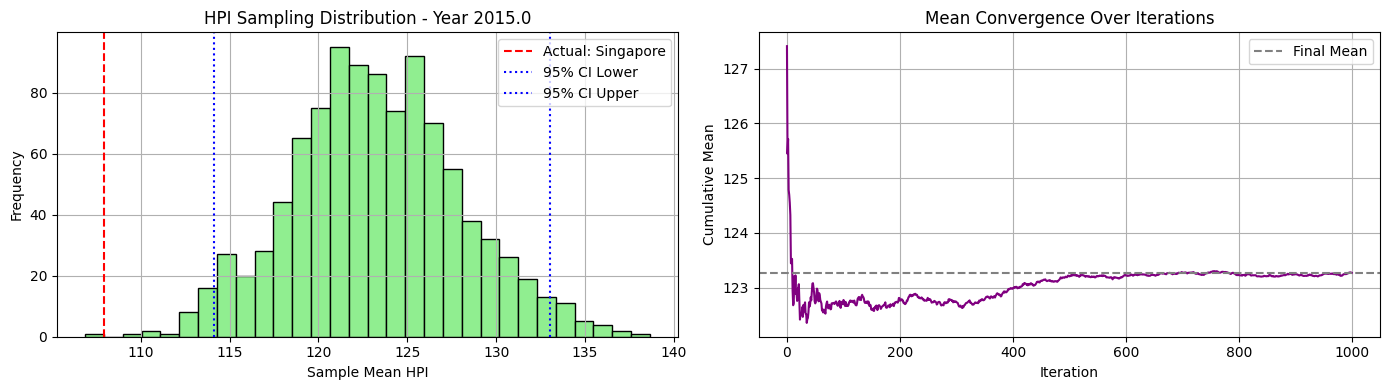


📅 Year 2016.0 - Available HPI values for sampling:
[130.445  151.945  148.66   112.5225 115.4975 101.2525 125.925  121.0325
 154.5925 150.565   84.885  174.3525 138.815   94.43   139.9475 164.185
 172.75    96.445   88.9125 110.62   138.225   77.755  146.3425 124.32
 142.405  197.4625 124.27   131.8825]


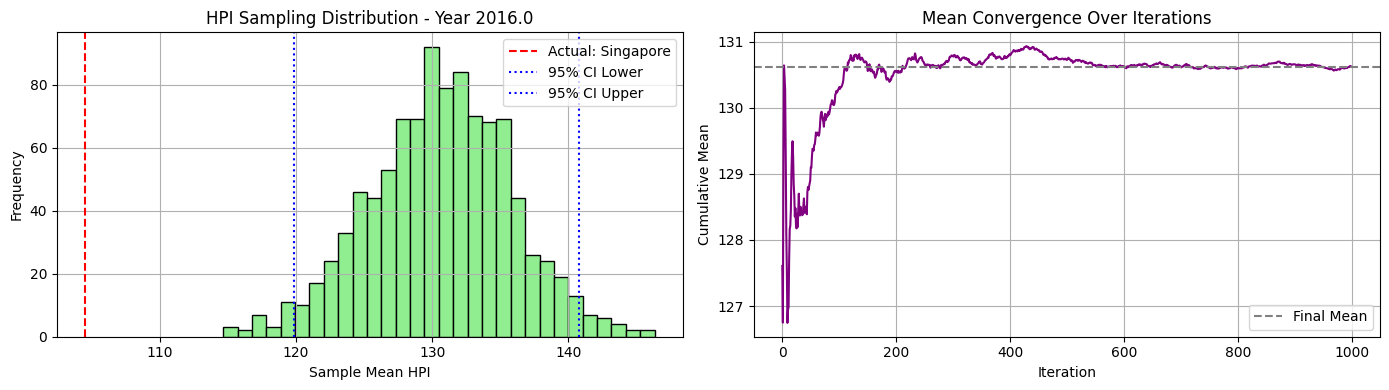


📅 Year 2017.0 - Available HPI values for sampling:
[141.335  149.02   172.295  125.7025 120.63   104.46   133.625  135.835
 183.9925 156.435   83.9775 185.7375 149.69   102.065  146.91   168.005
 178.82   100.1625  93.9325 115.3025 143.9375  82.57   156.0625 125.425
 146.4775 218.8125 129.925  139.605 ]


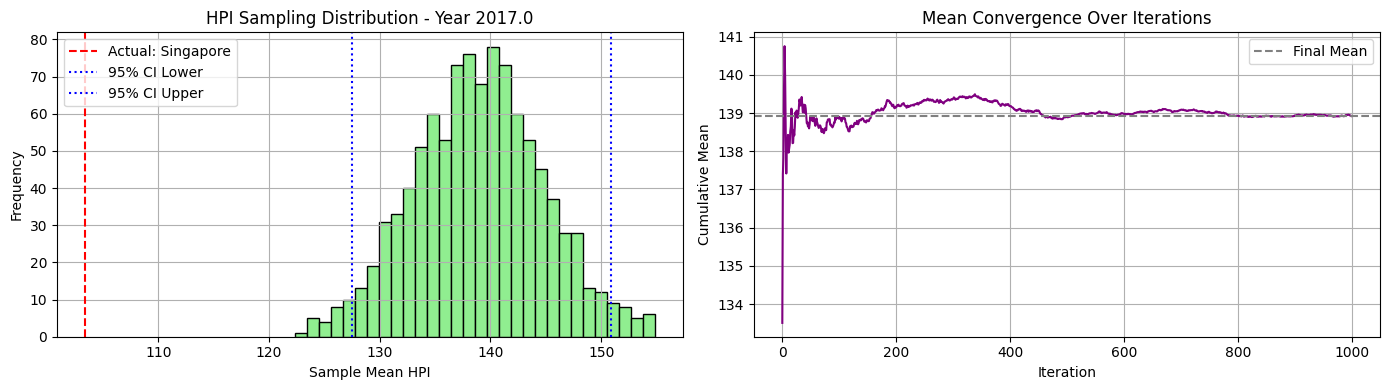


📅 Year 2018.0 - Available HPI values for sampling:
[139.305  149.8125 178.2375 136.5175 126.31   107.515  142.525  155.2975
 198.4925 155.14    83.51   191.8525 162.9675 111.5675 149.0375 168.415
 183.815  106.75    99.3725 123.0625 148.96    88.1275 154.5975 129.155
 153.9    235.9525 134.04   147.3475]


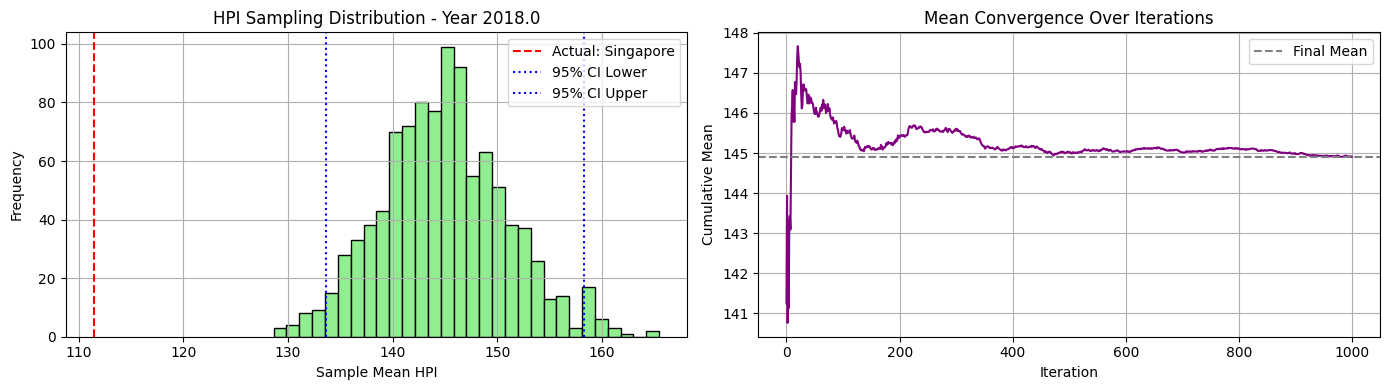


📅 Year 2019.0 - Available HPI values for sampling:
[133.64   155.055  179.4    149.015  129.6175 111.0975 150.75   181.6375
 206.51   158.065   83.425  196.0625 176.925  119.625  152.73   172.0325
 195.265  116.0125 102.72   135.77   152.6875  92.6875 158.435  133.99
 155.095  247.295  135.37   153.145 ]


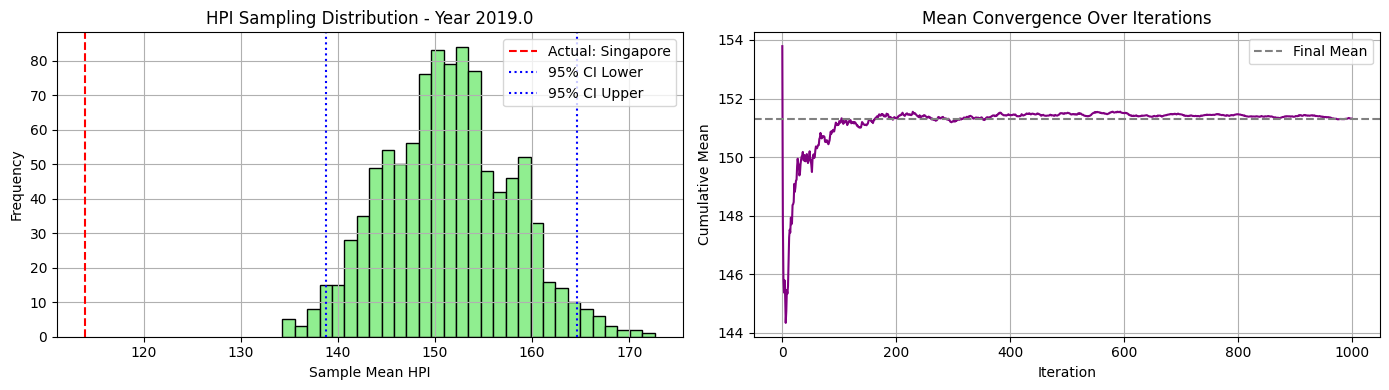


📅 Year 2020.0 - Available HPI values for sampling:
[140.8525 166.915  190.7275 161.565  136.24   116.89   162.475  190.6325
 220.8375 162.9     85.0125 198.3675 187.175  129.21   159.235  173.67
 213.74   128.175  107.5325 149.285  156.3075  94.7625 165.0925 137.3075
 160.5975 306.1225 139.2375 163.52  ]


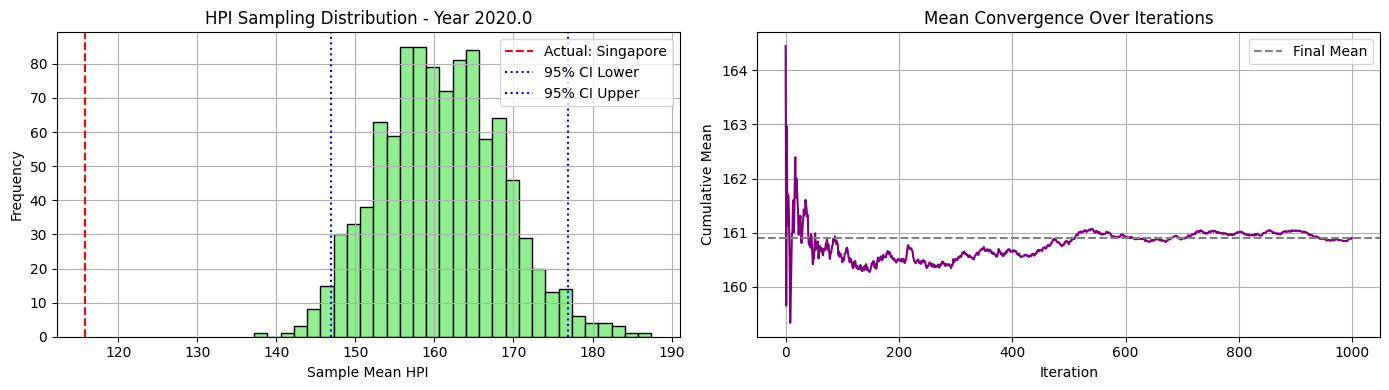


📅 Year 2021.0 - Available HPI values for sampling:
[165.3925 180.0225 214.885  193.465  152.205  124.38   181.275  222.0975
 249.4875 176.6475  87.1725 200.6925 201.9425 147.925  175.9075 173.6
 211.7425 139.9225 112.34   166.0375 166.82    98.245  181.7925 145.165
 164.2275 421.0475 150.5825 188.555 ]


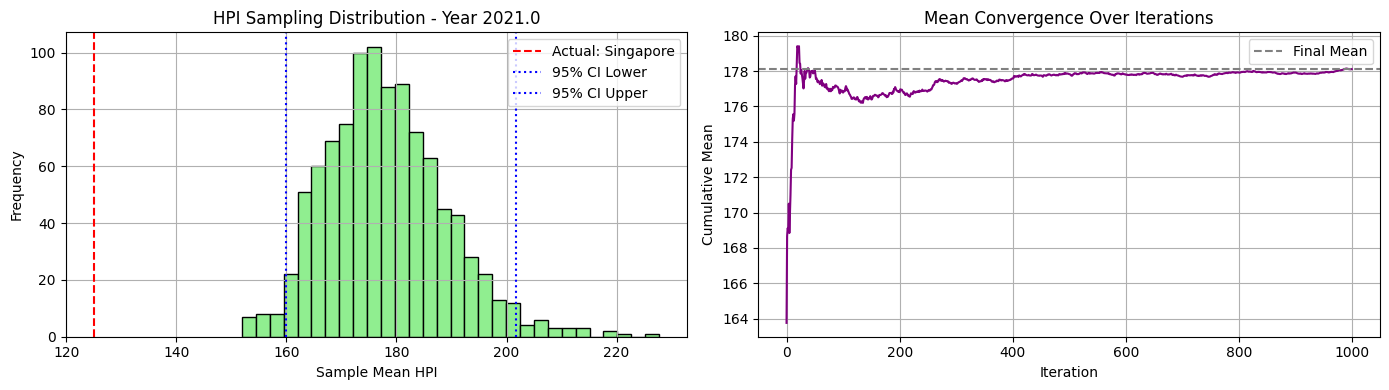


📅 Year 2022.0 - Available HPI values for sampling:
[ 179.02    185.16    235.32    226.15    151.4875  132.0975  190.425
  271.4975  302.4725  207.165    90.495   207.7475  219.93    167.57
  185.1275  172.6475  223.7275  156.4275  120.2925  191.4875  174.0325
  105.515   188.2675  154.415   169.1625 1052.51    164.5475  213.    ]


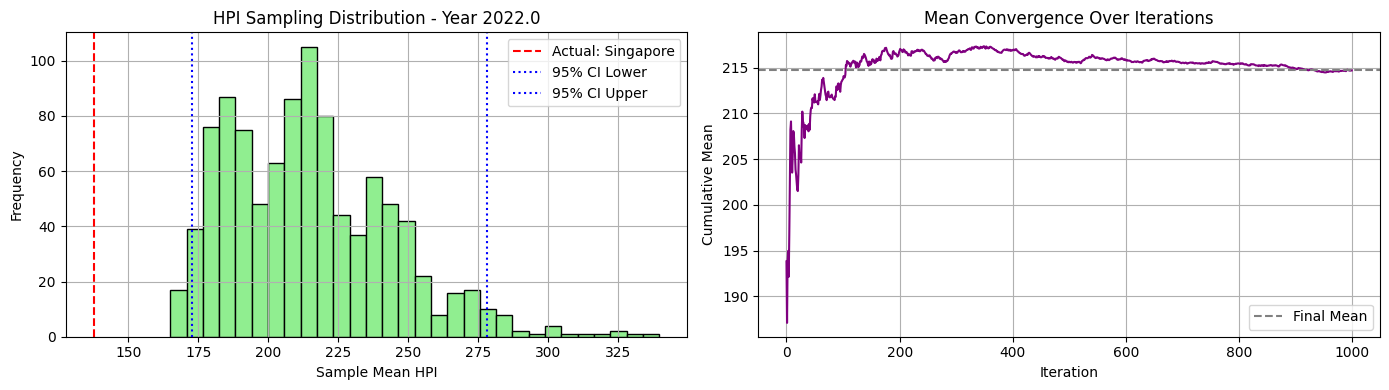


📅 Year 2023.0 - Available HPI values for sampling:
[ 178.65    191.2675  221.05    222.3975  151.24    131.5225  174.25
  290.98    322.8275  214.23     91.66    216.1925  243.8875  164.355
  184.115   175.155   248.045   170.2325  124.06    209.9875  176.6175
  109.765   178.365   157.8075  174.79   2129.53    165.0025  221.7175]


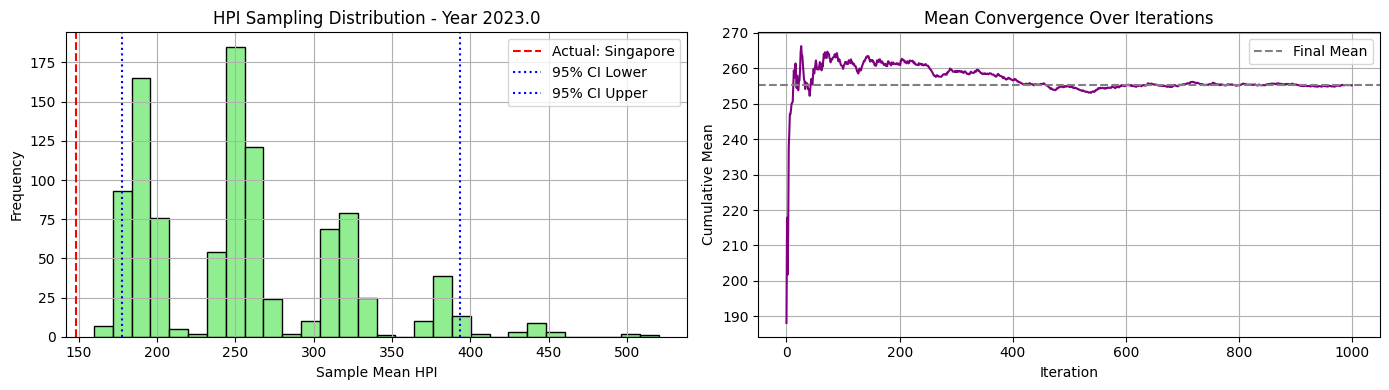


📅 Year 2024.0 - Available HPI values for sampling:
[ 192.5275  203.775   217.35    233.4225  156.73    126.6825  171.5
  328.1025  350.135   224.54     94.58    225.055   266.38    177.705
  189.05    175.3775  256.0325  195.7225  130.335   220.695   178.095
  119.095   178.49    160.5625  178.06   3014.125   166.375   231.2325]


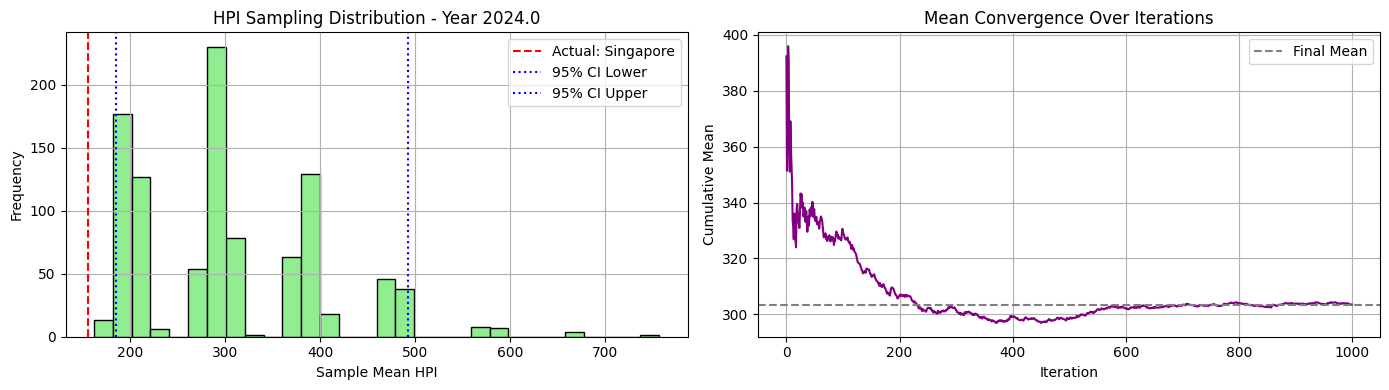

In [80]:
synthetic_02, excluded_02, actual_02 = estimate_hpi_by_cluster_sampling_2(df_countries_hpi, df_clusters, cluster_id=1, seed=42)

In [82]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

<Figure size 1400x600 with 0 Axes>

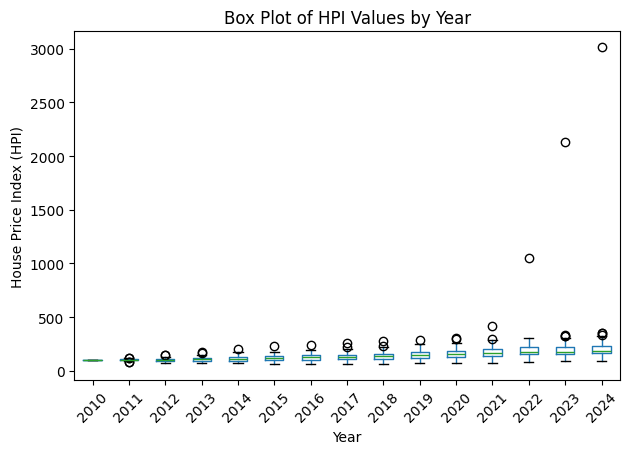

In [83]:
plot_hpi_boxplots_by_year(df_countries_hpi)

In [86]:
df_countries_hpi[df_countries_hpi['Year'] == 2024].drop(columns='Year').dropna(axis=1)

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,Cyprus,...,Slovenia,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom
14,192.5275,207.62,153.3125,203.775,205.53,217.35,354.52,269.0175,179.7,97.065,...,170.565,178.095,142.4575,119.095,178.49,160.5625,178.06,3014.125,231.2325,166.375


In [87]:
def detect_hpi_outliers_by_year(df_hpi, year_column='Year'):
    """
    Detects outliers in HPI values for each year and country using IQR method.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')

    Returns:
    - Dictionary with structure:
      {
        year1: {country1: value, country2: value, ...},
        year2: {...},
        ...
      }
    """

    outliers_by_year = {}

    # Iterate over each year
    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row.drop(labels=year_column).dropna()

        # Compute IQR
        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Detect outliers
        outliers = values[(values < lower_bound) | (values > upper_bound)]

        if not outliers.empty:
            outliers_by_year[year] = outliers.to_dict()

    return outliers_by_year

In [89]:
outliers = detect_hpi_outliers_by_year(df_countries_hpi)
outliers

{np.float64(2011.0): {'India': 122.2475,
  'Ireland': 82.9275,
  'Peru': 120.4325,
  'Russia': 79.19},
 np.float64(2012.0): {'India': 151.8775, 'Peru': 143.1275},
 np.float64(2013.0): {'India': 173.92, 'Peru': 162.8475},
 np.float64(2014.0): {'India': 199.65},
 np.float64(2015.0): {'India': 226.7925},
 np.float64(2016.0): {'India': 241.95499999999998},
 np.float64(2017.0): {'India': 262.3075, 'Turkey': 218.8125},
 np.float64(2018.0): {'India': 277.255, 'Turkey': 235.9525},
 np.float64(2019.0): {'India': 286.46},
 np.float64(2020.0): {'India': 293.6175, 'Turkey': 306.1225},
 np.float64(2021.0): {'India': 301.0675, 'Turkey': 421.0475},
 np.float64(2022.0): {'Turkey': 1052.51},
 np.float64(2023.0): {'Chile': 331.2325,
  'Iceland': 322.8275,
  'India': 323.71500000000003,
  'Turkey': 2129.5299999999997},
 np.float64(2024.0): {'Chile': 354.52,
  'Iceland': 350.135,
  'India': 335.6975,
  'Turkey': 3014.125}}

In [90]:
from scipy.stats.mstats import winsorize

In [101]:
def round_and_winsorize_hpi(df_hpi, year_column='Year', limits=(0.05, 0.05)):
    """
    Rounds all HPI values to two decimals, then applies Winsorization per year.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - limits: Tuple indicating proportion to cut from each tail (default: 10%)

    Returns:
    - DataFrame with rounded and Winsorized HPI values
    """

    # Step 1: Round all numeric values to 2 decimals
    df_rounded = df_hpi.copy()
    country_columns = [col for col in df_rounded.columns if col != year_column]
    df_rounded[country_columns] = df_rounded[country_columns].round(2)

    # Step 2: Apply Winsorization row by row
    df_winsorized = df_rounded.copy()

    for idx, row in df_rounded.iterrows():
        values = row[country_columns].values.astype(float)

        # Apply Winsorization only if enough valid values
        if np.count_nonzero(~np.isnan(values)) >= 4:
            winsorized = winsorize(values, limits=limits)
            df_winsorized.loc[idx, country_columns] = winsorized

    return df_winsorized

In [102]:
df_hpi_winsorized = round_and_winsorize_hpi(df_countries_hpi)

In [103]:
outliers_after_win = detect_hpi_outliers_by_year(df_hpi_winsorized)
outliers_after_win

{np.float64(2023.0): {'Chile': 323.72,
  'Iceland': 322.83,
  'India': 323.72,
  'Turkey': 323.72},
 np.float64(2024.0): {'Chile': 350.14,
  'Iceland': 350.14,
  'India': 335.7,
  'Turkey': 350.14}}

In [112]:
df_hpi_winsorized = round_and_winsorize_hpi(df_countries_hpi, limits=(0.078,0.078))

In [113]:
outliers_after_win = detect_hpi_outliers_by_year(df_hpi_winsorized)
outliers_after_win

{}

<Figure size 1400x600 with 0 Axes>

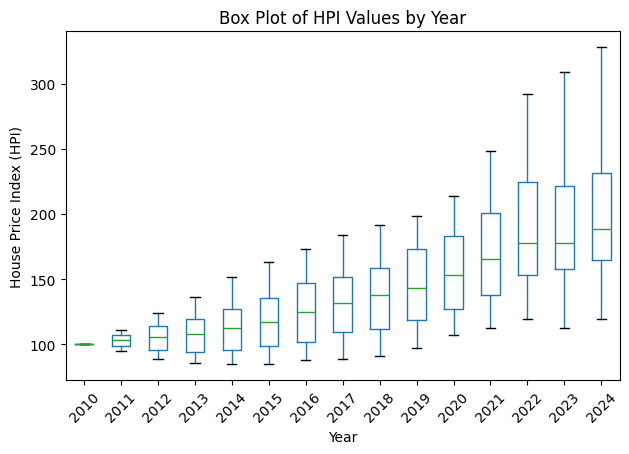

In [114]:
plot_hpi_boxplots_by_year(df_hpi_winsorized)

🔍 Cluster 1 selected. Excluding country: Singapore
📊 Sampling from countries: ['Australia', 'Brazil', 'Canada', 'Czech-Republic', 'Denmark', 'France', 'Germany', 'Hungary', 'Iceland', 'Israel', 'Italy', 'Malaysia', 'Mexico', 'Netherlands', 'Norway', 'Peru', 'Philippines', 'Poland', 'Romania', 'Serbia', 'South-Africa', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'United-Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


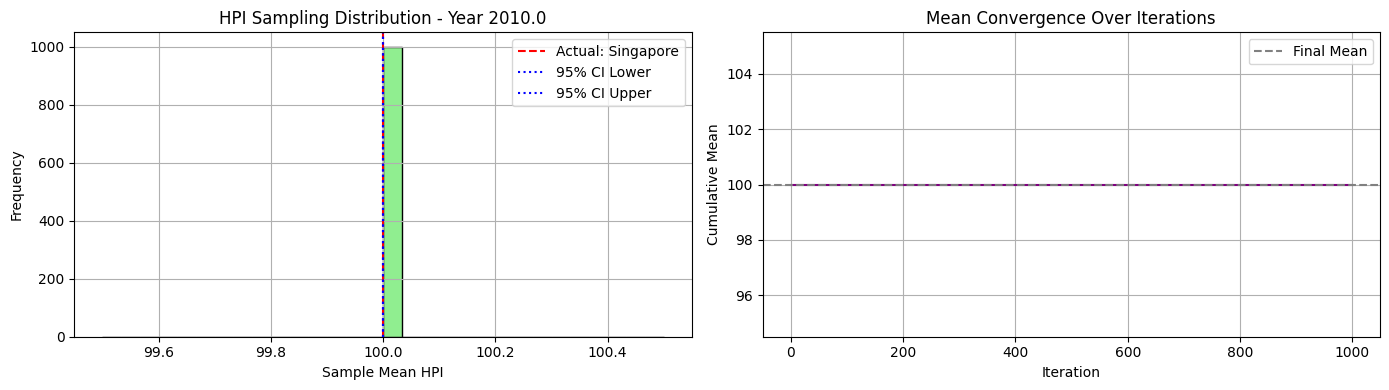


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 110.52 105.75 100.02  98.29 105.69 102.42  96.56 105.5  110.52
 101.36 109.83 105.8   98.02 108.01 110.52 105.57 100.08  94.49  97.62
 103.59  94.49 102.58 107.51 104.26 108.8   98.54  97.24]


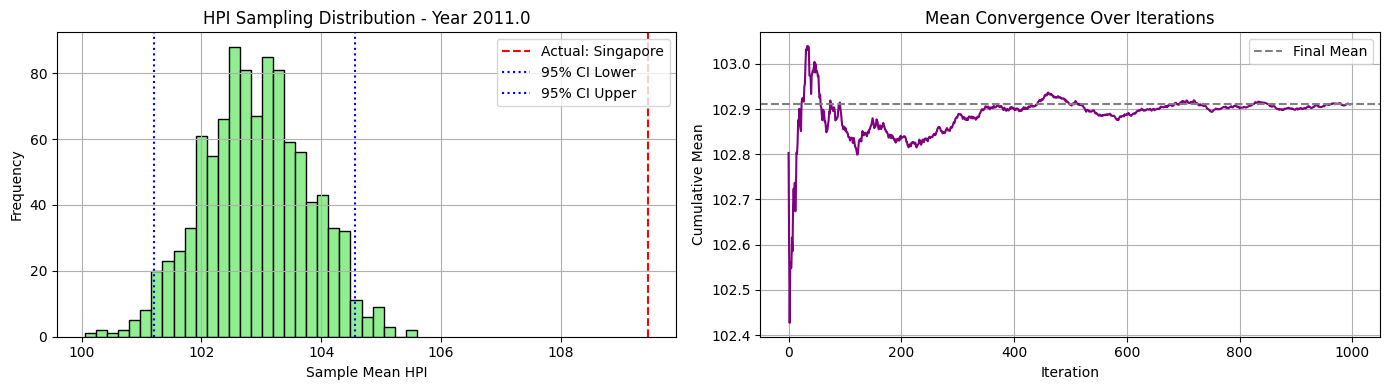


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 124.02 110.62  98.56  95.67 105.11 105.48  92.98 112.38 114.1
  98.77 124.02 109.17  91.44 115.34 124.02 114.94  96.58  88.37  95.68
 108.41  88.37 103.86 113.72 107.63 120.68  98.92 101.82]


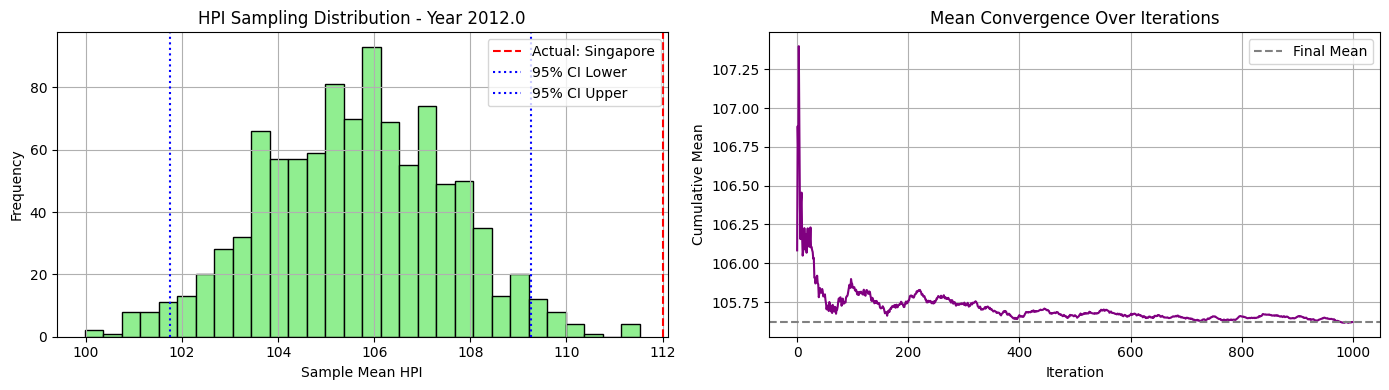


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 136.52 112.76  98.58  99.37 103.13 108.68  90.58 119.18 124.45
  92.38 136.52 114.75  85.95 119.98 136.52 127.86  92.35  85.58  90.62
 115.41  85.58 109.22 118.3  115.99 134.46 101.46 111.83]


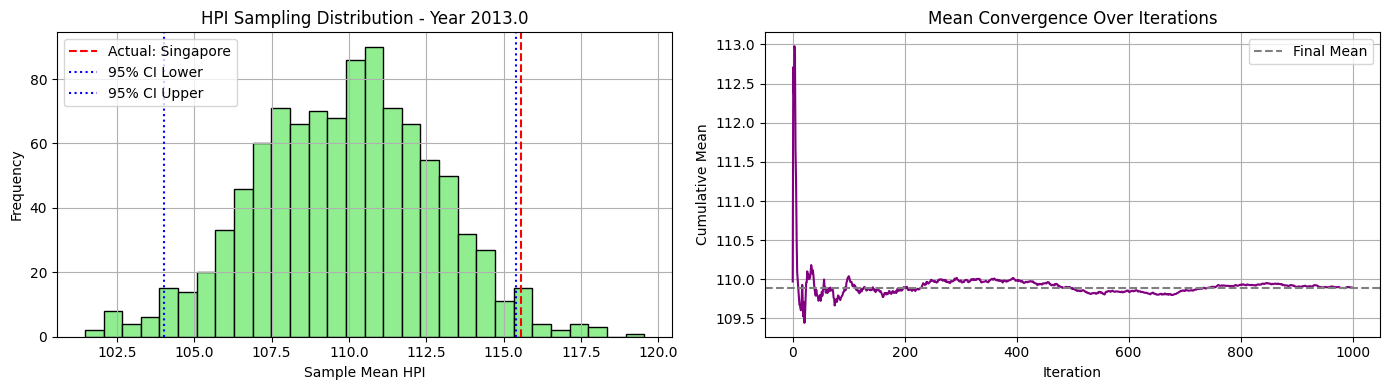


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 151.67 118.86 101.   103.12 101.58 111.85  94.37 128.94 132.36
  88.02 151.67 119.64  86.66 123.24 151.67 142.76  93.27  84.64  95.77
 123.99  84.64 119.52 121.46 127.07 151.25 109.6  118.88]


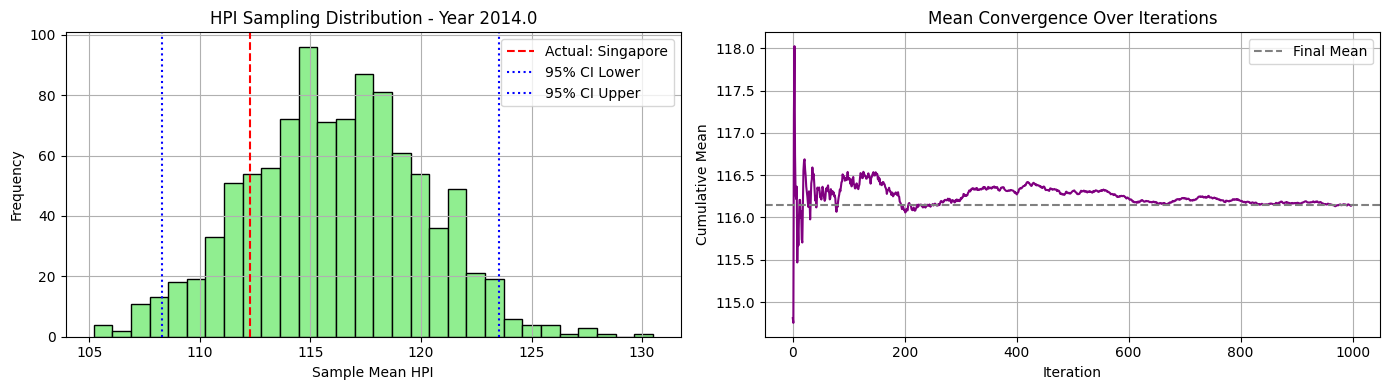


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 156.16 128.43 105.01 110.29 100.22 117.12 106.75 139.74 140.12
  84.67 162.89 129.39  89.69 130.76 162.89 157.04  94.69  84.67  99.5
 131.8   84.67 135.2  124.08 136.   162.89 116.12 125.18]


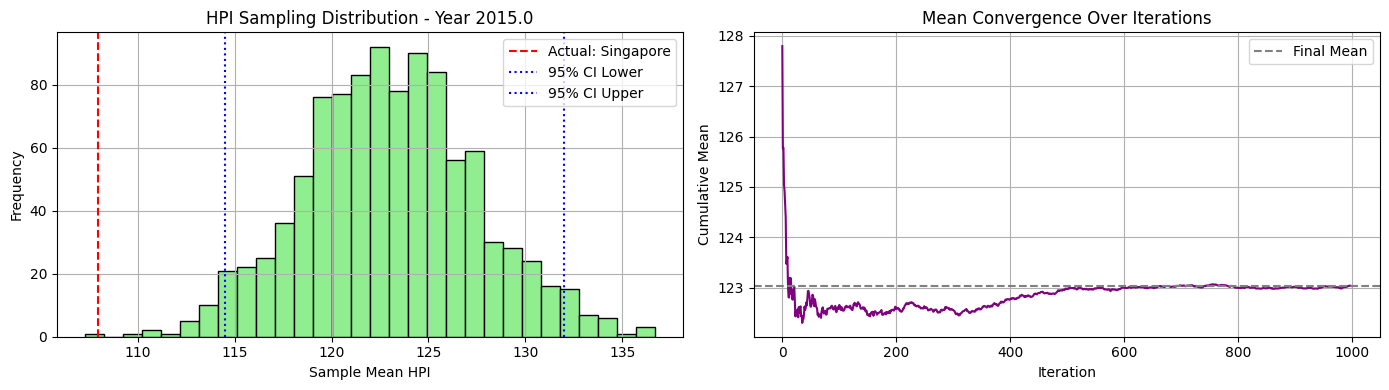


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 151.94 148.66 112.52 115.5  101.25 125.93 121.03 154.59 150.56
  88.1  172.75 138.82  94.43 139.95 164.18 172.75  96.44  88.91 110.62
 138.22  88.1  146.34 124.32 142.4  172.75 124.27 131.88]


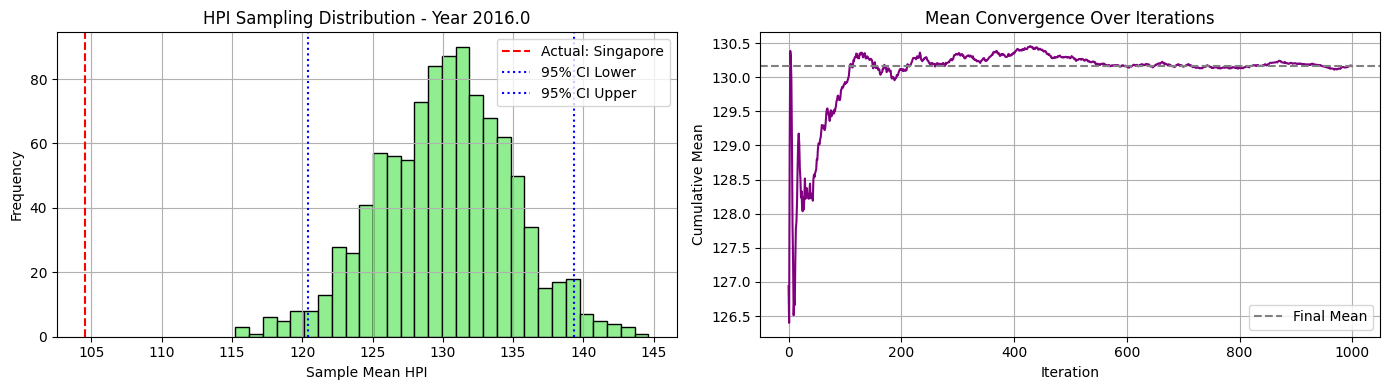


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 149.02 172.3  125.7  120.63 104.46 133.62 135.84 183.99 156.44
  88.54 183.99 149.69 102.06 146.91 168.   178.82 100.16  93.93 115.3
 143.94  88.54 156.06 125.42 146.48 183.99 129.93 139.61]


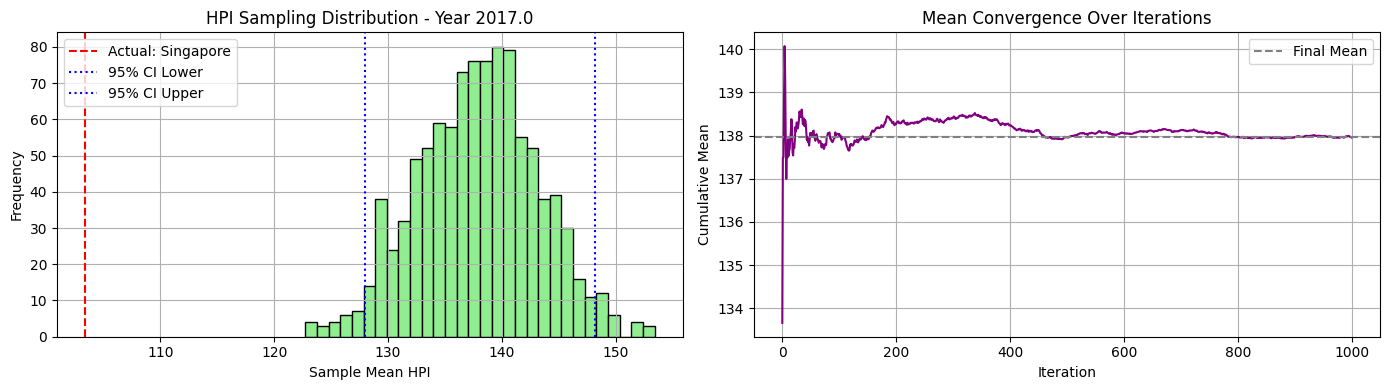


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  149.81 178.24 136.52 126.31 107.52 142.52 155.3  191.85 155.14
  90.72 191.85 162.97 111.57 149.04 168.42 183.82 106.75  99.37 123.06
 148.96  90.72 154.6  129.16 153.9  191.85 134.04 147.35]


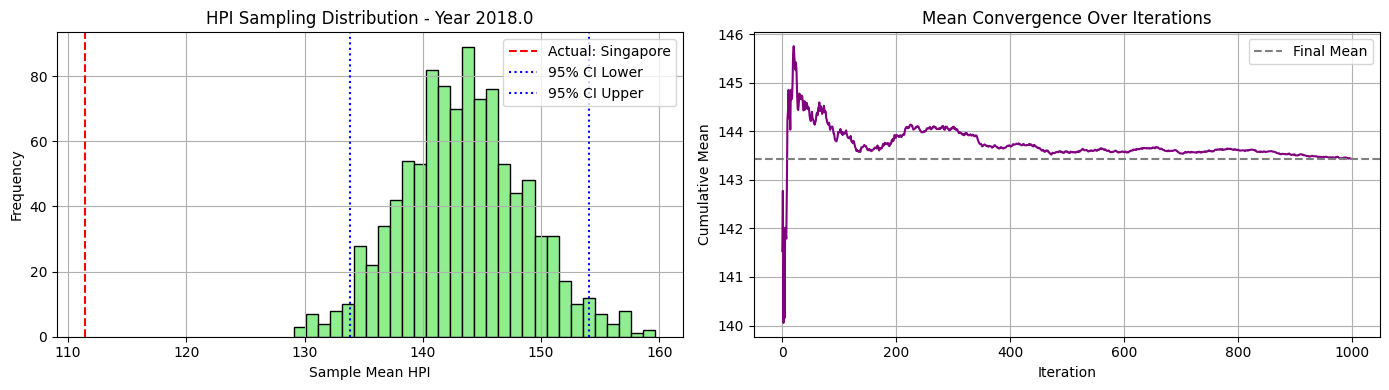


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 155.06 179.4  149.02 129.62 111.1  150.75 181.64 198.37 158.06
  97.25 196.06 176.92 119.62 152.73 172.03 195.26 116.01 102.72 135.77
 152.69  97.25 158.44 133.99 155.1  198.37 135.37 153.14]


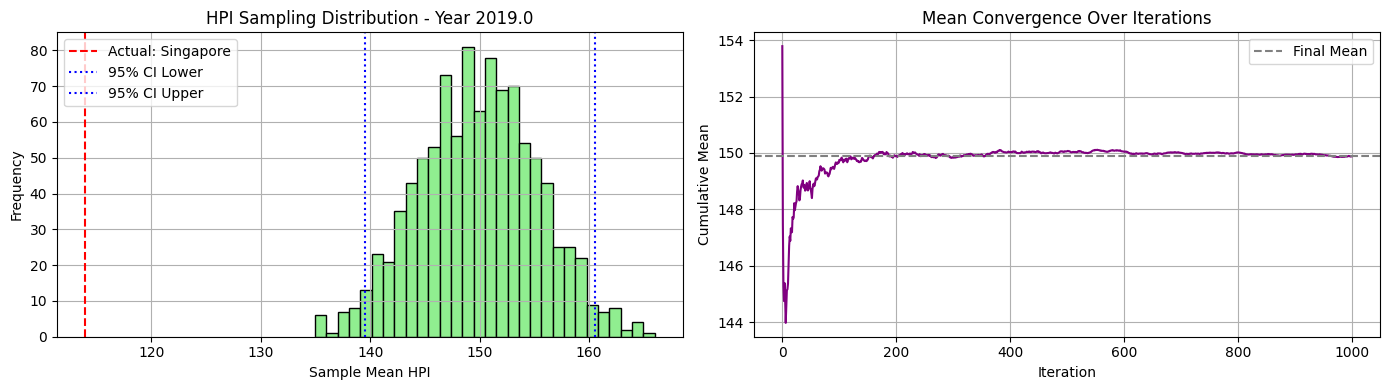


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 166.92 190.73 161.56 136.24 116.89 162.48 190.63 213.74 162.9
 106.71 198.37 187.18 129.21 159.24 173.67 213.74 128.18 107.53 149.28
 156.31 106.71 165.09 137.31 160.6  213.74 139.24 163.52]


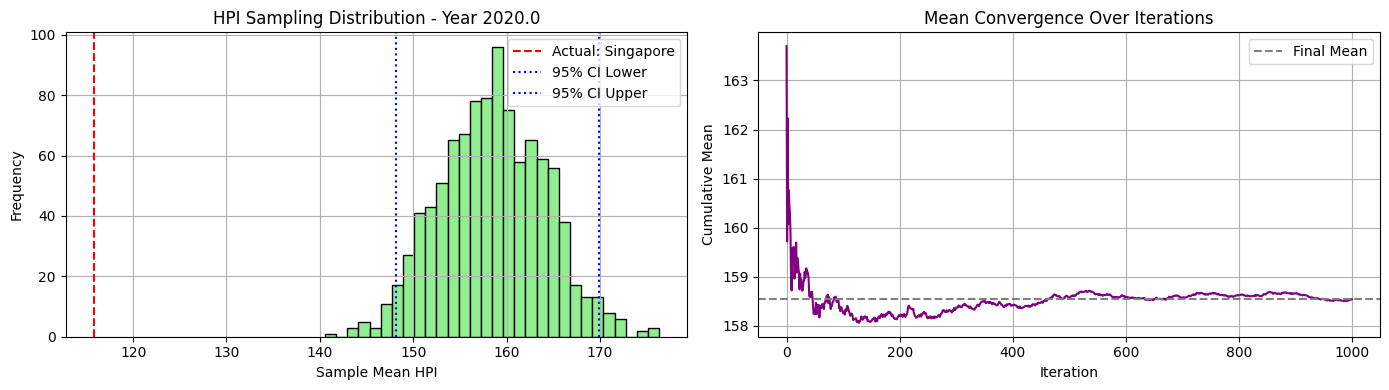


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 180.02 214.88 193.46 152.2  124.38 181.28 222.1  248.26 176.65
 112.34 200.69 201.94 147.93 175.91 173.6  211.74 139.92 112.34 166.04
 166.82 112.34 181.79 145.16 164.23 248.26 150.58 188.56]


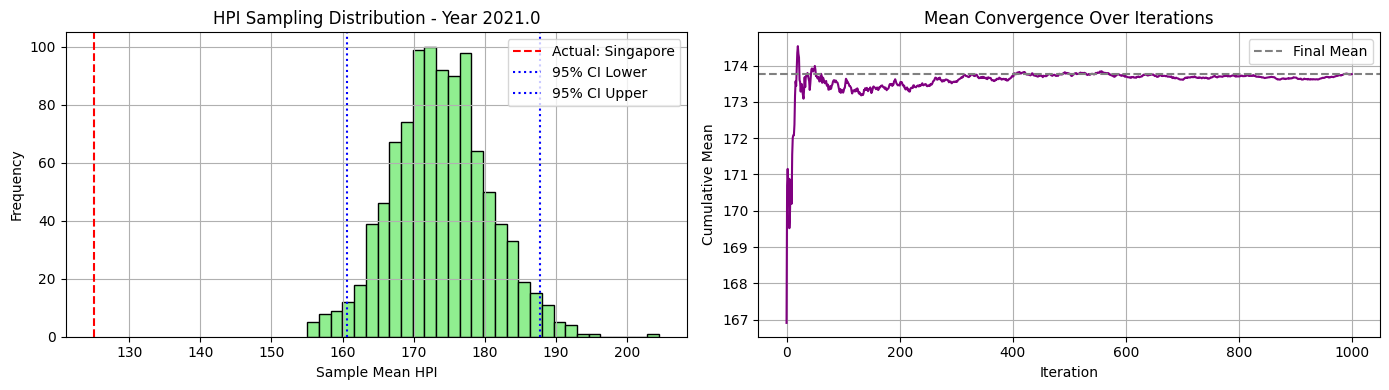


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 185.16 235.32 226.15 151.49 132.1  190.42 271.5  292.18 207.16
 118.98 207.75 219.93 167.57 185.13 172.65 223.73 156.43 120.29 191.49
 174.03 118.98 188.27 154.42 169.16 292.18 164.55 213.  ]


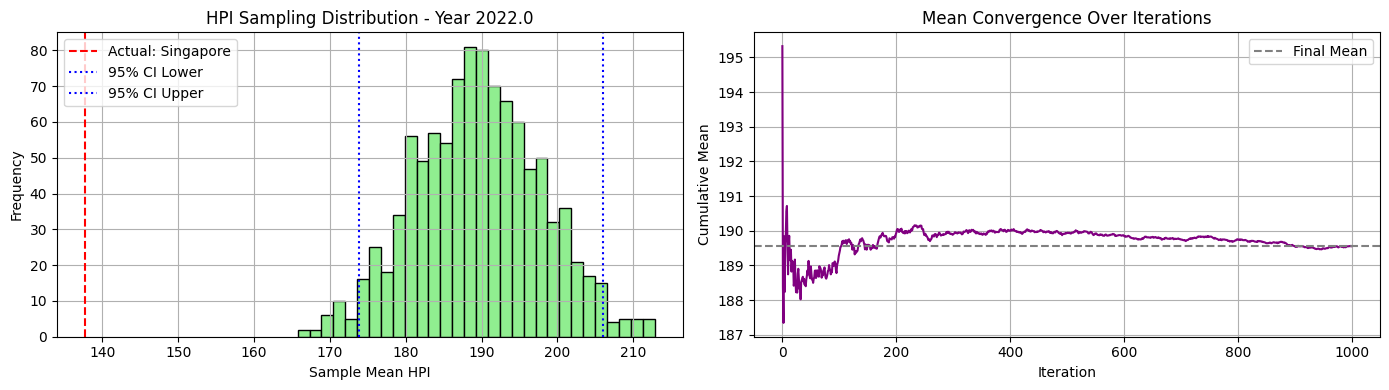


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 191.27 221.05 222.4  151.24 131.52 174.25 290.98 309.37 214.23
 112.27 216.19 243.89 164.36 184.12 175.16 248.04 170.23 124.06 209.99
 176.62 112.27 178.36 157.81 174.79 309.37 165.   221.72]


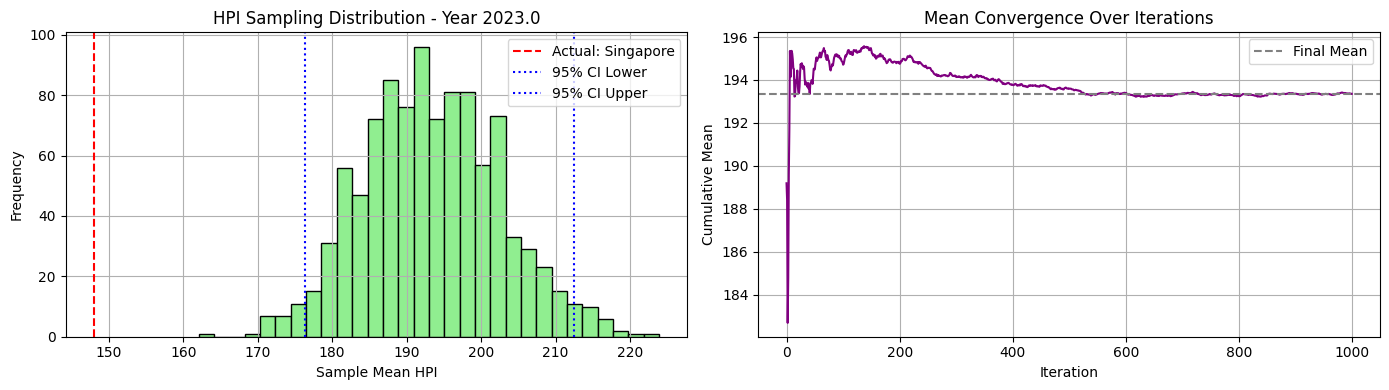


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 203.78 217.35 233.42 156.73 126.68 171.5  328.1  328.24 224.54
 119.1  225.06 266.38 177.7  189.05 175.38 256.03 195.72 130.34 220.7
 178.1  119.1  178.49 160.56 178.06 328.24 166.38 231.23]


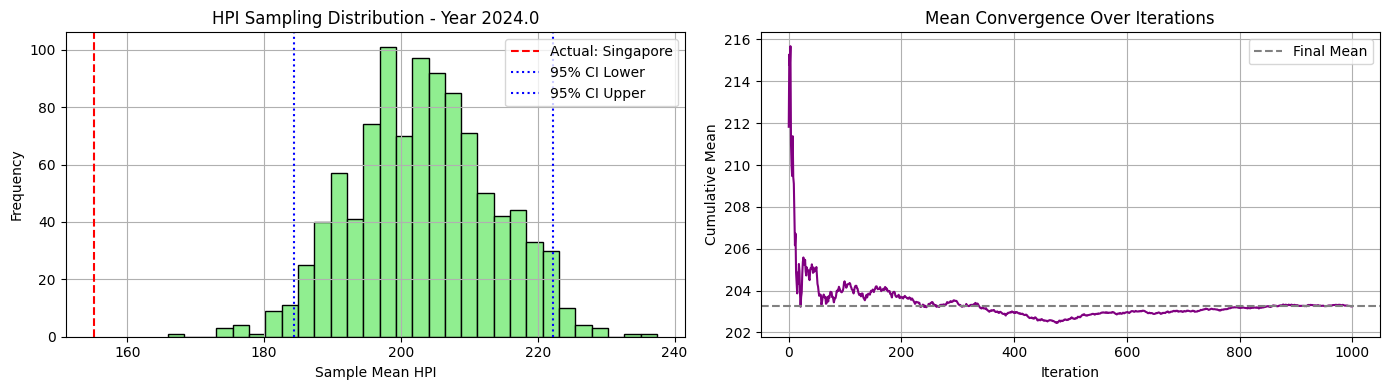

In [115]:
synthetic_03, excluded_03, actual_03 = estimate_hpi_by_cluster_sampling_2(df_hpi_winsorized, df_clusters, cluster_id=1, seed=42)

In [117]:
actual_03

{np.float64(2010.0): np.float64(100.0),
 np.float64(2011.0): np.float64(109.46),
 np.float64(2012.0): np.float64(112.02),
 np.float64(2013.0): np.float64(115.56),
 np.float64(2014.0): np.float64(112.25),
 np.float64(2015.0): np.float64(107.92),
 np.float64(2016.0): np.float64(104.55),
 np.float64(2017.0): np.float64(103.4),
 np.float64(2018.0): np.float64(111.46),
 np.float64(2019.0): np.float64(113.98),
 np.float64(2020.0): np.float64(115.8),
 np.float64(2021.0): np.float64(125.04),
 np.float64(2022.0): np.float64(137.74),
 np.float64(2023.0): np.float64(148.01),
 np.float64(2024.0): np.float64(155.12)}

🔍 Cluster 1 selected. Excluding country: Singapore
📊 Sampling from countries: ['Australia', 'Brazil', 'Canada', 'Czech-Republic', 'Denmark', 'France', 'Germany', 'Hungary', 'Iceland', 'Israel', 'Italy', 'Malaysia', 'Mexico', 'Netherlands', 'Norway', 'Peru', 'Philippines', 'Poland', 'Romania', 'Serbia', 'South-Africa', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'Turkey', 'United-Kingdom', 'USA']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.]


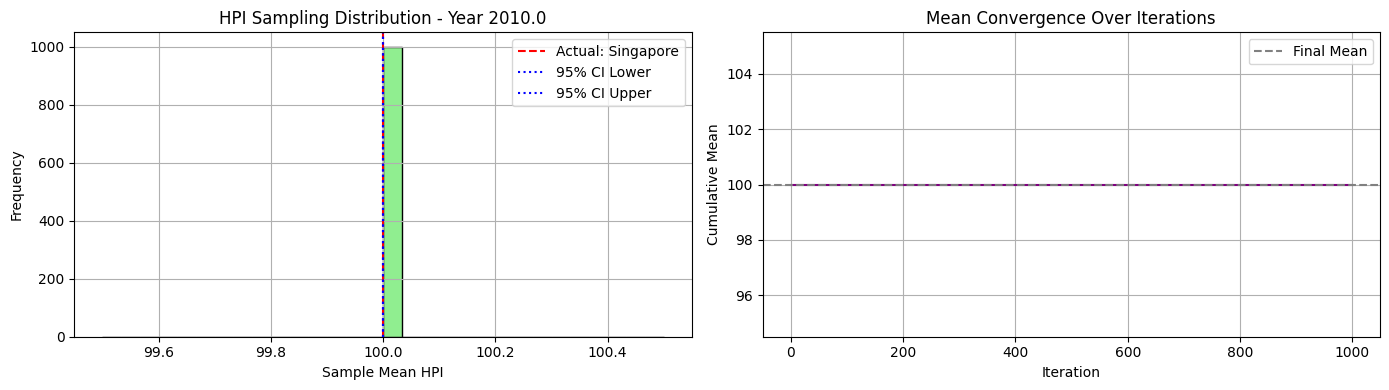


📅 Year 2011.0 - Available HPI values for sampling:
[ 97.84 110.52 105.75 100.02  98.29 105.69 102.42  96.56 105.5  110.52
 101.36 109.83 105.8   98.02 108.01 110.52 105.57 100.08  94.49  97.62
 103.59  94.49 102.58 107.51 104.26 108.8   98.54  97.24]


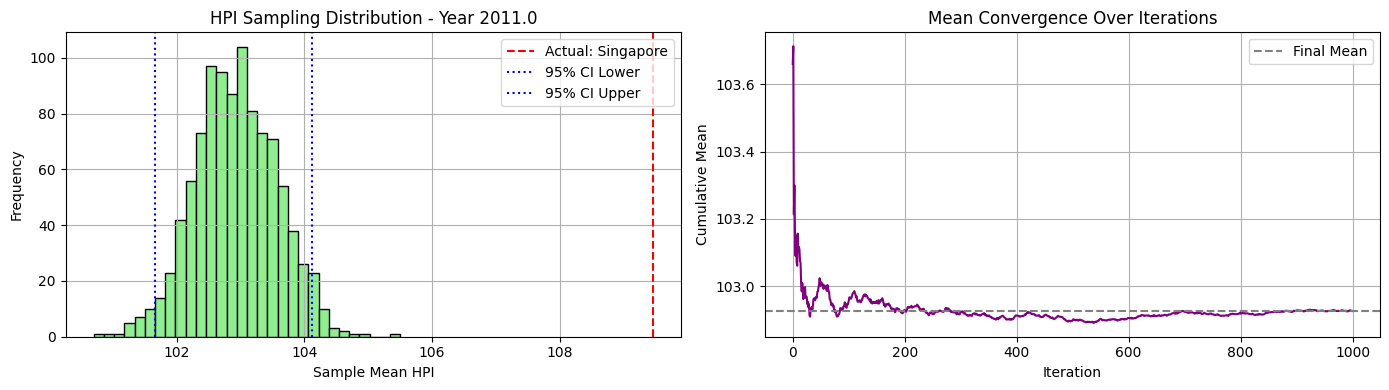


📅 Year 2012.0 - Available HPI values for sampling:
[ 97.53 124.02 110.62  98.56  95.67 105.11 105.48  92.98 112.38 114.1
  98.77 124.02 109.17  91.44 115.34 124.02 114.94  96.58  88.37  95.68
 108.41  88.37 103.86 113.72 107.63 120.68  98.92 101.82]


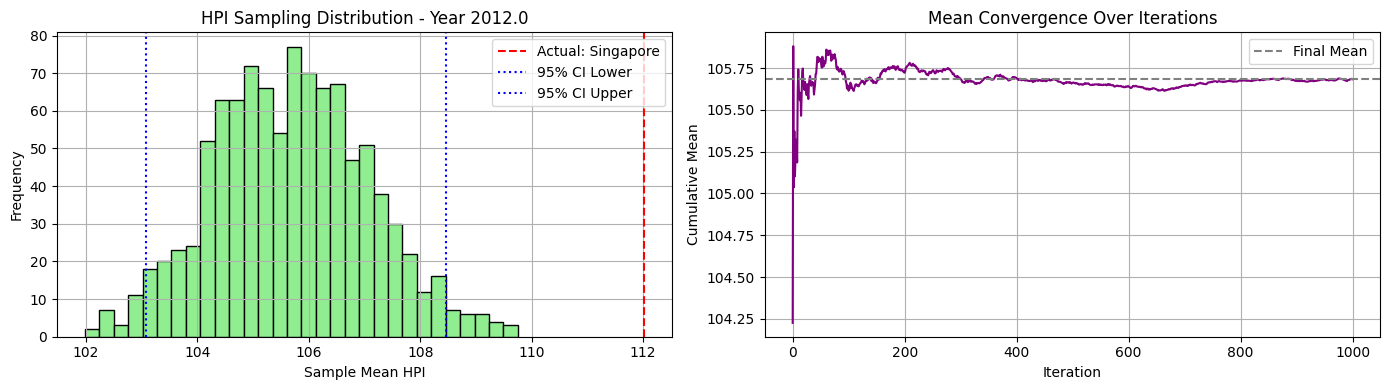


📅 Year 2013.0 - Available HPI values for sampling:
[103.99 136.52 112.76  98.58  99.37 103.13 108.68  90.58 119.18 124.45
  92.38 136.52 114.75  85.95 119.98 136.52 127.86  92.35  85.58  90.62
 115.41  85.58 109.22 118.3  115.99 134.46 101.46 111.83]


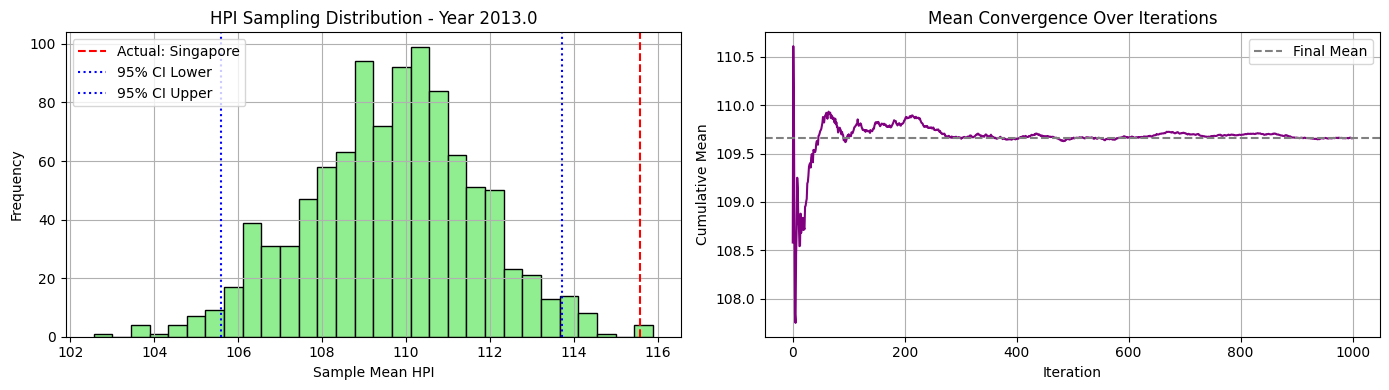


📅 Year 2014.0 - Available HPI values for sampling:
[113.41 151.67 118.86 101.   103.12 101.58 111.85  94.37 128.94 132.36
  88.02 151.67 119.64  86.66 123.24 151.67 142.76  93.27  84.64  95.77
 123.99  84.64 119.52 121.46 127.07 151.25 109.6  118.88]


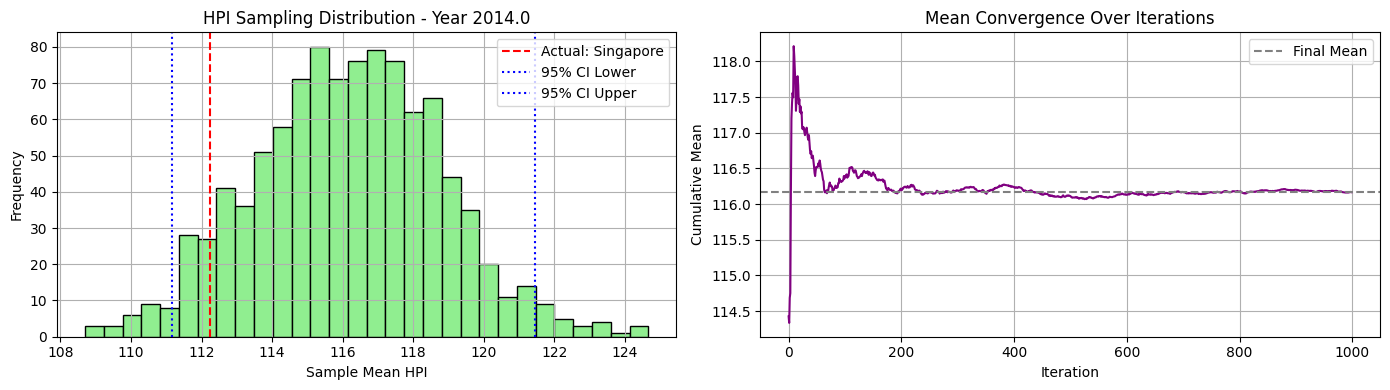


📅 Year 2015.0 - Available HPI values for sampling:
[123.65 156.16 128.43 105.01 110.29 100.22 117.12 106.75 139.74 140.12
  84.67 162.89 129.39  89.69 130.76 162.89 157.04  94.69  84.67  99.5
 131.8   84.67 135.2  124.08 136.   162.89 116.12 125.18]


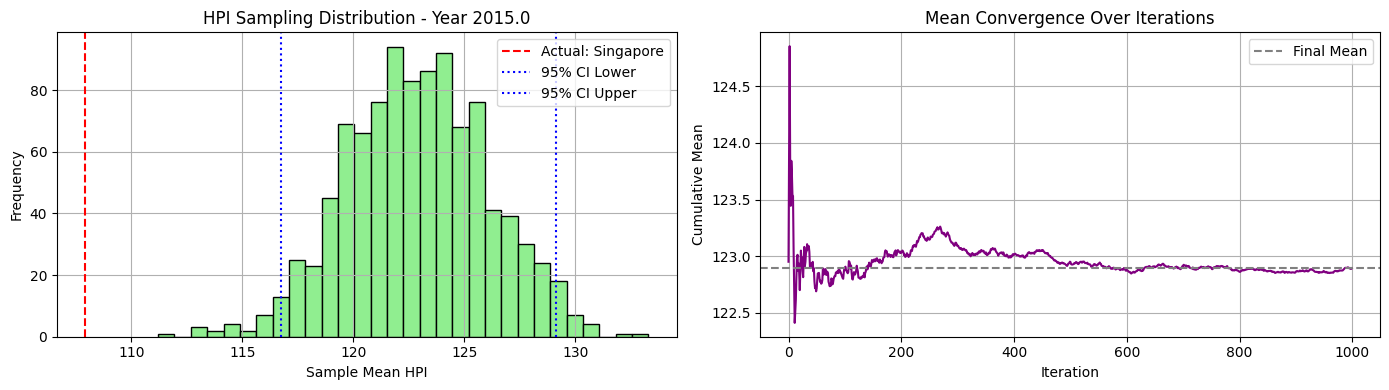


📅 Year 2016.0 - Available HPI values for sampling:
[130.44 151.94 148.66 112.52 115.5  101.25 125.93 121.03 154.59 150.56
  88.1  172.75 138.82  94.43 139.95 164.18 172.75  96.44  88.91 110.62
 138.22  88.1  146.34 124.32 142.4  172.75 124.27 131.88]


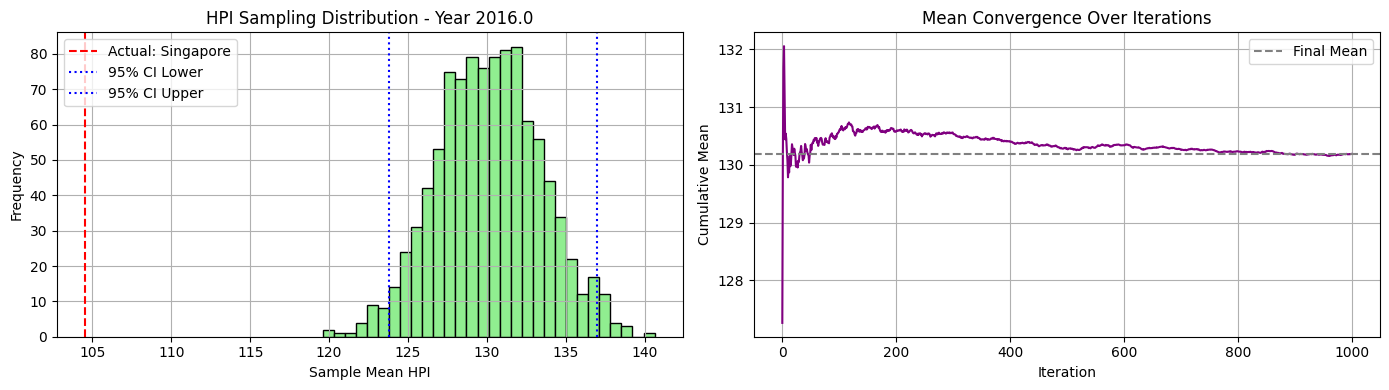


📅 Year 2017.0 - Available HPI values for sampling:
[141.34 149.02 172.3  125.7  120.63 104.46 133.62 135.84 183.99 156.44
  88.54 183.99 149.69 102.06 146.91 168.   178.82 100.16  93.93 115.3
 143.94  88.54 156.06 125.42 146.48 183.99 129.93 139.61]


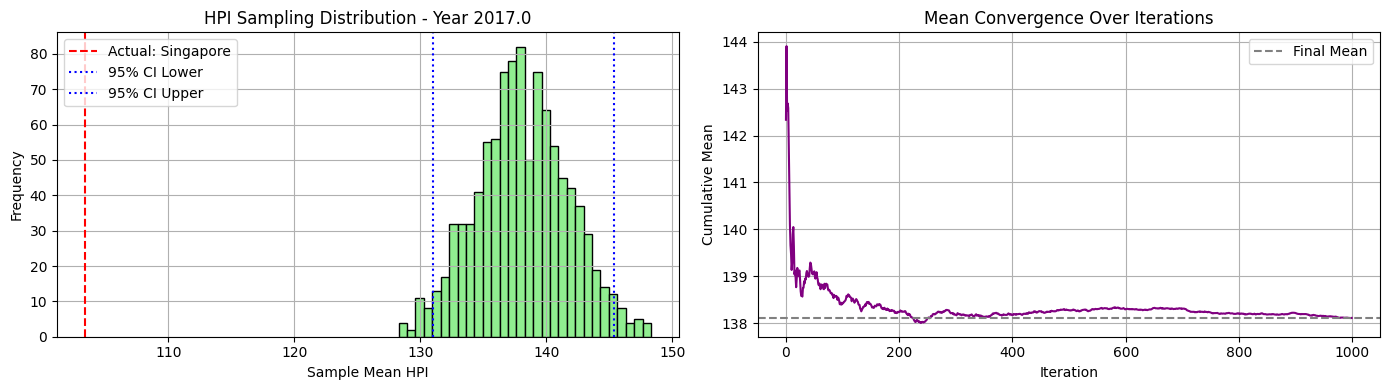


📅 Year 2018.0 - Available HPI values for sampling:
[139.3  149.81 178.24 136.52 126.31 107.52 142.52 155.3  191.85 155.14
  90.72 191.85 162.97 111.57 149.04 168.42 183.82 106.75  99.37 123.06
 148.96  90.72 154.6  129.16 153.9  191.85 134.04 147.35]


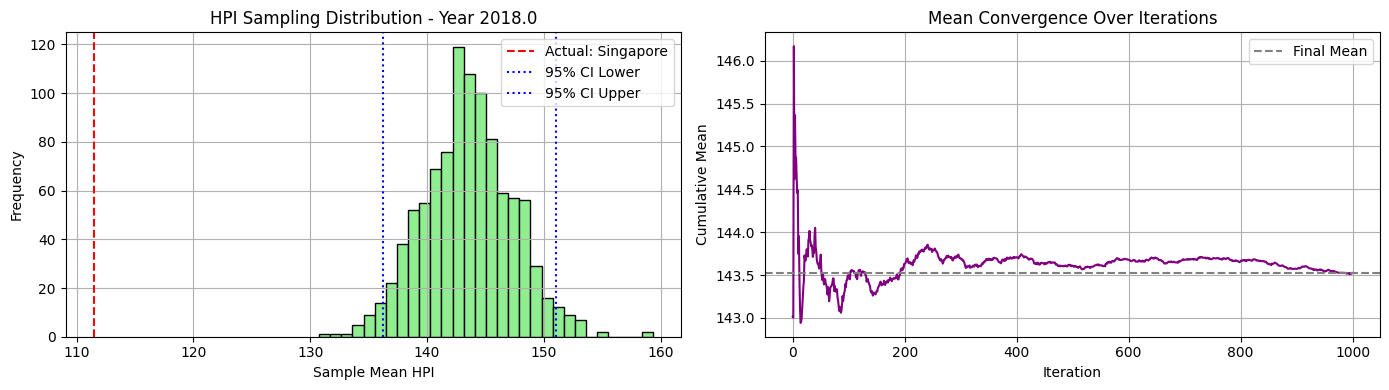


📅 Year 2019.0 - Available HPI values for sampling:
[133.64 155.06 179.4  149.02 129.62 111.1  150.75 181.64 198.37 158.06
  97.25 196.06 176.92 119.62 152.73 172.03 195.26 116.01 102.72 135.77
 152.69  97.25 158.44 133.99 155.1  198.37 135.37 153.14]


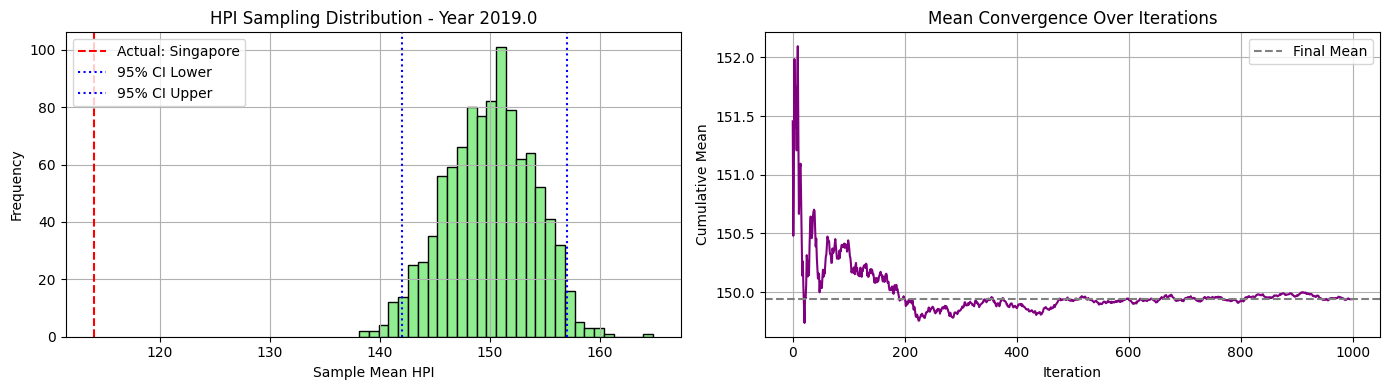


📅 Year 2020.0 - Available HPI values for sampling:
[140.85 166.92 190.73 161.56 136.24 116.89 162.48 190.63 213.74 162.9
 106.71 198.37 187.18 129.21 159.24 173.67 213.74 128.18 107.53 149.28
 156.31 106.71 165.09 137.31 160.6  213.74 139.24 163.52]


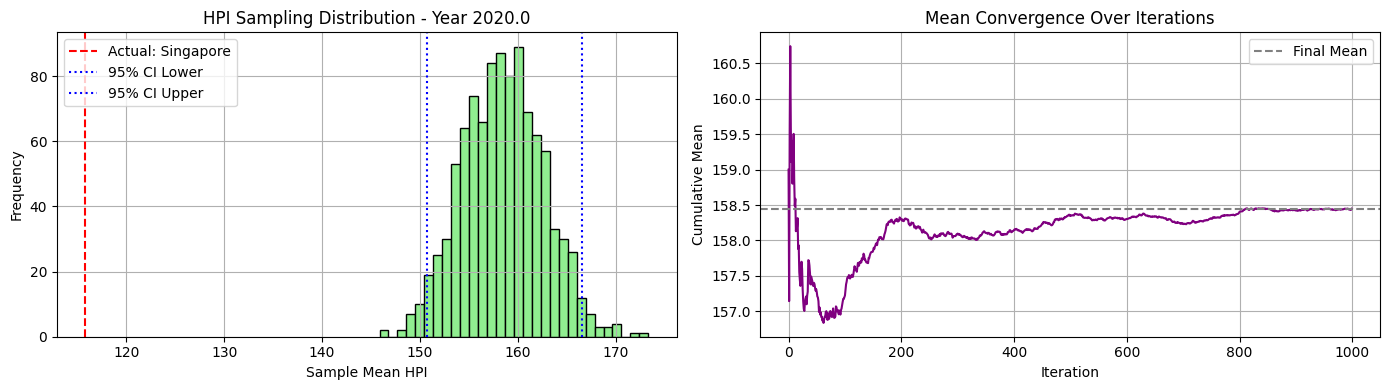


📅 Year 2021.0 - Available HPI values for sampling:
[165.39 180.02 214.88 193.46 152.2  124.38 181.28 222.1  248.26 176.65
 112.34 200.69 201.94 147.93 175.91 173.6  211.74 139.92 112.34 166.04
 166.82 112.34 181.79 145.16 164.23 248.26 150.58 188.56]


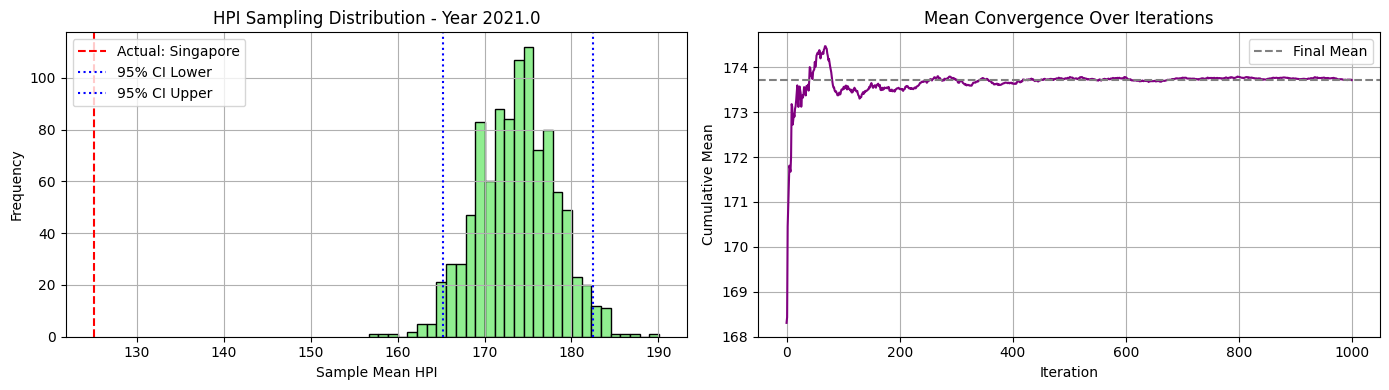


📅 Year 2022.0 - Available HPI values for sampling:
[179.02 185.16 235.32 226.15 151.49 132.1  190.42 271.5  292.18 207.16
 118.98 207.75 219.93 167.57 185.13 172.65 223.73 156.43 120.29 191.49
 174.03 118.98 188.27 154.42 169.16 292.18 164.55 213.  ]


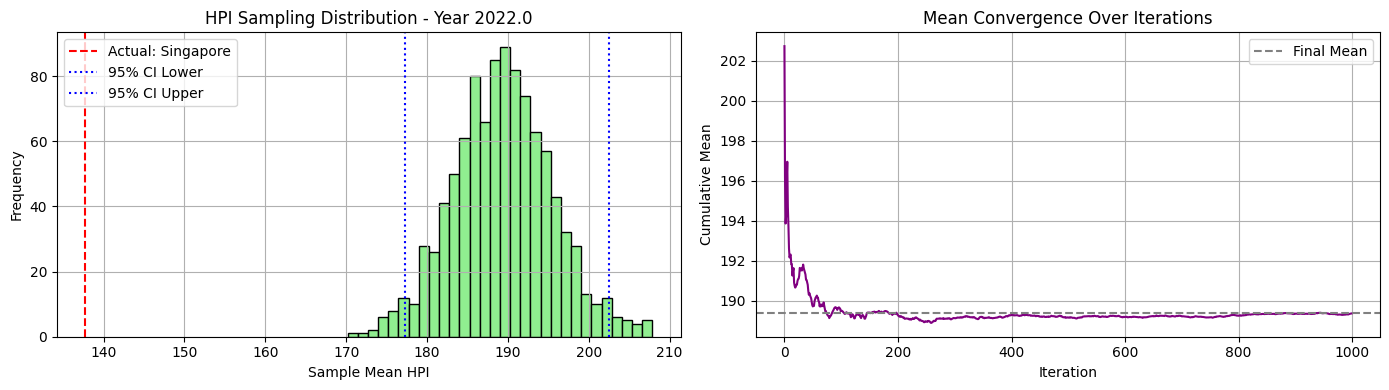


📅 Year 2023.0 - Available HPI values for sampling:
[178.65 191.27 221.05 222.4  151.24 131.52 174.25 290.98 309.37 214.23
 112.27 216.19 243.89 164.36 184.12 175.16 248.04 170.23 124.06 209.99
 176.62 112.27 178.36 157.81 174.79 309.37 165.   221.72]


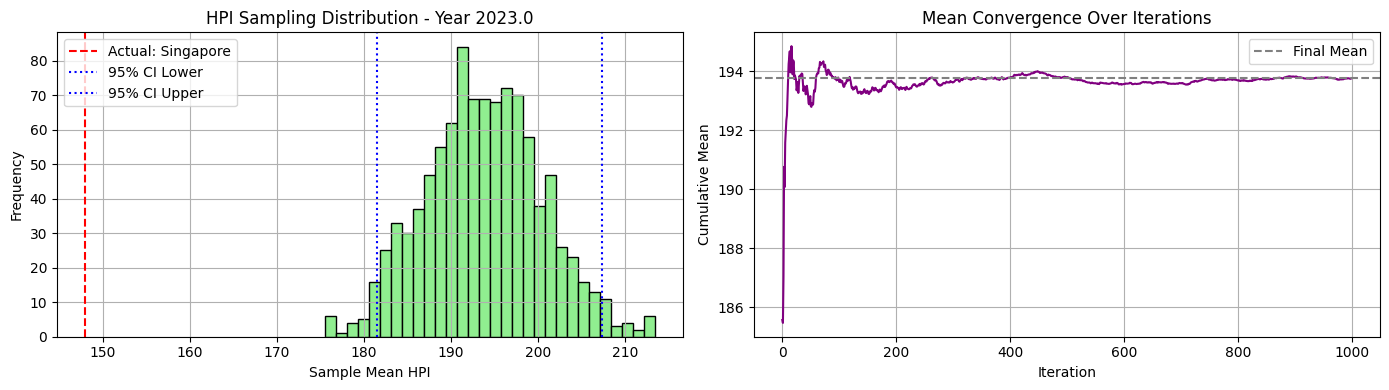


📅 Year 2024.0 - Available HPI values for sampling:
[192.53 203.78 217.35 233.42 156.73 126.68 171.5  328.1  328.24 224.54
 119.1  225.06 266.38 177.7  189.05 175.38 256.03 195.72 130.34 220.7
 178.1  119.1  178.49 160.56 178.06 328.24 166.38 231.23]


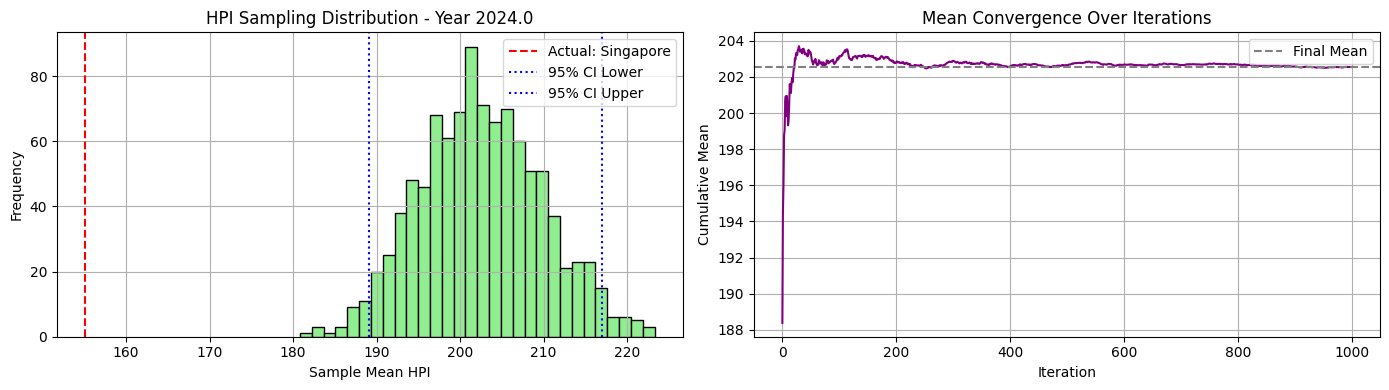

In [118]:
synthetic_04, excluded_04, actual_04 = estimate_hpi_by_cluster_sampling_2(df_hpi_winsorized, df_clusters, cluster_id=1, seed=42, sample_size=60)

🔍 Cluster 2 selected. Excluding country: South-Korea
📊 Sampling from countries: ['Chile', 'Colombia', 'India', 'Japan', 'Russia']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100.]


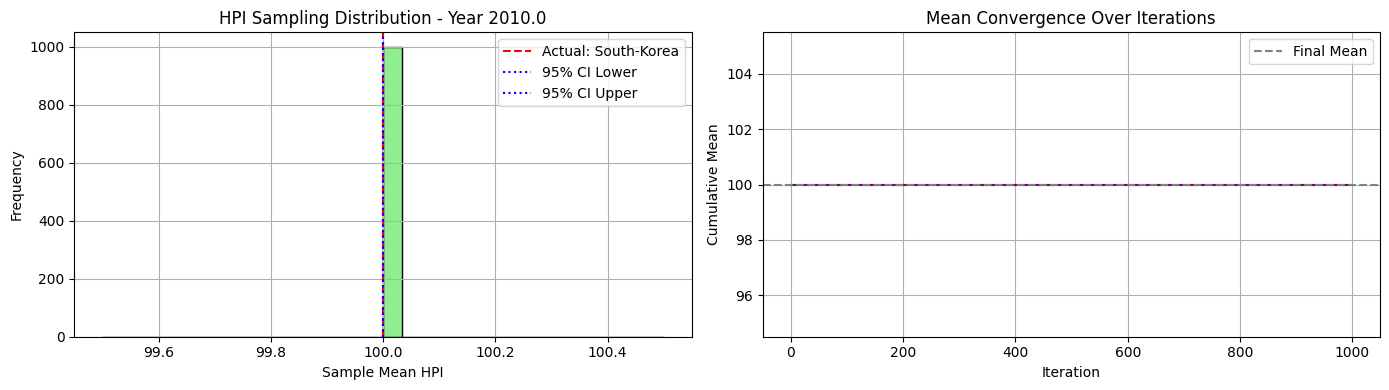


📅 Year 2011.0 - Available HPI values for sampling:
[110.52 107.89 110.52 100.07  94.49]


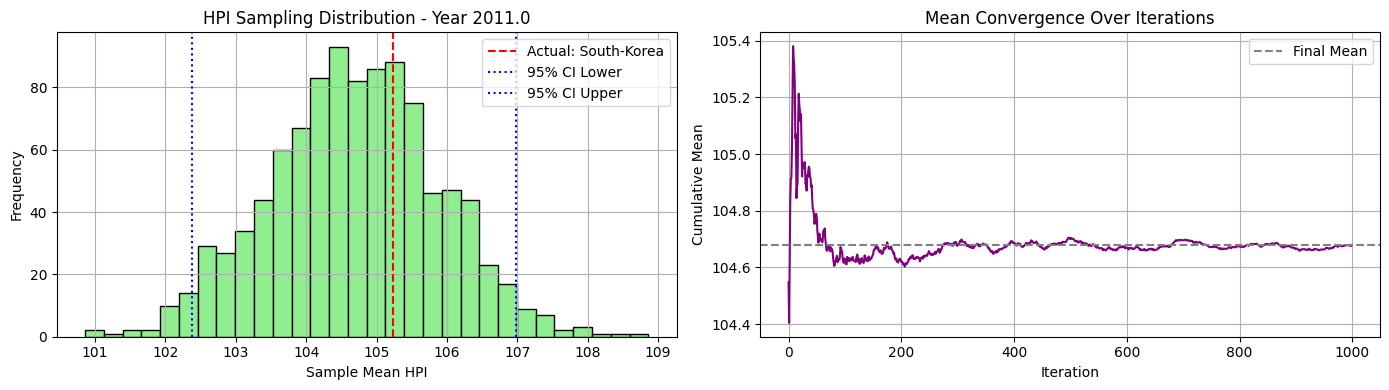


📅 Year 2012.0 - Available HPI values for sampling:
[124.02 118.79 124.02  99.19  91.1 ]


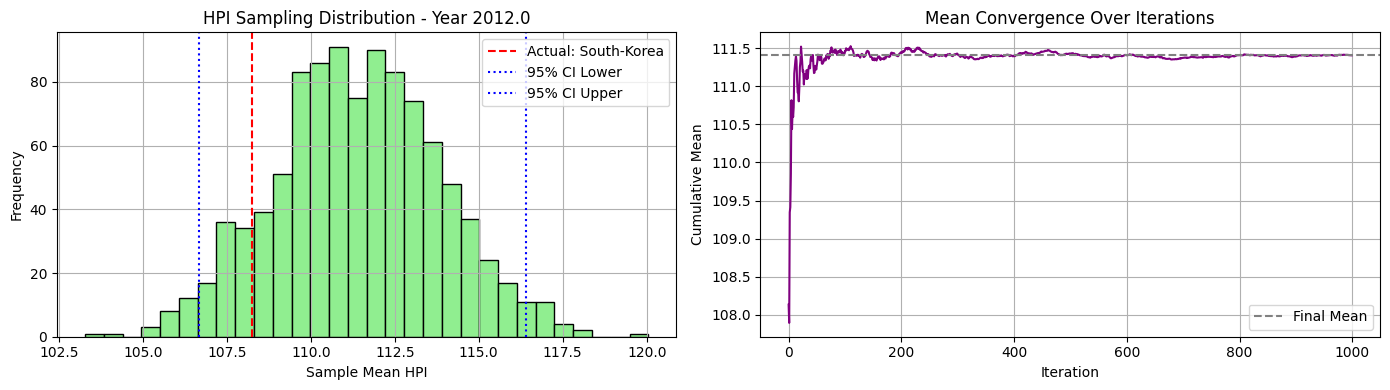


📅 Year 2013.0 - Available HPI values for sampling:
[136.52 130.06 136.52 100.81  94.32]


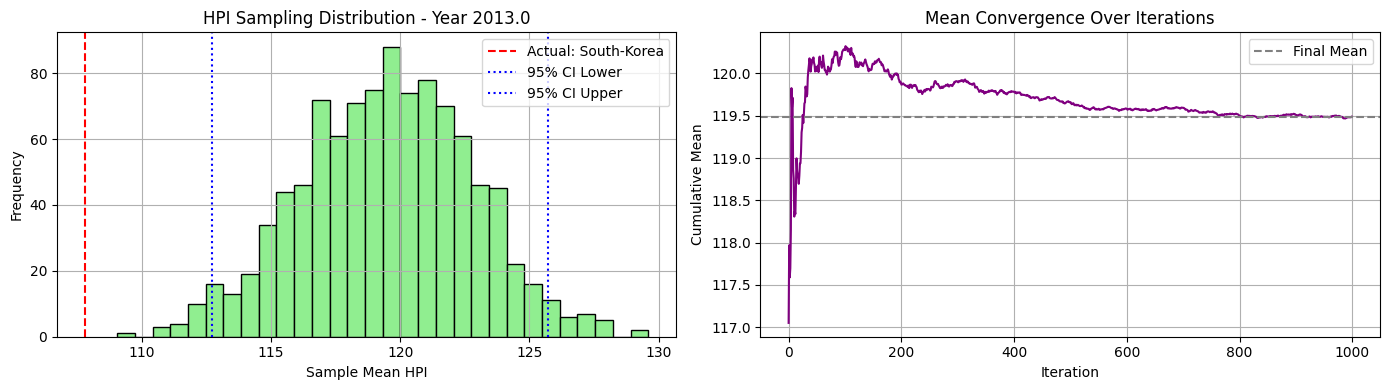


📅 Year 2014.0 - Available HPI values for sampling:
[151.67 140.75 151.67 102.38  95.84]


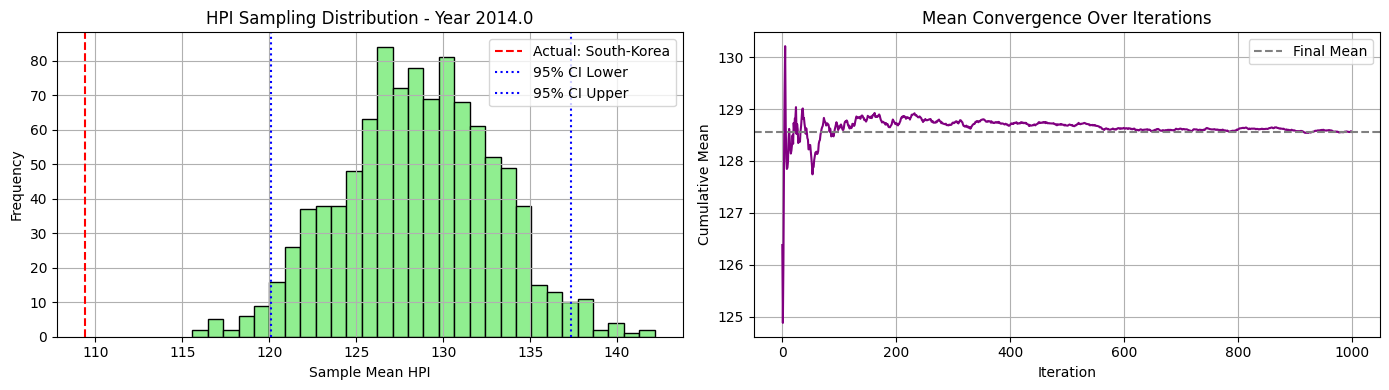


📅 Year 2015.0 - Available HPI values for sampling:
[162.89 152.93 162.89 104.86  97.  ]


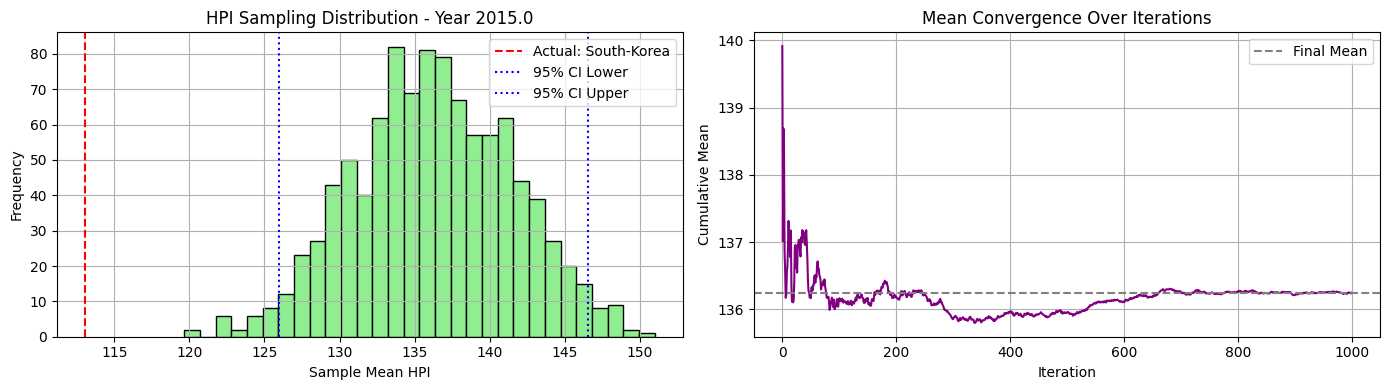


📅 Year 2016.0 - Available HPI values for sampling:
[172.75 167.48 172.75 107.18  91.86]


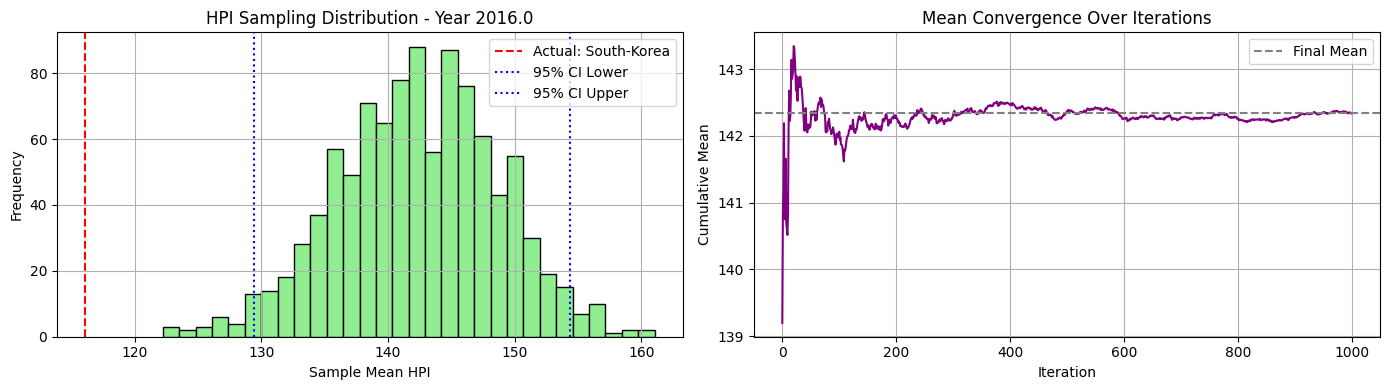


📅 Year 2017.0 - Available HPI values for sampling:
[183.99 178.56 183.99 109.91  88.54]


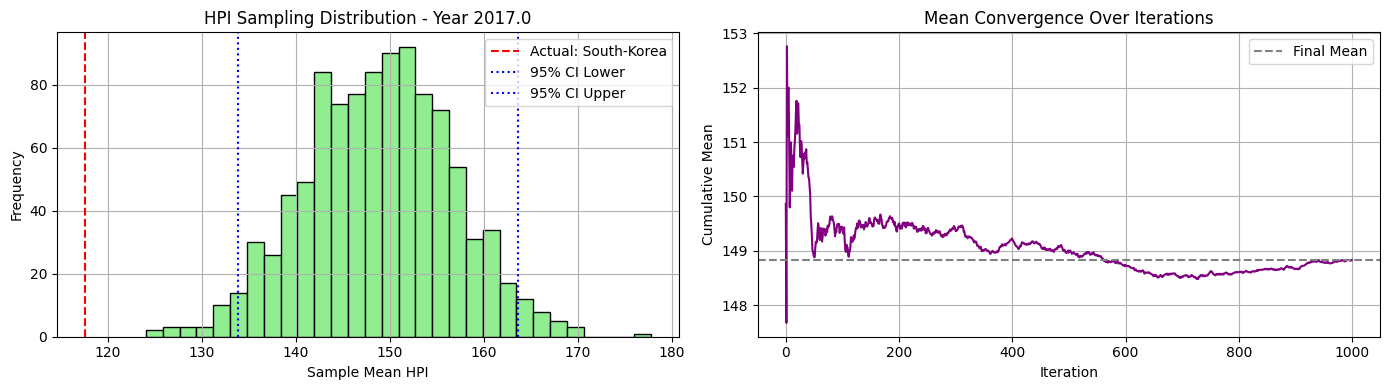


📅 Year 2018.0 - Available HPI values for sampling:
[191.85 188.24 191.85 112.04  90.72]


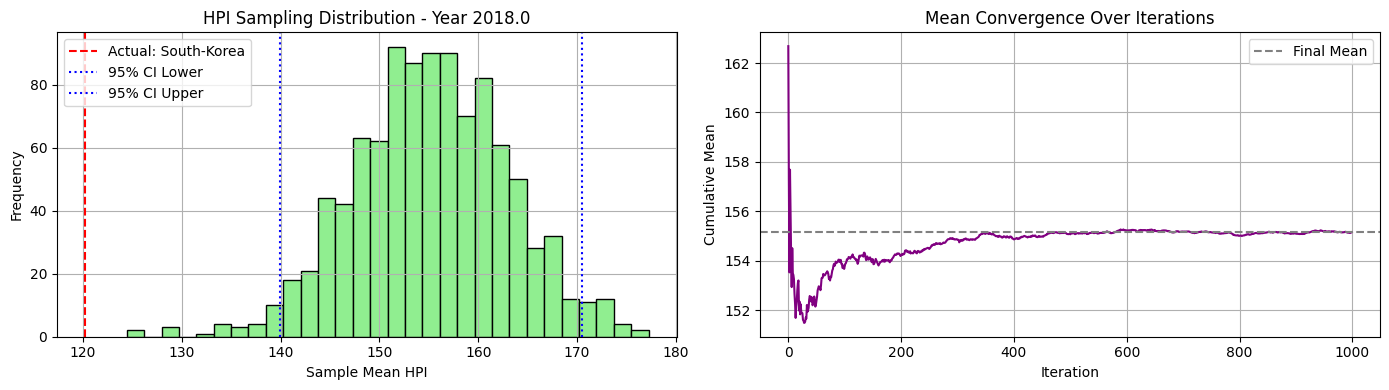


📅 Year 2019.0 - Available HPI values for sampling:
[198.37 198.37 198.37 113.84  97.25]


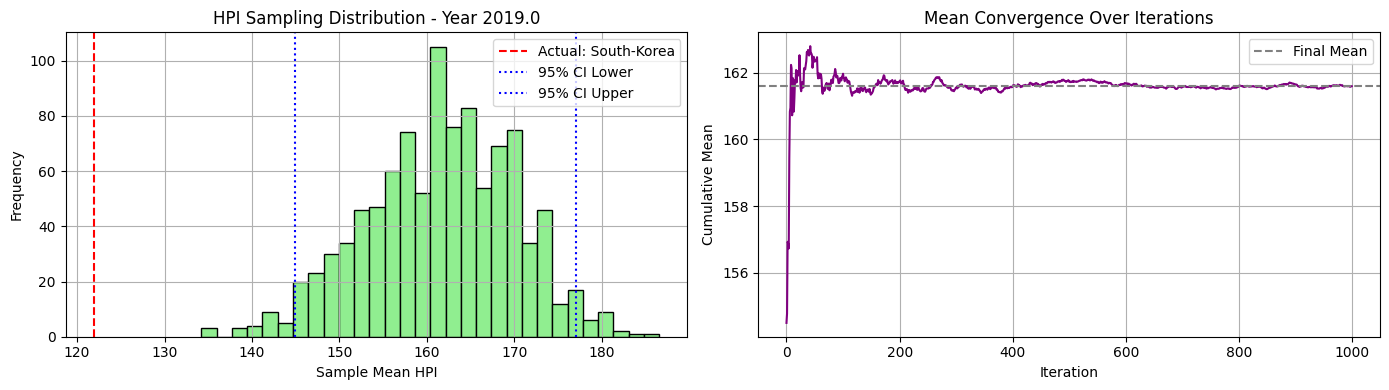


📅 Year 2020.0 - Available HPI values for sampling:
[213.74 203.12 213.74 113.93 106.71]


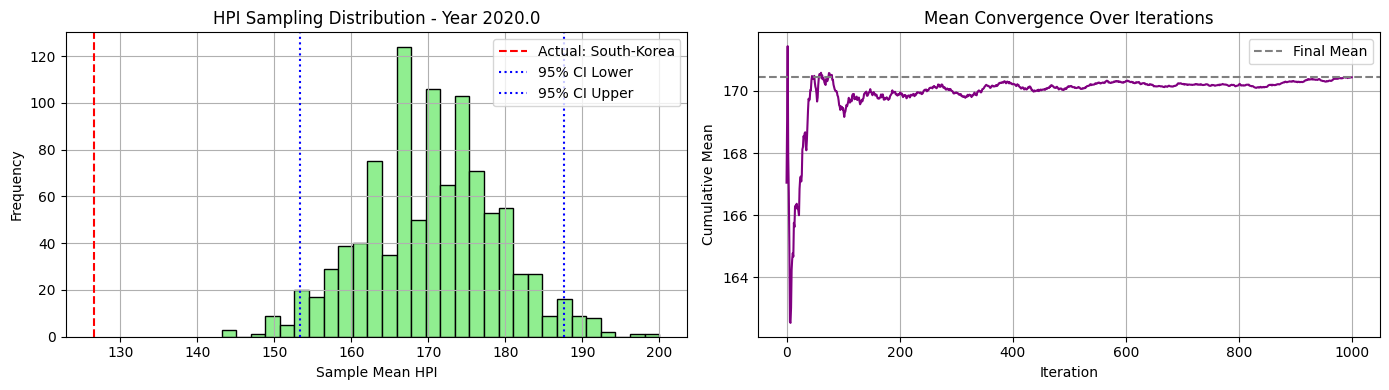


📅 Year 2021.0 - Available HPI values for sampling:
[248.26 214.9  248.26 120.7  121.41]


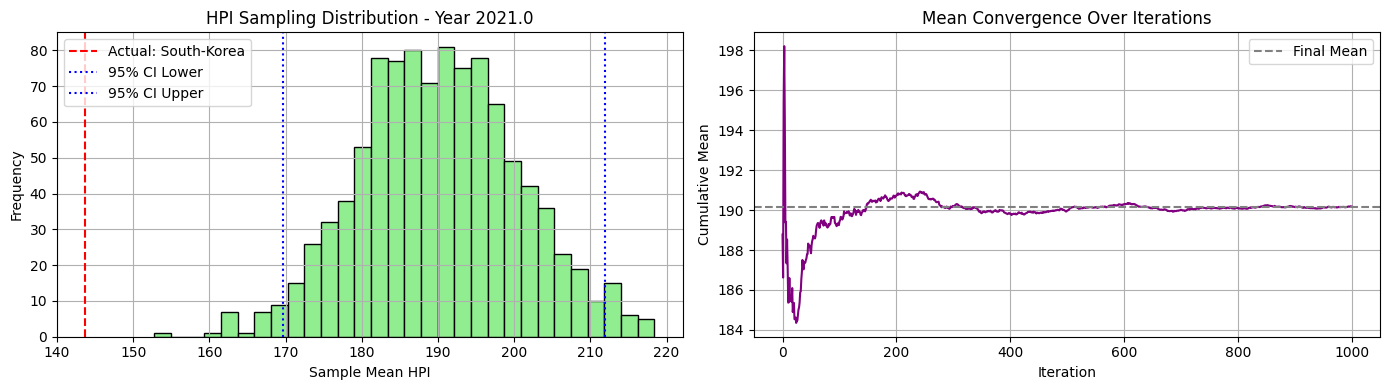


📅 Year 2022.0 - Available HPI values for sampling:
[292.18 230.   292.18 130.84 155.16]


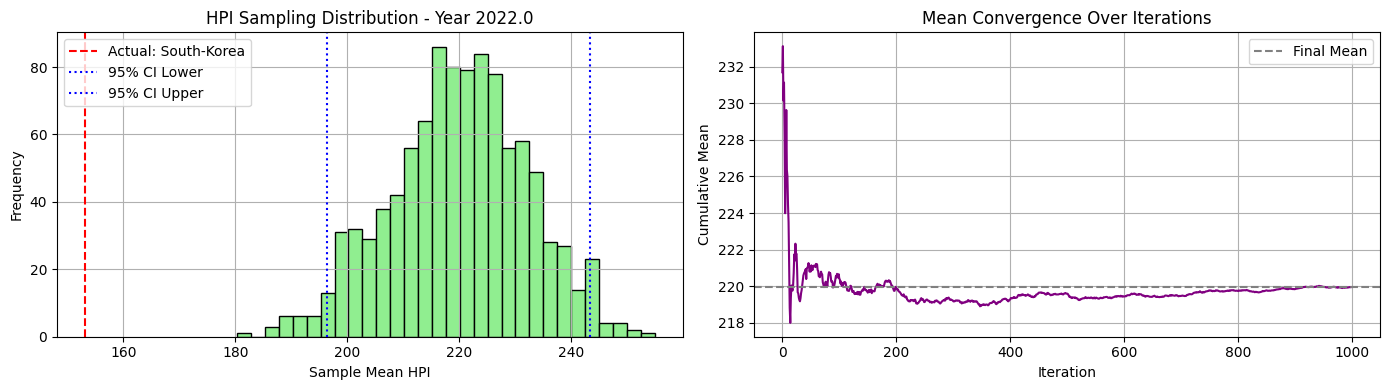


📅 Year 2023.0 - Available HPI values for sampling:
[309.37 245.75 309.37 134.8  157.88]


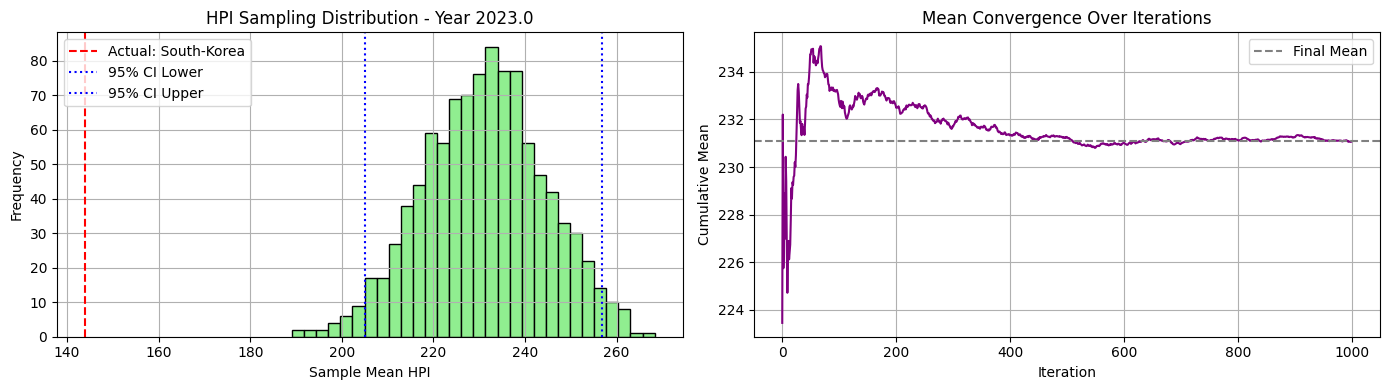


📅 Year 2024.0 - Available HPI values for sampling:
[328.24 269.02 328.24 138.61 186.66]


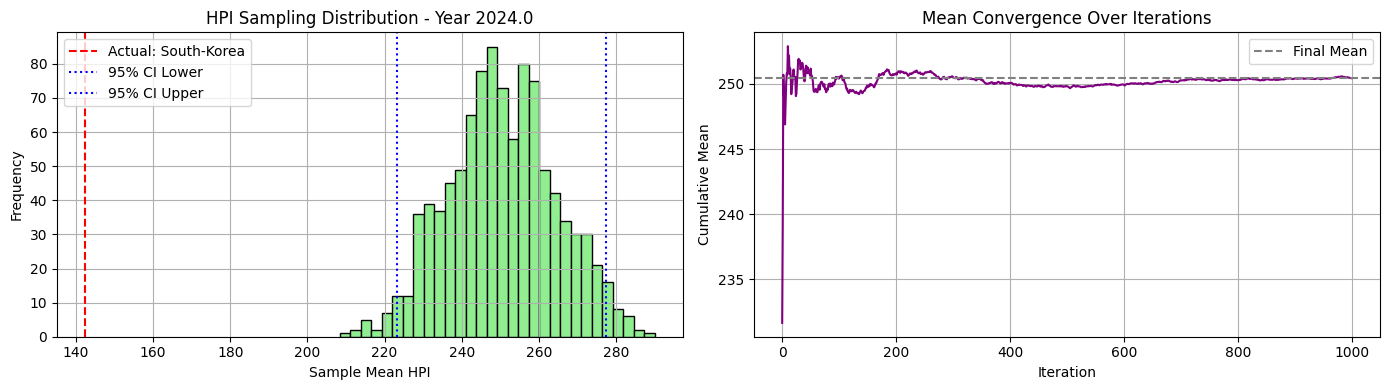

In [121]:
synthetic_05, excluded_05, actual_05 = estimate_hpi_by_cluster_sampling_2(df_hpi_winsorized, df_clusters, cluster_id=2, seed=42)

🔍 Cluster 0 selected. Excluding country: Croatia
📊 Sampling from countries: ['Austria', 'Belgium', 'Bulgaria', 'Cyprus', 'Estonia', 'Finland', 'Greece', 'Ireland', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'New-Zealand', 'Portugal', 'Slovakia', 'Slovenia']

📅 Year 2010.0 - Available HPI values for sampling:
[100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100. 100.
 100. 100.]


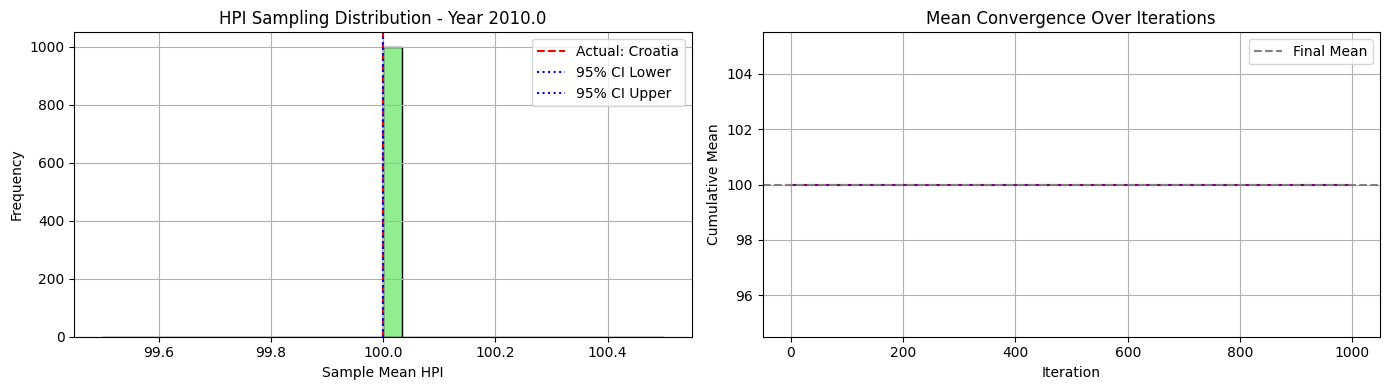


📅 Year 2011.0 - Available HPI values for sampling:
[104.22 103.58  94.49  96.68 108.47 103.17  94.53  94.49 110.42 106.6
 103.68  98.63 100.75  95.1   98.46 102.72]


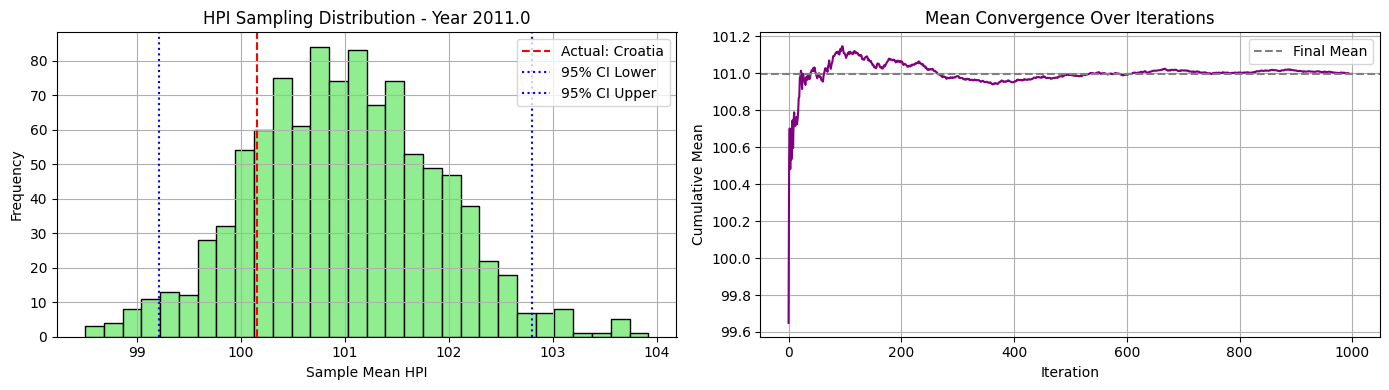


📅 Year 2012.0 - Available HPI values for sampling:
[117.13 106.02  92.69  91.54 116.34 105.64  88.37  88.37 113.71 106.36
 108.03 101.62 105.25  88.37  95.73  95.63]


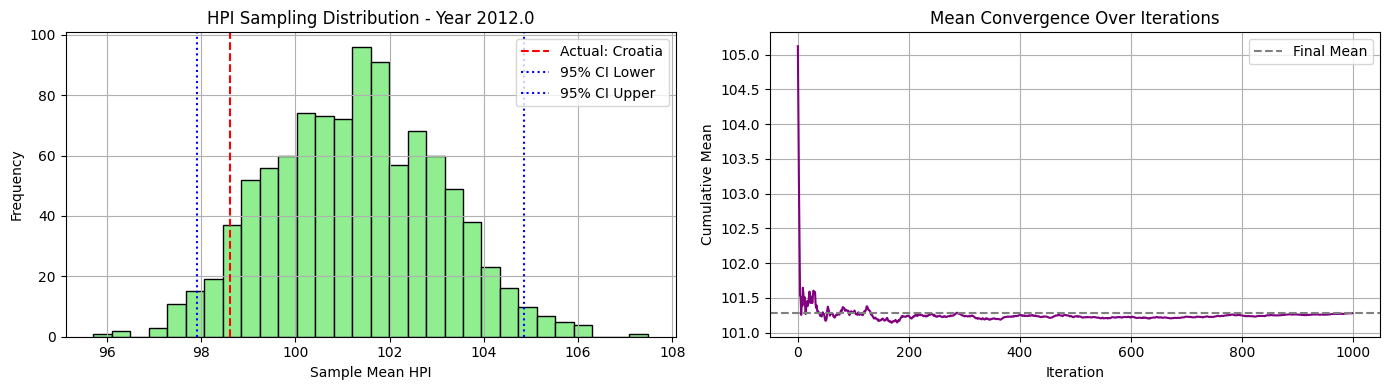


📅 Year 2013.0 - Available HPI values for sampling:
[122.59 107.59  90.65  85.58 128.77 106.87  85.58  85.58 121.5  107.65
 113.42 101.21 114.59  86.7   96.53  90.62]


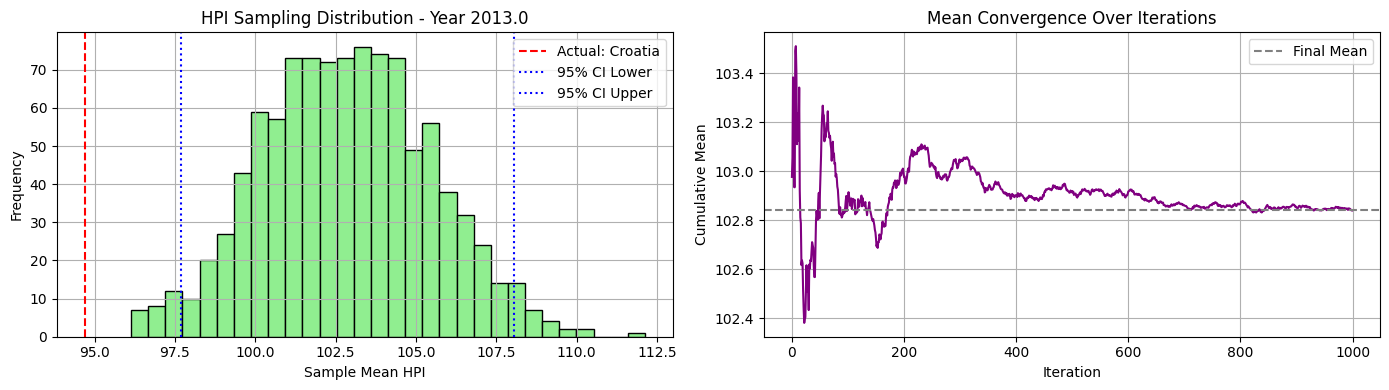


📅 Year 2014.0 - Available HPI values for sampling:
[126.79 107.22  91.95  84.64 146.41 106.5   84.64  84.66 128.78 114.57
 118.39 103.79 122.03  90.38  97.8   84.64]


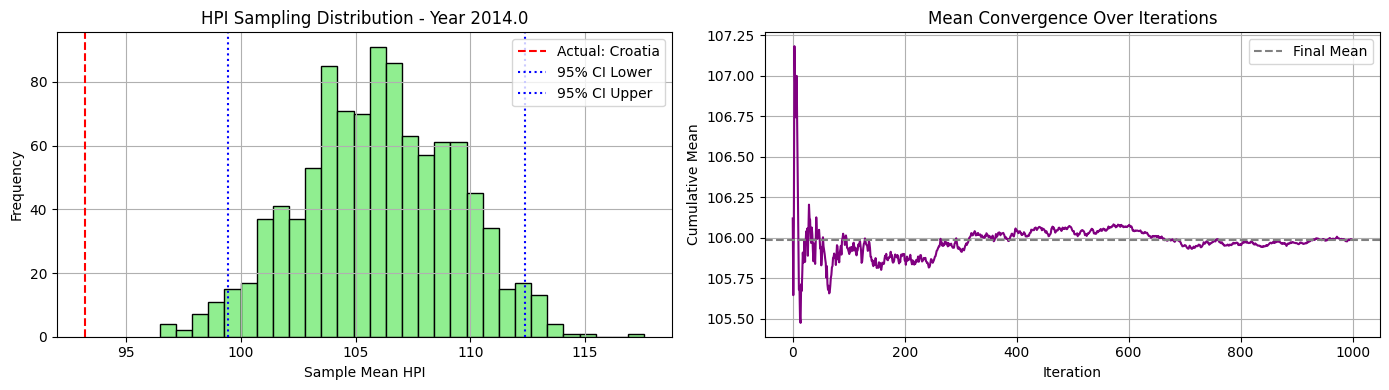


📅 Year 2015.0 - Available HPI values for sampling:
[132.06 109.17  94.51  84.67 156.46 106.5   84.67  94.36 124.46 118.76
 124.78 109.83 137.18  93.15 103.    85.32]


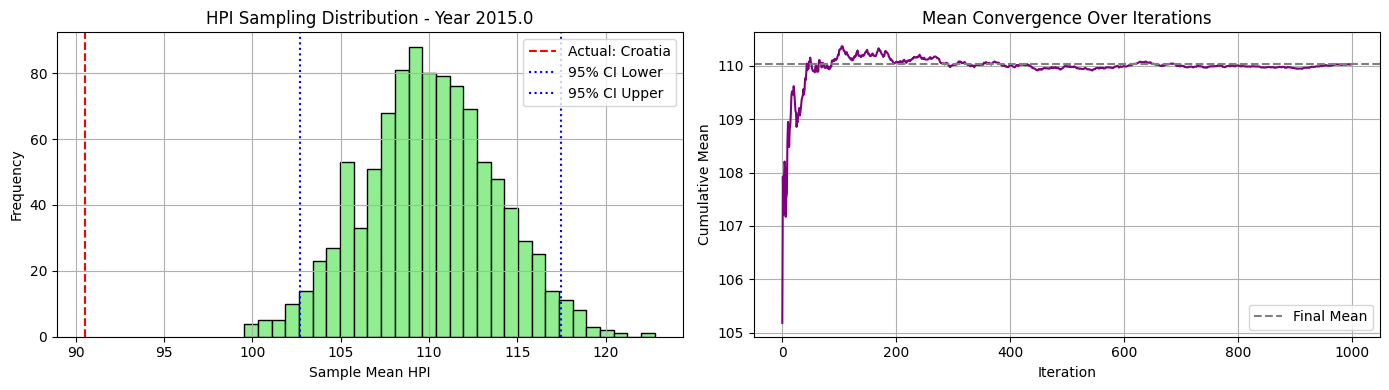


📅 Year 2016.0 - Available HPI values for sampling:
[141.76 111.72 101.15  88.1  163.86 107.86  88.1  101.42 135.02 125.16
 132.28 115.82 156.62  99.78 109.87  88.1 ]


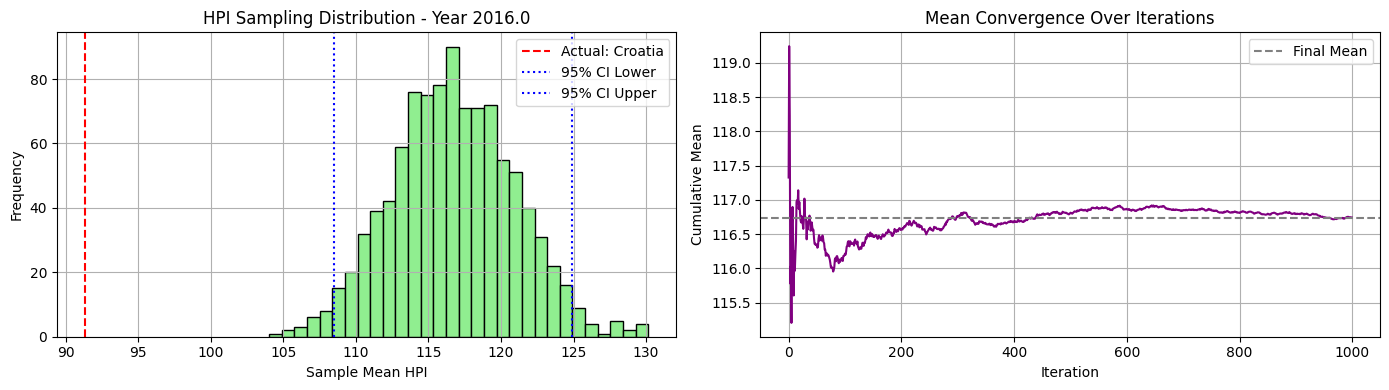


📅 Year 2017.0 - Available HPI values for sampling:
[147.08 115.66 109.91  88.54 172.91 109.02  88.54 112.44 146.87 136.34
 139.69 121.94 166.8  108.99 116.3   95.38]


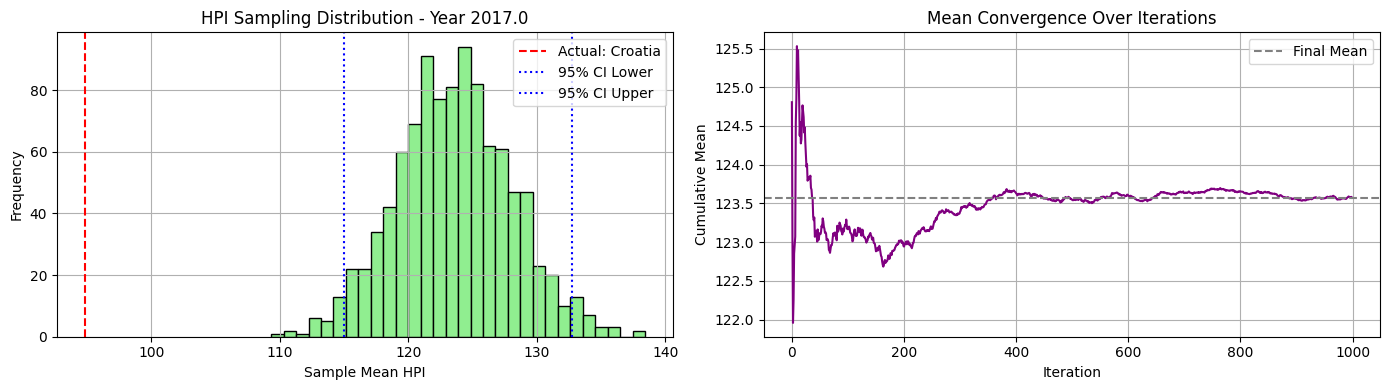


📅 Year 2018.0 - Available HPI values for sampling:
[157.24 119.16 117.15  90.72 183.13 110.06  90.72 123.96 160.92 146.29
 149.55 129.02 172.8  120.19 124.97 103.7 ]


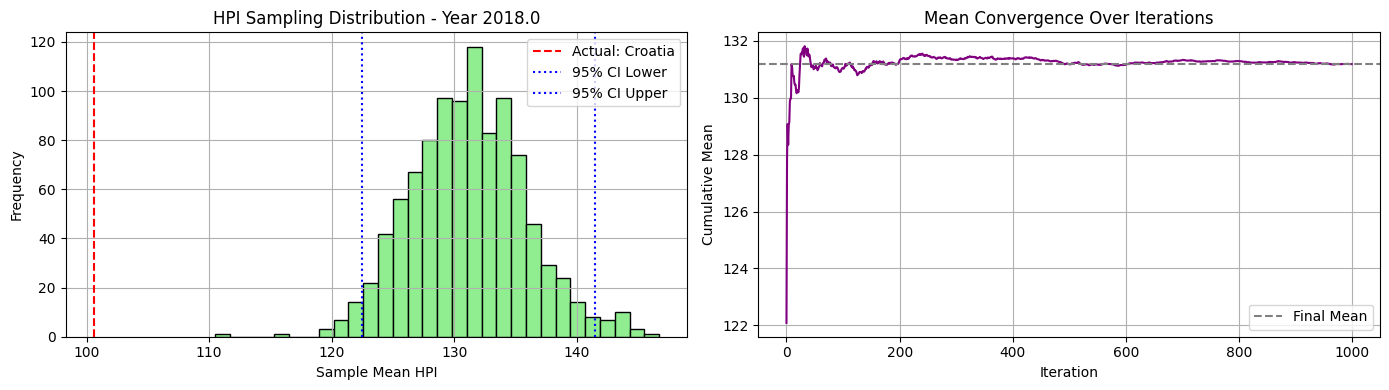


📅 Year 2019.0 - Available HPI values for sampling:
[163.43 123.62 124.2   97.25 195.98 110.52  97.25 126.85 175.33 156.3
 164.68 136.9  178.19 132.16 136.39 110.65]


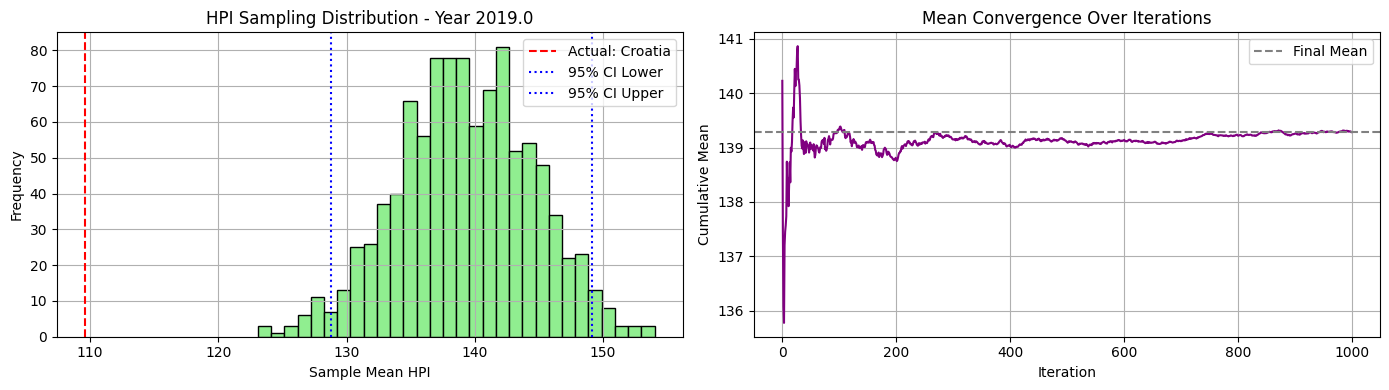


📅 Year 2020.0 - Available HPI values for sampling:
[174.92 128.92 129.87 106.71 207.78 112.49 106.71 127.24 181.42 167.66
 188.57 141.54 196.31 143.75 149.36 115.74]


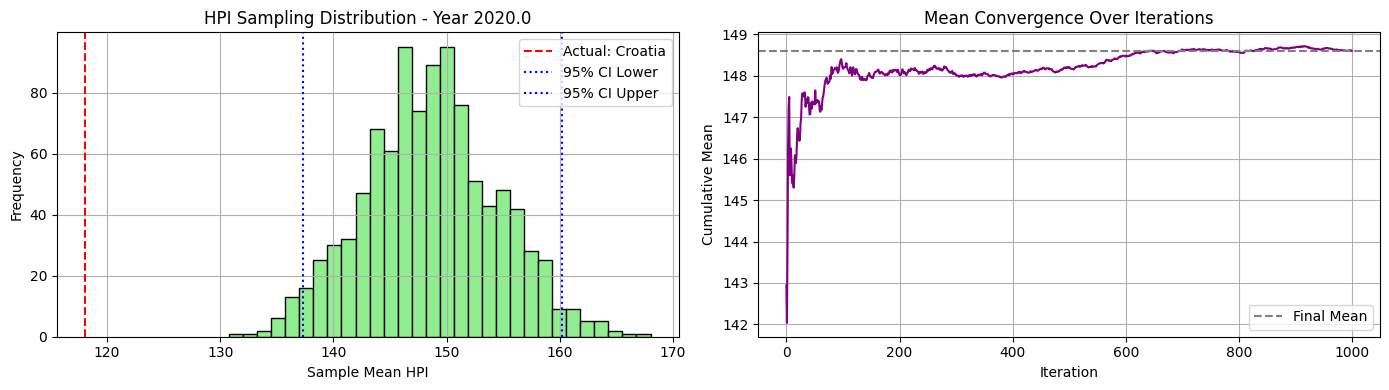


📅 Year 2021.0 - Available HPI values for sampling:
[195.48 137.52 141.14 112.34 239.04 117.62 112.34 137.77 201.18 194.58
 214.81 148.74 248.26 157.27 158.94 129.1 ]


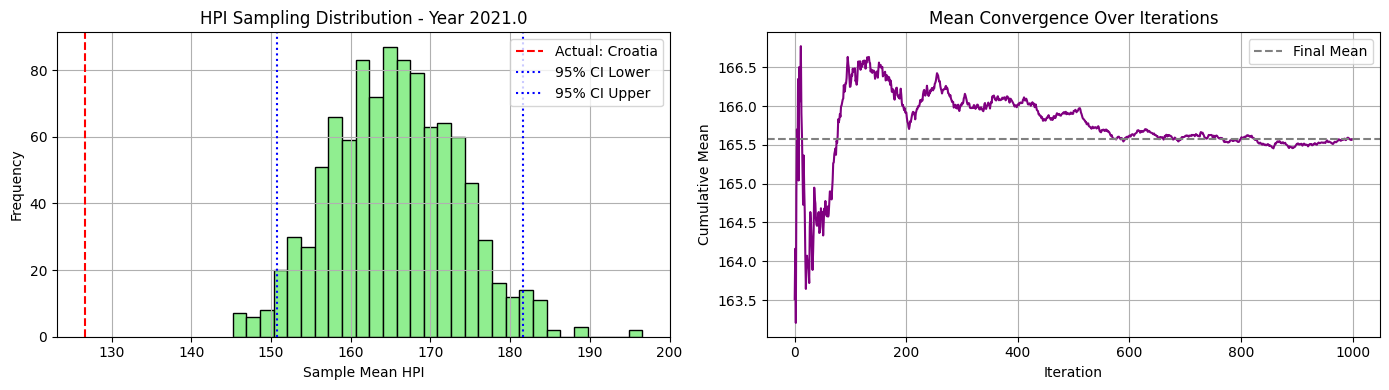


📅 Year 2022.0 - Available HPI values for sampling:
[215.62 145.12 160.59 118.98 292.18 118.98 118.98 154.73 229.01 231.64
 235.34 158.62 249.69 177.14 180.7  148.16]


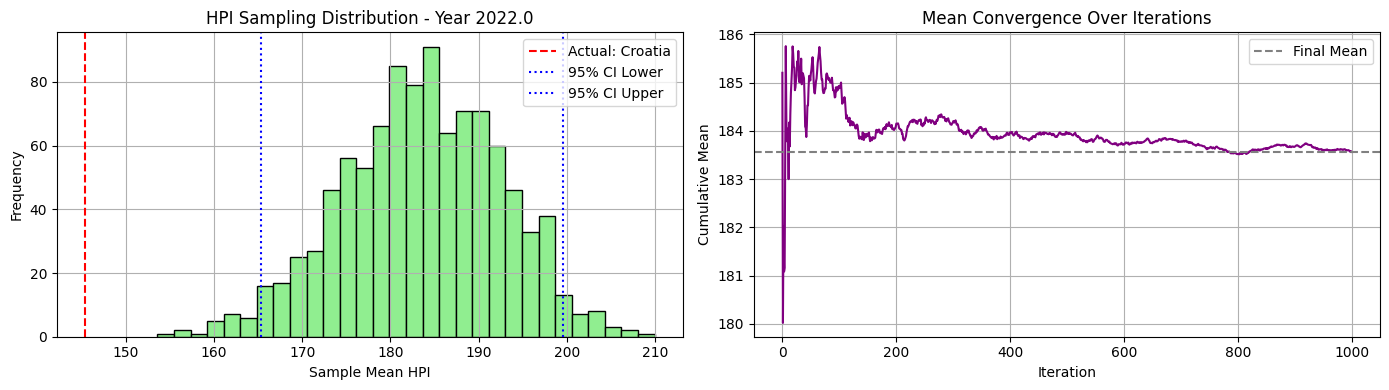


📅 Year 2023.0 - Available HPI values for sampling:
[212.08 148.52 176.43 112.27 309.37 112.27 112.27 159.48 237.56 254.38
 214.   168.5  233.54 191.66 180.36 158.88]


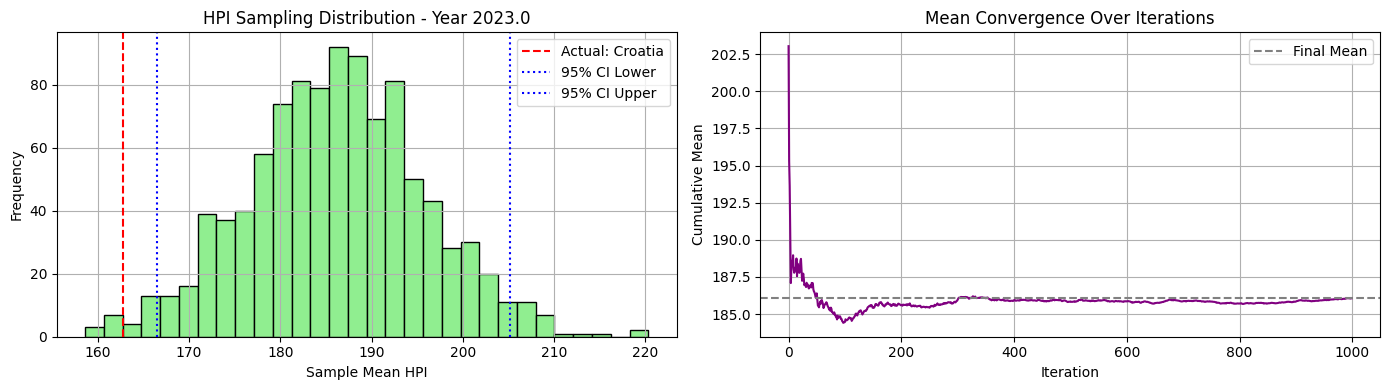


📅 Year 2024.0 - Available HPI values for sampling:
[207.62 153.31 205.53 119.1  328.24 119.1  119.1  173.07 247.54 279.12
 202.74 179.35 233.68 209.06 187.15 170.56]


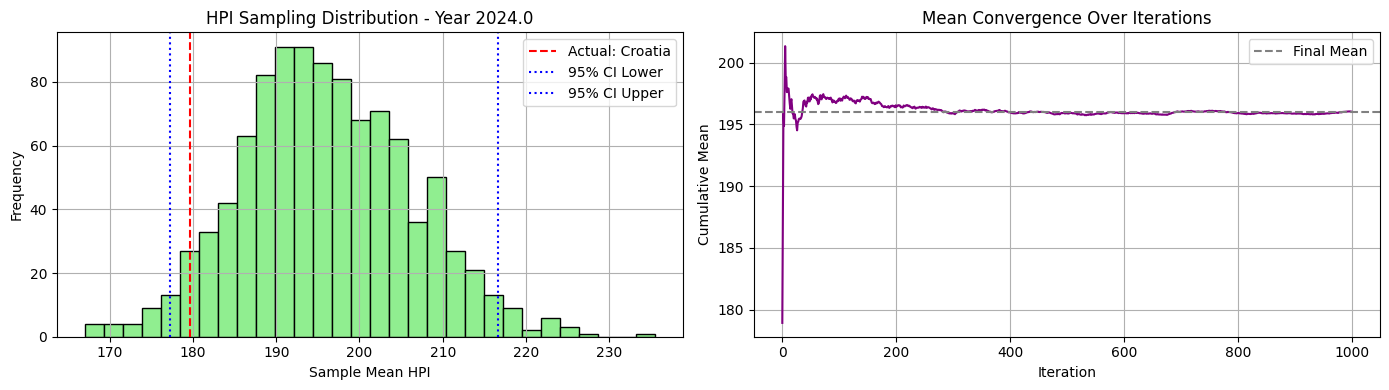

In [122]:
synthetic_06, excluded_06, actual_06 = estimate_hpi_by_cluster_sampling_2(df_hpi_winsorized, df_clusters, cluster_id=0, seed=42)

In [124]:
synthetic_06

{np.float64(2010.0): np.float64(100.0),
 np.float64(2011.0): np.float64(100.99722399999999),
 np.float64(2012.0): np.float64(101.279048),
 np.float64(2013.0): np.float64(102.83997600000001),
 np.float64(2014.0): np.float64(105.986807),
 np.float64(2015.0): np.float64(110.02662366666668),
 np.float64(2016.0): np.float64(116.74386100000001),
 np.float64(2017.0): np.float64(123.57385966666665),
 np.float64(2018.0): np.float64(131.18683033333335),
 np.float64(2019.0): np.float64(139.28692599999997),
 np.float64(2020.0): np.float64(148.59753966666665),
 np.float64(2021.0): np.float64(165.57136500000001),
 np.float64(2022.0): np.float64(183.56576166666665),
 np.float64(2023.0): np.float64(186.06143633333335),
 np.float64(2024.0): np.float64(196.0315436666667)}

In [125]:
actual_06

{np.float64(2010.0): np.float64(100.0),
 np.float64(2011.0): np.float64(100.16),
 np.float64(2012.0): np.float64(98.62),
 np.float64(2013.0): np.float64(94.7),
 np.float64(2014.0): np.float64(93.19),
 np.float64(2015.0): np.float64(90.54),
 np.float64(2016.0): np.float64(91.33),
 np.float64(2017.0): np.float64(94.84),
 np.float64(2018.0): np.float64(100.59),
 np.float64(2019.0): np.float64(109.64),
 np.float64(2020.0): np.float64(118.06),
 np.float64(2021.0): np.float64(126.64),
 np.float64(2022.0): np.float64(145.44),
 np.float64(2023.0): np.float64(162.82),
 np.float64(2024.0): np.float64(179.7)}

In [126]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [127]:
def compute_global_mse_mae(synthetic_dicts, actual_dicts):
    """
    Computes global MSE and MAE across multiple synthetic vs. actual HPI dictionaries.

    Parameters:
    - synthetic_dicts: list of dicts with synthetic HPI values per year
    - actual_dicts: list of dicts with actual HPI values per year

    Returns:
    - mse: Mean Squared Error
    - mae: Mean Absolute Error
    """

    y_true = []
    y_pred = []

    for synth, actual in zip(synthetic_dicts, actual_dicts):
        common_years = set(synth.keys()) & set(actual.keys())
        for year in common_years:
            s_val = synth[year]
            a_val = actual[year]
            if not (np.isnan(s_val) or np.isnan(a_val)):
                y_pred.append(s_val)
                y_true.append(a_val)

    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    return mse, mae

In [128]:
synthetic_list = [synthetic_04, synthetic_05, synthetic_06]
actual_list = [actual_04, actual_05, actual_06]

mse, mae = compute_global_mse_mae(synthetic_list, actual_list)
print(f"Global MSE: {mse:.4f}")
print(f"Global MAE: {mae:.4f}")

Global MSE: 1280.8337
Global MAE: 27.7679


In [132]:
from datetime import datetime

In [133]:
def create_experiment_log():
    columns = [
        'experiment_name', 'experiment_date',
        'clustering_model', 'n_clusters', 'init_method', 'n_init', 'max_iter', 'random_state',
        'used_elbow_method', 'used_silhouette_score', 'silhouette_score',
        'transformations_clustering', 'transformations_sampling',
        'outliers_handling_clustering', 'outliers_handling_sampling',
        'sampling_method', 'mse_score', 'mae_score'
    ]
    return pd.DataFrame(columns=columns)

In [134]:
log_df = create_experiment_log()

log_df.loc[len(log_df)] = {
    'experiment_name': 'baseline_kmeans_random',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 3,
    'init_method': 'random',
    'n_init': 10,
    'max_iter': 100,
    'random_state': 42,
    'used_elbow_method': False,
    'used_silhouette_score': False,
    'silhouette_score': None,
    'transformations_clustering': 'StandardScaler, log transformation',
    'transformations_sampling': 'Winsorization, rounding',
    'outliers_handling_clustering': 'None',
    'outliers_handling_sampling': 'Winsorization',
    'sampling_method': 'mean',
    'mse_score': mse,
    'mae_score': mae
}

In [135]:
log_df

,experiment_name,experiment_date,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,silhouette_score,transformations_clustering,transformations_sampling,outliers_handling_clustering,outliers_handling_sampling,sampling_method,mse_score,mae_score
0,baseline_kmeans_random,2025-09-07 18:52,KMeans,3,random,10,100,42,False,False,None,"StandardScaler, log transformation","Winsorization, rounding",None,Winsorization,mean,1280.833748,27.767857


In [136]:
log_df.to_parquet('../data/log_performance/log_performance_cluster_sampling.parquet')

In [137]:
df_hpi_winsorized.head()

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,...,Slovenia,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom
0,2010,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,...,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
1,2011,97.84,104.22,103.58,110.52,94.49,105.75,110.52,107.89,100.16,...,102.72,103.59,105.23,94.49,102.58,107.51,104.26,108.80,97.24,98.54
2,2012,97.53,117.13,106.02,124.02,92.69,110.62,124.02,118.79,98.62,...,95.63,108.41,108.25,88.37,103.86,113.72,107.63,120.68,101.82,98.92
3,2013,103.99,122.59,107.59,136.52,90.65,112.76,136.52,130.06,94.70,...,90.62,115.41,107.80,85.58,109.22,118.30,115.99,134.46,111.83,101.46
4,2014,113.41,126.79,107.22,151.67,91.95,118.86,151.67,140.75,93.19,...,84.64,123.99,109.43,84.64,119.52,121.46,127.07,151.25,118.88,109.60


In [140]:
def plot_countries(df, exclude_country=None, legend_columns=4):
    """
    Plots country data over years, excluding one country if specified.
    Displays the legend at the top in multiple columns.
    
    Parameters:
    - df: DataFrame with 'Year' and country columns
    - exclude_country: str, name of the country to exclude from the plot
    - legend_columns: int, number of columns in the legend
    """
    plt.figure(figsize=(14, 8))

    # Filter out the excluded country
    country_cols = [col for col in df.columns if col != "Year" and col != exclude_country]

    # Plot each remaining country
    for country in country_cols:
        plt.plot(df["Year"], df[country], label=country)

    plt.xlabel("Year")
    plt.ylabel("Value")
    title = "Yearly Data for Countries"
    if exclude_country:
        title += f" (excluding {exclude_country})"
    plt.title(title)

    # Stylized legend at the top
    plt.legend(loc="right", bbox_to_anchor=(0.3, 1.3),
               ncol=legend_columns, fontsize="small", frameon=False)

    plt.grid(True)
    plt.tight_layout()
    plt.show()

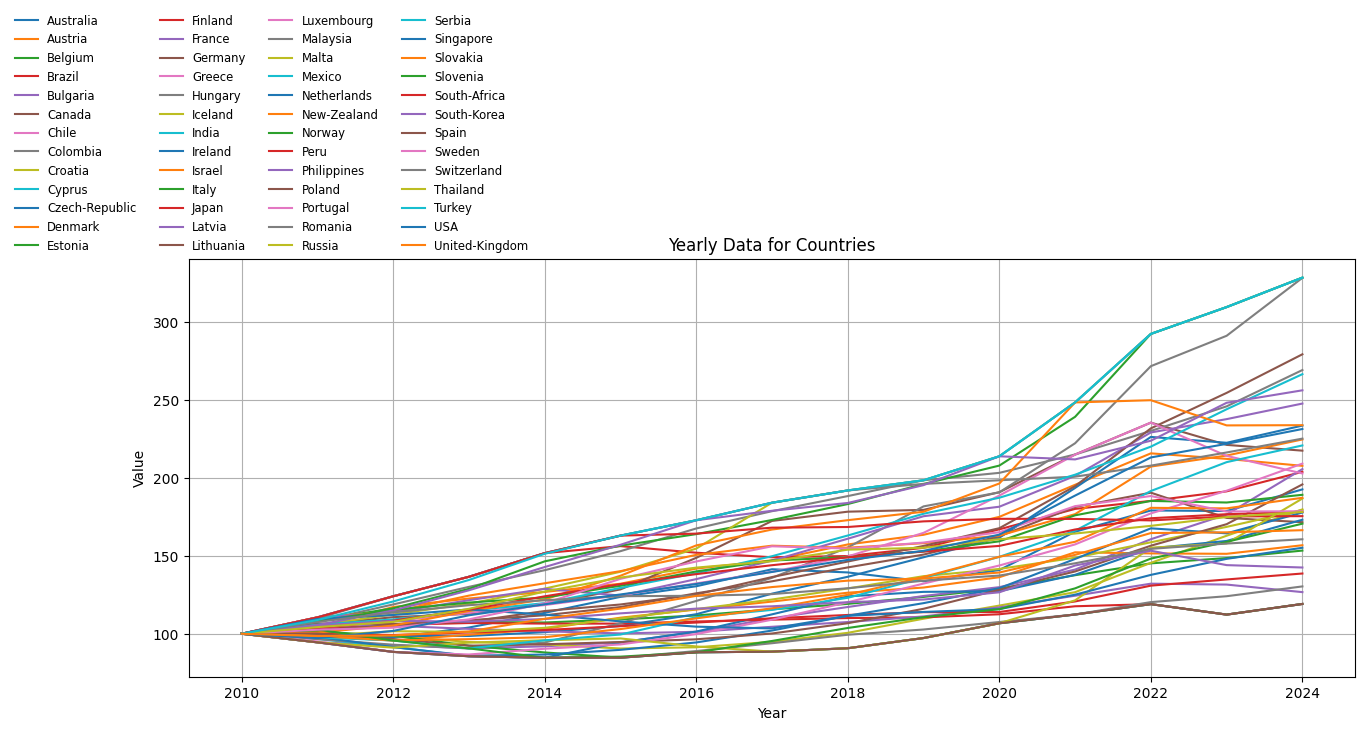

In [141]:
plot_countries(df_hpi_winsorized)

In [142]:
df_hpi_winsorized.to_parquet('../data/winsorized_hpi_values.parquet')